# 01 IEEE TNS 2026 — Reproducible experimental analysis

This notebook contains the experimental model implementations, the original
research plotting functions, and the code needed to regenerate the article's
numerical tables and data-dependent figures. The complete executable functions are in `src/lorenzetti_repro/`.

### Choose one of three execution modes

1. **Published results:** Set `EXECUTION_MODE = 'replay'` and
   `REPLAY_SOURCE = 'original'`. Place the original trusted prediction/result
   pickles in `artifacts/pickles/`. `Run All Cells` recalculates metrics and
   figures from the saved events. No training is required.
2. **New training:** Set `EXECUTION_MODE = 'train'`. The notebook reads the
   Lorenzetti input `data/Lorenzetti_electrons_merge_root.csv` (or extracts it
   from the repository's compressed data archive). The specified models are
   trained and their artifacts saved to a **new unique** directory under
   `artifacts/new_runs/tns/`. No historical files are overwritten.
3. **Replay a new training:** Set `EXECUTION_MODE = 'replay'` and
   `REPLAY_SOURCE = 'latest_new_run'` or `'specific_new_run'`, configuring
   `NEW_RUN_ID` for the latter. The new experiment's pickles are analyzed
   using the same plotting functions.

The figure coverage table near the end reports, by **paper figure number**, all
panels produced from original source cells or saved predictions and identifies
missing input artifacts. Source-dataset diagnostics additionally require the
original Lorenzetti CSV. Historical timing charts require the original measured
prediction times. Original serialized pickle objects should only be loaded
from trusted sources.

**Scientific protocol:** D70/D30 is held separately; in Stages II and III the
5×5 nested CV for `f_ML` is conditional on the representation fitted in D70.
No fit/selection uses the final D30 hold-out. The benchmark is Lorenzetti,
not the official online ATLAS chain.


## 1. Execution environment and source implementations


In [1]:
# Keep PCA/ICA linear algebra from oversubscribing the Jupyter kernel.
# Increase this only after benchmarking the target machine.
from threadpoolctl import threadpool_limits
NUMERICAL_THREADS = 1
_THREADPOOL_CONTROL = threadpool_limits(limits=NUMERICAL_THREADS)

from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image, Code, Markdown

def locate_root():
    # Works with "Run All" either from project root or /notebooks.
    here=Path.cwd().resolve()
    for folder in (here,*here.parents):
        if (folder/'src'/'lorenzetti_repro').is_dir() and (folder/'papers').is_dir():
            return folder
    raise FileNotFoundError('Project root not located. Open this notebook from the extracted GitHub project.')

ROOT=locate_root()
for p in (ROOT,ROOT/'src'):
    if str(p) not in sys.path:sys.path.insert(0,str(p))
from lorenzetti_repro.article_workflow import (find_input_folders,prepare_data_optional,
    load_article_artifacts,analyze_article)
from lorenzetti_repro.article_training import (train_article,ARTICLE_MODELS,REPRESENTATIONS)
from lorenzetti_repro.original_figure_environment import configure_original_figure_style
ORIGINAL_LATEX_AVAILABLE = configure_original_figure_style(require_latex=False)
if not ORIGINAL_LATEX_AVAILABLE:
    print('Publication typography requires LaTeX and dvipng; install them for exact original font rendering.')
print('PROJECT:',ROOT)
print('Available model families:',ARTICLE_MODELS['tns'])
print('Available representations:',len(REPRESENTATIONS['tns']))

PROJECT: C:\Users\paulo\Documents\PAULO-PYTHON-PROGRAMS\DOUTORADO\GBDTE\Lorenzetti-Shower-Simulation
Available model families: ('mlr', 'preg', 'dtree', 'bdt', 'bspl')
Available representations: 17


### Model, representation, statistical and graphical functions


In [2]:
# Scientific implementations and original plotting functions.
SOURCE_FILES=['original_plotting.py', 'original_replay.py', 'models/stage1_segmented.py',
              'models/hybrids.py', 'representations.py', 'model_runner.py',
              'selection.py','statistics.py','article_training.py','original_data_plots.py','timing_recovery.py']
for name in SOURCE_FILES:
    path=ROOT/'src'/'lorenzetti_repro'/name
    assert path.is_file(), f'Missing source module: {path}'
    print(name, ':', len(path.read_text(encoding='utf8').splitlines()), 'lines')
from lorenzetti_repro import original_plotting as original
print('Original experimental plotting functions:',
      ', '.join(['comparison_hist_boxplot_erros','comparison_metric_all',
                'integrated_plots_in_ETA_ET_geral_with_ranges',
                'boxplot_comparison_improved','plot_resolution_curves',
                'lambda_analysis','qq_plot']))


original_plotting.py : 4086 lines
original_replay.py : 592 lines
models/stage1_segmented.py : 44 lines
models/hybrids.py : 100 lines
representations.py : 82 lines
model_runner.py : 36 lines
selection.py : 61 lines
statistics.py : 93 lines
article_training.py : 216 lines
original_data_plots.py : 38 lines
timing_recovery.py : 74 lines
Original experimental plotting functions: comparison_hist_boxplot_erros, comparison_metric_all, integrated_plots_in_ETA_ET_geral_with_ranges, boxplot_comparison_improved, plot_resolution_curves, lambda_analysis, qq_plot


## 2. Lorenzetti input dataset and saved experiment artifacts


In [3]:
# Locate and extract the Lorenzetti dataset (not required to replay saved predictions).
# Load pickle archives only if they originate from your trusted research environment.
EXTRACT_DATA = True
TRUST_MY_PICKLES = True

from lorenzetti_repro.legacy_artifacts import catalog
PICKLE_DIR, DATA_DIR = find_input_folders(ROOT)
print('Dataset directory:', DATA_DIR)
print('Pickle directory:', PICKLE_DIR)
DATA_CSV = prepare_data_optional(ROOT, extract=False)
if DATA_CSV:
    print('Lorenzetti CSV:', DATA_CSV)
elif EXTRACT_DATA:
    try:
        DATA_CSV = prepare_data_optional(ROOT, extract=True)
        print('Extracted Lorenzetti CSV:', DATA_CSV)
    except (FileNotFoundError, ValueError, RuntimeError) as exc:
        # Dataset is not needed for replay of per-event predictions saved in pickles.
        # It IS mandatory to retrain and for original-dataset feature-relevance plots.
        raise FileNotFoundError(
            'Lorenzetti source events are required for the pre-training figures. '
            'Place the compressed original dataset or Lorenzetti_electrons_merge_root.csv '
            'inside Data/ in the local clone and ensure Git LFS files have been downloaded. '
            f'Dataset discovery details: {type(exc).__name__}: {exc}'
        ) from exc
if DATA_CSV is not None:
    from lorenzetti_repro.dataset import read_dataset, EXPECTED_EVENTS
    data_schema = read_dataset(DATA_CSV)
    print('Dataset:', len(data_schema), 'events /', len(data_schema.columns), 'columns')
    if len(data_schema) != EXPECTED_EVENTS:
        print('WARNING: event count differs from the thesis benchmark:', EXPECTED_EVENTS)
    del data_schema

# Windows may hide the final .zip extension of files such as BDT_noSEG_Full_DF.pkl.zip.
# Expand only the article's known, individually ZIP-wrapped DataFrame files.
# Never unpack the very large *_noSEG_times.pkl model-object archives automatically.
EXTRACT_ZIPPED_PICKLES = True
if EXTRACT_ZIPPED_PICKLES and TRUST_MY_PICKLES and PICKLE_DIR.is_dir():
    import zipfile, shutil
    from lorenzetti_repro.legacy_artifacts import ARTICLE_METHODS
    allowed_methods = set(ARTICLE_METHODS['tns'])
    unpacked_wrappers = []
    for wrapper in sorted(PICKLE_DIR.rglob('*.zip')):
        expected_filename = wrapper.name[:-4]
        if not expected_filename.lower().endswith(('.pkl', '.pkl.gz')):
            continue
        if not any(expected_filename.startswith(m + '_') or expected_filename.startswith('result_' + m + '_') or expected_filename.startswith('integrated_result_' + m + '_') for m in allowed_methods):
            continue
        if expected_filename.endswith('_noSEG_times.pkl') or expected_filename.endswith('_noSEG_times.pkl.gz'):
            continue
        destination = PICKLE_DIR/expected_filename
        if destination.exists():
            continue
        with zipfile.ZipFile(wrapper) as archive:
            candidates = [item for item in archive.infolist() if not item.is_dir()
                          and Path(item.filename).name == expected_filename]
            if len(candidates) != 1:
                print('ZIP wrapper does not contain a uniquely named pickle:', wrapper.name)
                continue
            if candidates[0].file_size > 900_000_000:
                print('Large wrapped file not unpacked automatically:', wrapper.name)
                continue
            with archive.open(candidates[0], 'r') as source, destination.open('xb') as output:
                shutil.copyfileobj(source, output)
            unpacked_wrappers.append(destination.name)
    if unpacked_wrappers:
        print('Unpacked ZIP-wrapped DataFrame results:', unpacked_wrappers)

ARTIFACTS = pd.DataFrame(catalog(PICKLE_DIR, checksum=False))
if not ARTIFACTS.empty:
    print('Saved artifact files:', len(ARTIFACTS))
    display(ARTIFACTS[['method', 'kind', 'relative_path', 'bytes']])
else:
    print('No .pkl or .pkl.gz artifacts found in:', PICKLE_DIR)
    print('Copy your original saved results under artifacts/pickles/ without renaming files.')
    wrapped = sorted(p for p in PICKLE_DIR.rglob('*.zip') if p.is_file()) if PICKLE_DIR.is_dir() else []
    if wrapped:
        print('Detected ZIP-wrapped pickles; extract their contents first:', [p.name for p in wrapped[:10]])

Dataset directory: C:\Users\paulo\Documents\PAULO-PYTHON-PROGRAMS\DOUTORADO\GBDTE\Lorenzetti-Shower-Simulation\Data
Pickle directory: C:\Users\paulo\Documents\PAULO-PYTHON-PROGRAMS\DOUTORADO\GBDTE\Lorenzetti-Shower-Simulation\artifacts\pickles
Lorenzetti CSV: C:\Users\paulo\Documents\PAULO-PYTHON-PROGRAMS\DOUTORADO\GBDTE\Lorenzetti-Shower-Simulation\Data\Lorenzetti_electrons_merge_root.csv
Dataset: 396590 events / 108 columns
Saved artifact files: 88


,method,kind,relative_path,bytes
0,BDT,noSEG_cv_metrics_df,BDT_noSEG_cv_metrics_df.pkl.gz,2587
1,BDT,noSEG_erros_data,BDT_noSEG_erros_data.pkl.gz,12362253
2,BDT,noSEG_erros_data_alpha,BDT_noSEG_erros_data_alpha.pkl.gz,11996105
3,BDT,noSEG_Full_DF,BDT_noSEG_Full_DF.pkl.gz,52036597
4,BDT,noSEG_performance_metrics,BDT_noSEG_performance_metrics.pkl.gz,4302
...,...,...,...,...
83,SGNN,noSEG_erros_data,SGNN_noSEG_erros_data.pkl.gz,12206237
84,SGNN,noSEG_erros_data_alpha,SGNN_noSEG_erros_data_alpha.pkl.gz,12056063
85,SGNN,noSEG_Full_DF,SGNN_noSEG_Full_DF.pkl.gz,46220120
86,SGNN,noSEG_performance_metrics,SGNN_noSEG_performance_metrics.pkl.gz,4386


## 3. Experimental training and persistence


In [4]:
# Execution mode: 'replay' uses the original saved predictions (no model training).
# To fit models from scratch, set EXECUTION_MODE='train' and list the pairs below.
EXECUTION_MODE = 'replay'  # 'replay' or 'train'; never silently start training
ARTICLE = 'tns'
REPLAY_SOURCE = 'original'  # 'original', 'latest_new_run', or 'specific_new_run'
NEW_RUN_ID = None  # e.g. '20261106T150001_000001Z_a1b2c3d4' for specific_new_run
TRAIN_SELECTION = 'nested'
TRAIN_CONFIGURATIONS = None  # e.g. [('bdt', 'PCA-10')]; None = stage model sweep
PERSIST_MODELS = True

from lorenzetti_repro.run_storage import choose_replay_dir, make_new_run
REPLAY_PICKLE_DIR = None
RUN_BASE = None
if EXECUTION_MODE not in ('replay', 'train', 'auto'):
    raise ValueError(f'Invalid EXECUTION_MODE: {EXECUTION_MODE}')
if not TRUST_MY_PICKLES and EXECUTION_MODE != 'train':
    raise PermissionError('Enable TRUST_MY_PICKLES only for research files you personally trust.')

from lorenzetti_repro.legacy_artifacts import ARTICLE_METHODS
if EXECUTION_MODE == 'train':
    if not DATA_CSV:
        DATA_CSV = prepare_data_optional(ROOT, extract=True)
    if not DATA_CSV:
        raise FileNotFoundError('Training needs Lorenzetti_electrons_merge_root.csv under data/ or Data/.')
    RUN_BASE, REPLAY_PICKLE_DIR = make_new_run(ROOT, ARTICLE)
    TRAINED = train_article(ARTICLE, ROOT, DATA_CSV,
                            selection=TRAIN_SELECTION, chosen=TRAIN_CONFIGURATIONS,
                            save_fitted_models=PERSIST_MODELS,
                            output_dir=REPLAY_PICKLE_DIR)
    print('Finished training configurations:', len(TRAINED))
    print('New run archive:', RUN_BASE)
else:
    REPLAY_PICKLE_DIR = choose_replay_dir(ROOT,ARTICLE,REPLAY_SOURCE,NEW_RUN_ID)
    print('Loading experiment results from:', REPLAY_PICKLE_DIR)
    if not REPLAY_PICKLE_DIR.exists():
        raise FileNotFoundError(f'Saved experiment directory not found: {REPLAY_PICKLE_DIR}')


Loading experiment results from: C:\Users\paulo\Documents\PAULO-PYTHON-PROGRAMS\DOUTORADO\GBDTE\Lorenzetti-Shower-Simulation\artifacts\pickles


## 4. Archived results: model predictions and statistical tables


In [5]:
# Retrieve archived results and generate the paper's data-driven figures.
from lorenzetti_repro.article_workflow import load_article_artifacts, historic_method_tables
from lorenzetti_repro.paper_figure_suite import reproduce_paper_figure_set, PAPER_OUTPUTS

PLOT_OUTPUT = ((RUN_BASE/'figures') if RUN_BASE is not None else
    (ROOT/'results'/'replayed'/ARTICLE/'paper_figures' if REPLAY_SOURCE == 'original'
    else REPLAY_PICKLE_DIR.parent/'figures'))
PLOT_OUTPUT.mkdir(parents=True, exist_ok=True)
folder, inventory, bundles, event_frames = load_article_artifacts(
    ARTICLE, ROOT, trust_local_pickle=TRUST_MY_PICKLES, pickle_dir=REPLAY_PICKLE_DIR)
print('Available stored model families:', list(bundles))
print('Event-level prediction configurations:', len(event_frames))
if event_frames:
    display(pd.DataFrame([{'configuration':key, 'events':len(frame)}
                          for key,frame in sorted(event_frames.items())]))
ARCHIVED_TABLES, TABLE_FILES = historic_method_tables(bundles, PLOT_OUTPUT.parent/'tables')
for name,table in ARCHIVED_TABLES.items():
    print('Archived table:',name, 'rows:',len(table))
    display(table)

# Fitted models inside *_times.pkl are optional; numeric measured times are
# extracted separately and never substituted with a benchmark guess.
TIME_CSV = ROOT/'artifacts'/'metadata'/'prediction_times.csv'
if REPLAY_SOURCE == 'original' and RUN_BASE is None and TRUST_MY_PICKLES:
    from lorenzetti_repro.timing_recovery import recover_timing_csv
    try:
        TIME_CSV = recover_timing_csv(ARTICLE, PICKLE_DIR, TIME_CSV, trusted=True)
        print('Measured numeric times:',TIME_CSV)
    except (FileNotFoundError, ValueError, TypeError, AttributeError, ImportError, ModuleNotFoundError) as exc:
        print('Original timing data unavailable:',type(exc).__name__,str(exc))

PAPER_REPORT = reproduce_paper_figure_set(
    ARTICLE, event_frames, bundles, PLOT_OUTPUT,
    data_csv=DATA_CSV, timing_csv=TIME_CSV if TIME_CSV.is_file() else None,
    new_run=(RUN_BASE is not None or REPLAY_SOURCE != 'original'),
)
ORIGINAL_REPORT = PAPER_REPORT['original_report']
# Numerical tables from the original post-training comparisons.
RESULT_TABLES = PAPER_REPORT['supplementary_report'].get('tables', {})
for name, location in RESULT_TABLES.items():
    print('Experimental comparison table:', name)
    display(pd.read_csv(location))
print('Generated image files:',len(PAPER_REPORT['files']))
if 'computed_summary' in ORIGINAL_REPORT:
    display(ORIGINAL_REPORT['computed_summary'])
if 'ranking' in ORIGINAL_REPORT:
    display(ORIGINAL_REPORT['ranking'])


Available stored model families: ['MLR', 'PREG', 'DTREE', 'BDT']
Event-level prediction configurations: 72


,configuration,events
0,BDT no-Bin: CORR-10,90786
1,BDT no-Bin: CORR-2,90786
2,BDT no-Bin: CORR-5,90786
3,BDT no-Bin: CORR-50,90786
4,BDT no-Bin: ICA-10,90786
...,...,...
67,PREG no-Bin: PCA-2,90786
68,PREG no-Bin: PCA-5,90786
69,PREG no-Bin: PCA-50,90786
70,PREG no-Bin: Rings/2,90786


Archived table: MLR_noSEG_performance_metrics rows: 19


,Evaluation-Method,Feature-Selection-Method,Selected-Features,Energy Normalized-Error-Mean,Energy Normalized-Error-Sdt,RMSE (MeV),RMSE/E_true_min (%),Correlation Coefficient (%),IQR (MeV),d0 (MeV),...,F-H0: f-ACR (0.05),F-H1: Errfast_var > Errcalib_var,F-H1: IC[Errcalib_var/Errfast_var; 0.95],T-H0: Errfast_mean = Errcalib_mean,T-H0: p-value (0.05),T-H0: t-value (0.05),T-H0: t-critical (0.05),T-H0: t-ACR (0.05),T-H1: Errfast_mean > Errcalib_mean,T-H1: IC[Errfast_mean - Errcalib_mean; 0.95]
0,MLR no-Bin,Standard FastCalo,Rings[1:100],2770.580312,2839.355816,3967.121969,0.79,99.95,2457.106750,4666.415144,...,Not tested,Not tested,[],"True, Standard vs Standard",Not tested,Not tested,Not tested,Not tested,Not tested,[]
1,MLR no-Bin,Rings[1:100],Rings[1:100],-15.937783,4139.371617,4139.402300,0.83,99.89,2254.672549,4713.618536,...,"[0.9870743686522786, 1.013094891082391]",False,"[2.097872402889008, 2.153174959260135]",False,0.0,167.263121,1.959979,"[-1.959978743903855, 1.959978743903855]",True,"[2751.813649305185, 2821.2225419091665]"
2,MLR no-Bin,Rings/2,"[0, 1, 2, 3, 8, 9, 10, 11, 12, 13, 14, 15, 16,...",-28.813853,4075.202465,4075.304329,0.82,99.89,2471.946065,4766.405640,...,"[0.9870743686522786, 1.013094891082391]",False,"[2.0333334989586875, 2.086934728610505]",False,0.0,169.821793,1.959979,"[-1.9599786176900833, 1.9599786176900833]",True,"[2765.2017994950866, 2833.586532230169]"
3,MLR no-Bin,PCA-50,"[pc0, pc1, pc2, pc3, pc4, pc5, pc6, pc7, pc8, ...",-39.833304,3914.972112,3915.174751,0.78,99.91,2560.972453,4678.372926,...,"[0.9870743686522786, 1.013094891082391]",False,"[1.8765821475807738, 1.9260512143642061]",False,0.0,175.094274,1.959978,"[-1.959978310570655, 1.959978310570655]",True,"[2777.471552157106, 2843.3556813223513]"
4,MLR no-Bin,PCA-10,"[pc0, pc1, pc2, pc3, pc4, pc5, pc6, pc7, pc8, ...",-62.454921,4061.694676,4062.174818,0.81,99.90,2652.881780,4851.705473,...,"[0.9870743686522786, 1.013094891082391]",False,"[2.0198763407474365, 2.073122822775162]",False,0.0,172.246731,1.959979,"[-1.9599785913247023, 1.9599785913247023]",True,"[2798.949870939996, 2867.1205954457973]"
5,MLR no-Bin,PCA-5,"[pc0, pc1, pc2, pc3, pc4]",-78.728728,4222.075852,4222.809813,0.84,99.89,2683.959171,5003.574677,...,"[0.9870743686522786, 1.013094891082391]",False,"[2.18254043147906, 2.2400749436247542]",False,0.0,168.732398,1.959979,"[-1.9599789085599222, 1.9599789085599222]",True,"[2813.935898789265, 2884.6821822630623]"
6,MLR no-Bin,PCA-2,"[pc0, pc1]",-14.385910,4160.483905,4160.508776,0.83,99.90,2665.728265,4941.248876,...,"[0.9870743686522786, 1.013094891082391]",False,"[2.119326787469265, 2.1751949084147784]",False,0.0,166.591688,1.959979,"[-1.9599787857438913, 1.9599787857438913]",True,"[2750.0919821096068, 2819.840462998088]"
7,MLR no-Bin,CORR-50,"[74, 75, 73, 72, 76, 8, 77, 81, 9, 10, 80, 11,...",-8.996403,4117.653048,4117.662876,0.82,99.89,2402.943237,4767.523861,...,"[0.9870743686522786, 1.013094891082391]",False,"[2.0759158062450993, 2.1306395590998894]",False,0.0,167.443398,1.959979,"[-1.9599787010173717, 1.9599787010173717]",True,"[2745.0462689453693, 2814.1071617944067]"
8,MLR no-Bin,CORR-10,"[74, 75, 73, 72, 76, 8, 77, 81, 9, 10]",-14.195682,4236.007067,4236.030853,0.85,99.88,2490.302827,4913.813749,...,"[0.9870743686522786, 1.013094891082391]",False,"[2.1969672694845306, 2.2548820912338763]",False,0.0,164.536806,1.959979,"[-1.9599789364773272, 1.9599789364773272]",True,"[2749.2892970393505, 2820.2626925390377]"
9,MLR no-Bin,CORR-5,"[74, 75, 73, 72, 76]",-9.490794,4195.045214,4195.055950,0.84,99.89,2558.433444,4913.662189,...,"[0.9870743686522786, 1.013094891082391]",False,"[2.154683703394943, 2.2114838771351817]",False,0.0,165.360471,1.959979,"[-1.9599788545309027, 1.9599788545309027]",True,"[2744.917556051087, 2815.224657224577]"


Archived table: PREG_noSEG_performance_metrics rows: 19


,Evaluation-Method,Feature-Selection-Method,Selected-Features,Energy Normalized-Error-Mean,Energy Normalized-Error-Sdt,RMSE (MeV),RMSE/E_true_min (%),Correlation Coefficient (%),IQR (MeV),d0 (MeV),...,F-H0: f-ACR (0.05),F-H1: Errfast_var > Errcalib_var,F-H1: IC[Errcalib_var/Errfast_var; 0.95],T-H0: Errfast_mean = Errcalib_mean,T-H0: p-value (0.05),T-H0: t-value (0.05),T-H0: t-critical (0.05),T-H0: t-ACR (0.05),T-H1: Errfast_mean > Errcalib_mean,T-H1: IC[Errfast_mean - Errcalib_mean; 0.95]
0,PREG no-Bin,Standard FastCalo,Rings[1:100],2770.580312,2839.355816,3967.121969,0.79,99.95,2457.106750,4666.415144,...,Not tested,Not tested,[],"True, Standard vs Standard",Not tested,Not tested,Not tested,Not tested,Not tested,[]
1,PREG no-Bin,Rings[1:100],Rings[1:100],21.113064,5773.931473,5773.970074,1.16,99.77,2091.257190,6141.016777,...,"[0.9870743686522786, 1.013094891082391]",False,"[4.081816579478551, 4.189418400815422]",False,0.0,128.752077,1.959982,"[-1.9599819201882271, 1.9599819201882271]",True,"[2700.428110093298, 2798.5063873827607]"
2,PREG no-Bin,Rings/2,"[0, 1, 2, 3, 8, 9, 10, 11, 12, 13, 14, 15, 16,...",7.170000,4693.961431,4693.966907,0.94,99.85,2224.976774,5194.597864,...,"[0.9870743686522786, 1.013094891082391]",False,"[2.6976727717520466, 2.7687868205975446]",False,0.0,151.776207,1.95998,"[-1.9599798657872154, 1.9599798657872154]",True,"[2724.066745143423, 2802.753880175328]"
3,PREG no-Bin,PCA-50,"[pc0, pc1, pc2, pc3, pc4, pc5, pc6, pc7, pc8, ...",-29.738436,3718.434246,3718.553162,0.74,99.90,2522.408207,4493.348504,...,"[0.9870743686522786, 1.013094891082391]",False,"[1.6928966566349992, 1.737523542738807]",False,0.0,180.345199,1.959978,"[-1.9599779562196693, 1.9599779562196693]",True,"[2768.8472995163984, 2831.7901966565123]"
4,PREG no-Bin,PCA-10,"[pc0, pc1, pc2, pc3, pc4, pc5, pc6, pc7, pc8, ...",-40.842613,3285.123046,3285.376926,0.66,99.93,2564.248749,4167.622007,...,"[0.9870743686522786, 1.013094891082391]",False,"[1.3213367580134057, 1.3561688576418902]",False,0.0,195.088545,1.959977,"[-1.959977323903752, 1.959977323903752]",True,"[2782.883091516322, 2839.962759125176]"
5,PREG no-Bin,PCA-5,"[pc0, pc1, pc2, pc3, pc4]",-46.017524,3195.500328,3195.831654,0.64,99.93,2535.923313,4079.736145,...,"[0.9870743686522786, 1.013094891082391]",False,"[1.2502243923553287, 1.2831818805417283]",False,0.0,198.529485,1.959977,"[-1.9599772307043253, 1.9599772307043253]",True,"[2788.599363197589, 2844.5963099888813]"
6,PREG no-Bin,PCA-2,"[pc0, pc1]",114.022504,3296.377589,3298.349033,0.66,99.93,2555.953878,4172.769652,...,"[0.9870743686522786, 1.013094891082391]",False,"[1.3304058342304774, 1.3654770061200006]",False,0.0,183.981189,1.959977,"[-1.9599773367133084, 1.9599773367133084]",True,"[2627.948240501754, 2685.1673765946794]"
7,PREG no-Bin,CORR-50,"[74, 75, 73, 72, 76, 8, 77, 81, 9, 10, 80, 11,...",-26.997759,3695.129770,3695.228395,0.74,99.91,2176.329242,4288.487130,...,"[0.9870743686522786, 1.013094891082391]",False,"[1.671743429715044, 1.7158126901393485]",False,0.0,180.883975,1.959978,"[-1.95997791633552, 1.95997791633552]",True,"[2766.275846990135, 2828.8802962629347]"
8,PREG no-Bin,CORR-10,"[74, 75, 73, 72, 76, 8, 77, 81, 9, 10]",-1.977052,3401.300347,3401.300922,0.68,99.92,2373.646476,4147.655428,...,"[0.9870743686522786, 1.013094891082391]",False,"[1.4164465854766446, 1.4537858998372981]",False,0.0,188.54662,1.959977,"[-1.9599774669151477, 1.9599774669151477]",True,"[2743.2798319021995, 2801.8348978290423]"
9,PREG no-Bin,CORR-5,"[74, 75, 73, 72, 76]",11.565992,3301.678275,3301.698533,0.66,99.92,2491.597291,4136.335366,...,"[0.9870743686522786, 1.013094891082391]",False,"[1.3346879483664087, 1.3698720021728985]",False,0.0,190.900577,1.959977,"[-1.9599773428277205, 1.9599773428277205]",True,"[2730.371777059004, 2787.6568639396933]"


... (21 outputs left out)

,Method-Selection,configuration,IQR (MeV),RMSE (MeV),d0 (GeV),d0,Number of Features,time_ms_per_event,D0,Time (ms)
0,DTREE no-Bin: CORR-10,DTREE no-Bin: CORR-10,1895.013431,2370.568692,3.034909,3034.908866,10,0.000187,0.586824,0.000187
1,DTREE no-Bin: CORR-2,DTREE no-Bin: CORR-2,2222.956640,2718.998536,3.512049,3512.049155,2,0.000059,0.915829,0.000059
2,DTREE no-Bin: CORR-5,DTREE no-Bin: CORR-5,1966.433964,2539.222536,3.211622,3211.621650,5,0.000190,0.676268,0.000190
3,DTREE no-Bin: CORR-50,DTREE no-Bin: CORR-50,1855.929640,2206.167918,2.882994,2882.993533,50,0.000414,0.711951,0.000414
4,DTREE no-Bin: ICA-10,DTREE no-Bin: ICA-10,2093.765283,2241.112139,3.066991,3066.991470,10,0.001624,0.723011,0.001624
5,DTREE no-Bin: ICA-2,DTREE no-Bin: ICA-2,2014.212517,2598.775619,3.287961,3287.960885,2,0.001662,0.726263,0.001662
6,DTREE no-Bin: ICA-5,DTREE no-Bin: ICA-5,1894.926004,2264.794169,2.952971,2952.970909,5,0.001605,0.557564,0.001605
7,DTREE no-Bin: ICA-50,DTREE no-Bin: ICA-50,2103.734083,2932.938903,3.609408,3609.408220,100,0.003566,1.331845,0.003566
8,DTREE no-Bin: MUTI-10,DTREE no-Bin: MUTI-10,1943.595808,2458.994015,3.134361,3134.360578,10,0.000344,0.644560,0.000344
9,DTREE no-Bin: MUTI-2,DTREE no-Bin: MUTI-2,2124.435133,2599.221472,3.356959,3356.959472,2,0.000175,0.811292,0.000175


Generated image files: 125


,configuration,n_events,RMSE_MeV,IQR_MeV,d0_MeV,paired_mean_difference_MeV
71,BDT no-Bin: Rings[1:100],90786,1579.931587,1384.796573,2100.915365,-2772.838635
65,BDT no-Bin: MUTI-50,90786,1722.046023,1618.401397,2363.189706,-2781.077748
70,BDT no-Bin: Rings/2,90786,1711.822198,1668.322053,2390.320839,-2779.133300
57,BDT no-Bin: CORR-50,90786,1877.414103,1564.923446,2444.109061,-2780.046559
66,BDT no-Bin: PCA-10,90786,1931.011873,1779.058485,2625.615346,-2853.108755
...,...,...,...,...,...,...
14,MLR no-Bin: PCA-5,90786,4222.809813,2683.959171,5003.574677,-2849.309041
6,MLR no-Bin: ICA-5,90786,4225.945166,2685.765631,5007.189788,-2849.070078
34,PREG no-Bin: Rings/2,90786,4693.966907,2224.976774,5194.597864,-2763.410313
25,PREG no-Bin: ICA-50,90786,5773.970074,2091.257190,6141.016777,-2749.467249


,data_labels,d0
0,BDT no-Bin: Rings[1:100],2100.915365
1,BDT no-Bin: MUTI-50,2363.189706
2,BDT no-Bin: Rings/2,2390.320839
3,BDT no-Bin: CORR-50,2444.109061
4,BDT no-Bin: PCA-10,2625.615346
...,...,...
68,MLR no-Bin: PCA-5,5003.574677
69,MLR no-Bin: ICA-5,5007.189788
70,PREG no-Bin: Rings/2,5194.597864
71,PREG no-Bin: ICA-50,6141.016777


## 5. Article figures — generated by the original research code


### Figure 4 — Energy distributions and true/fast scatter

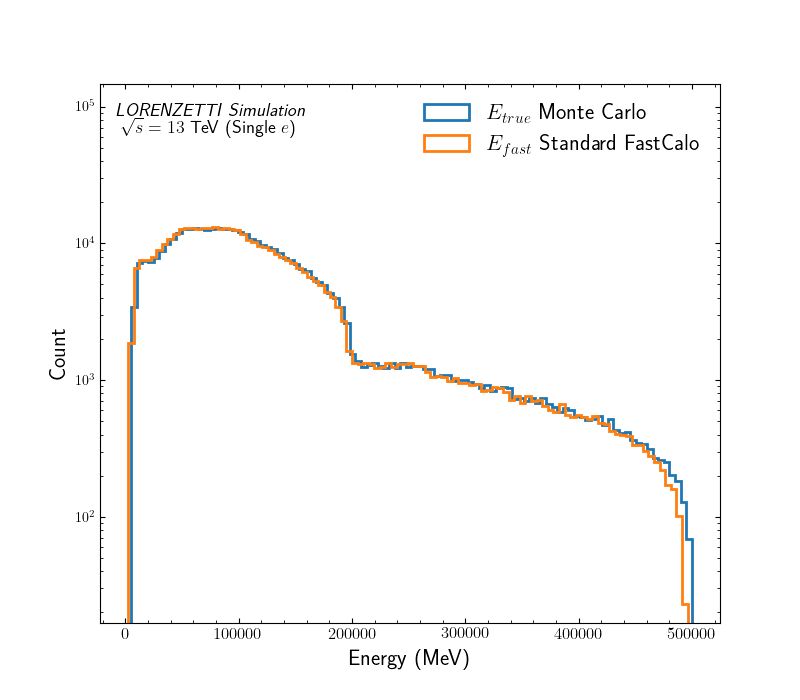

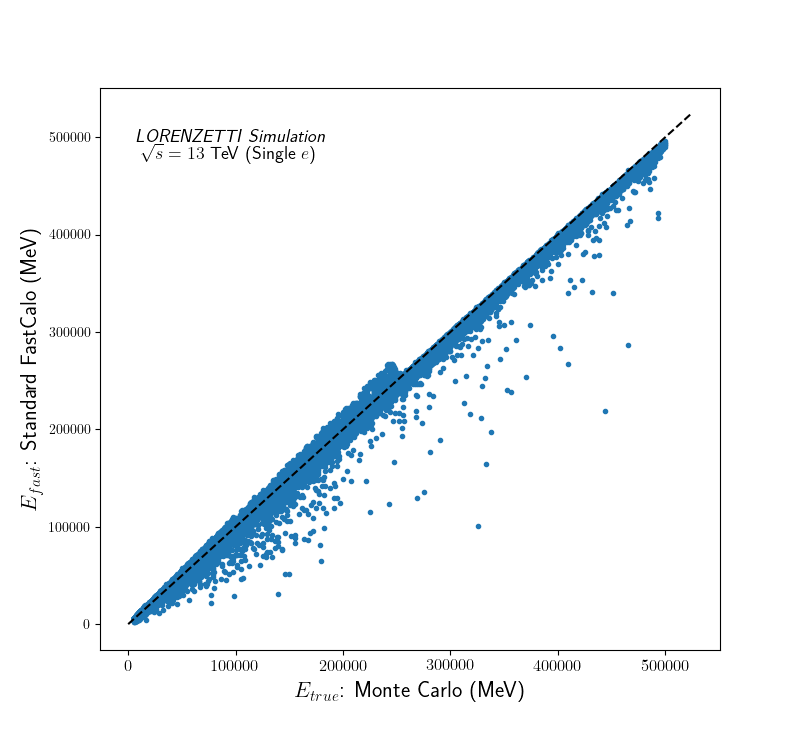

### Figure 5 — Standardized error and distribution goodness-of-fit

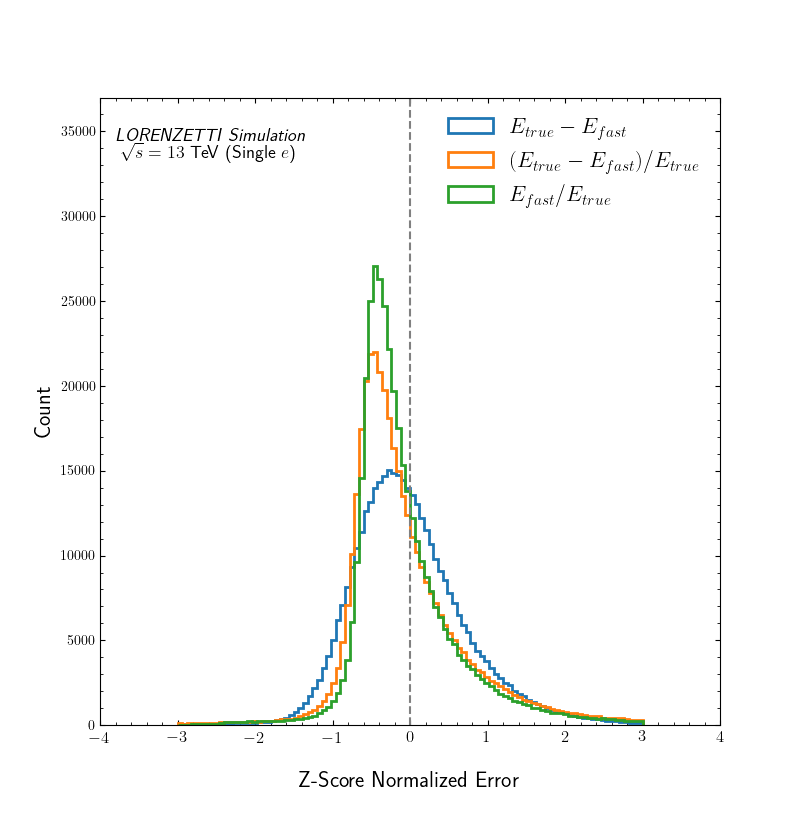

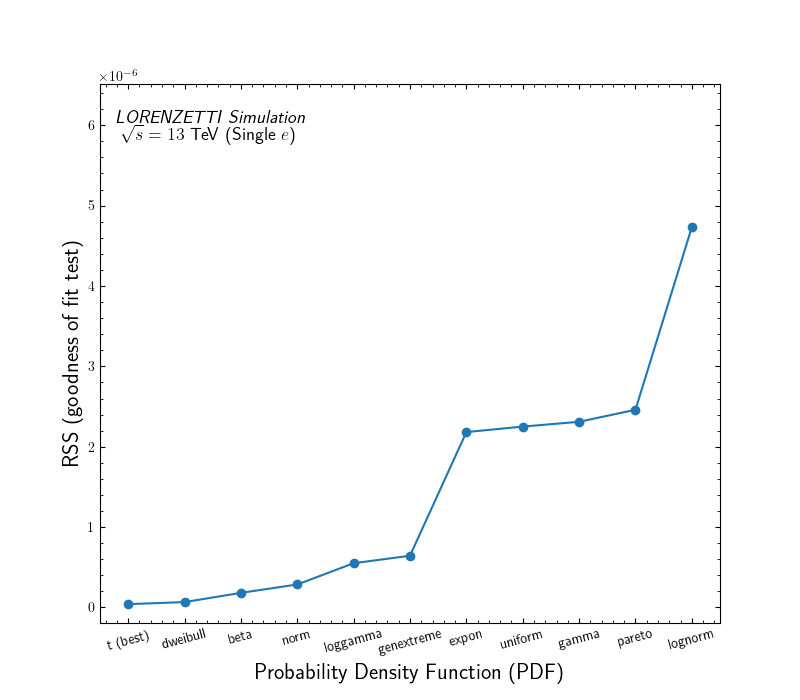

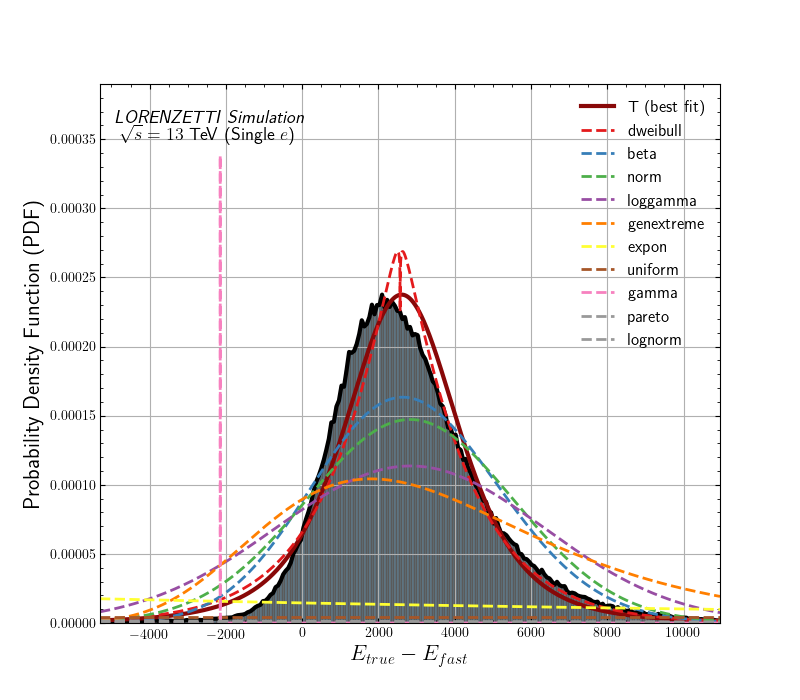

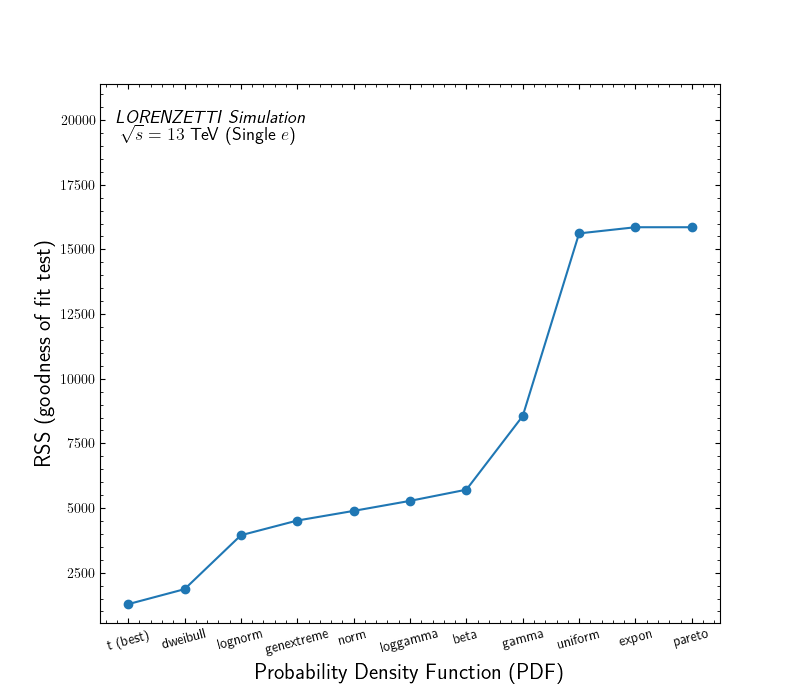

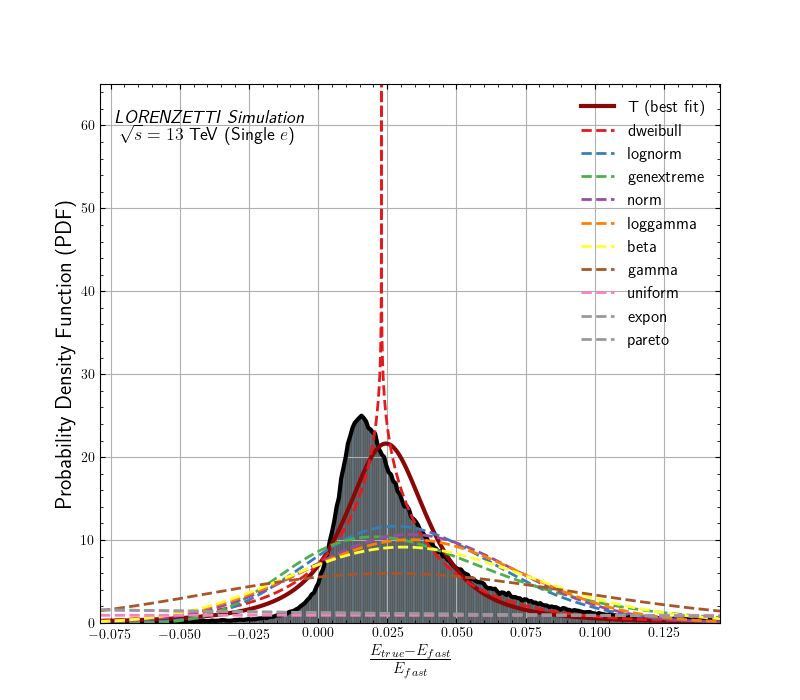

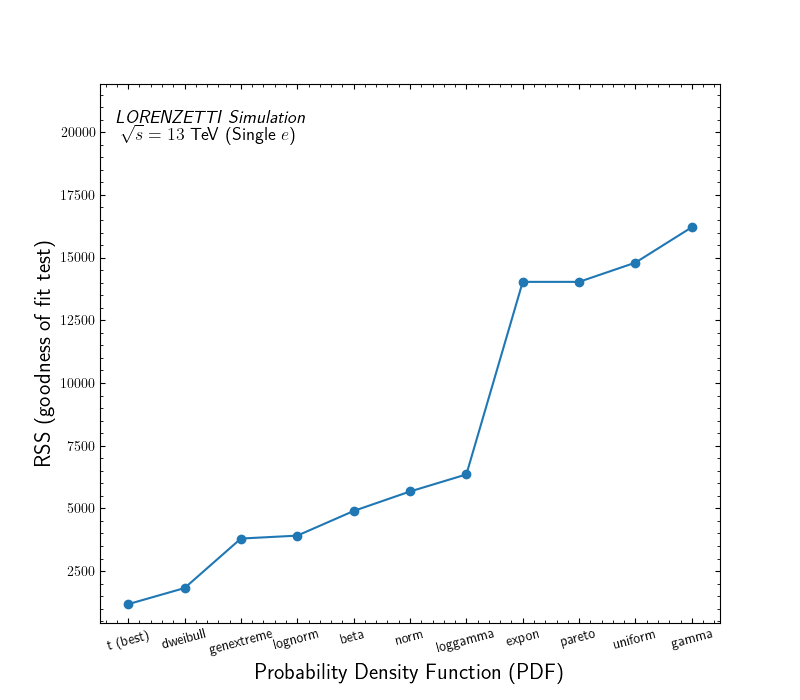

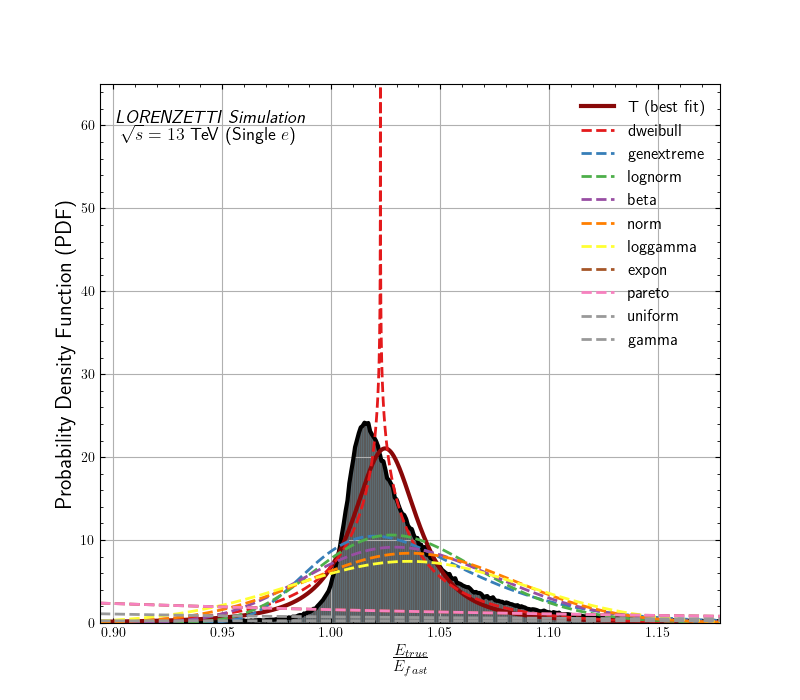

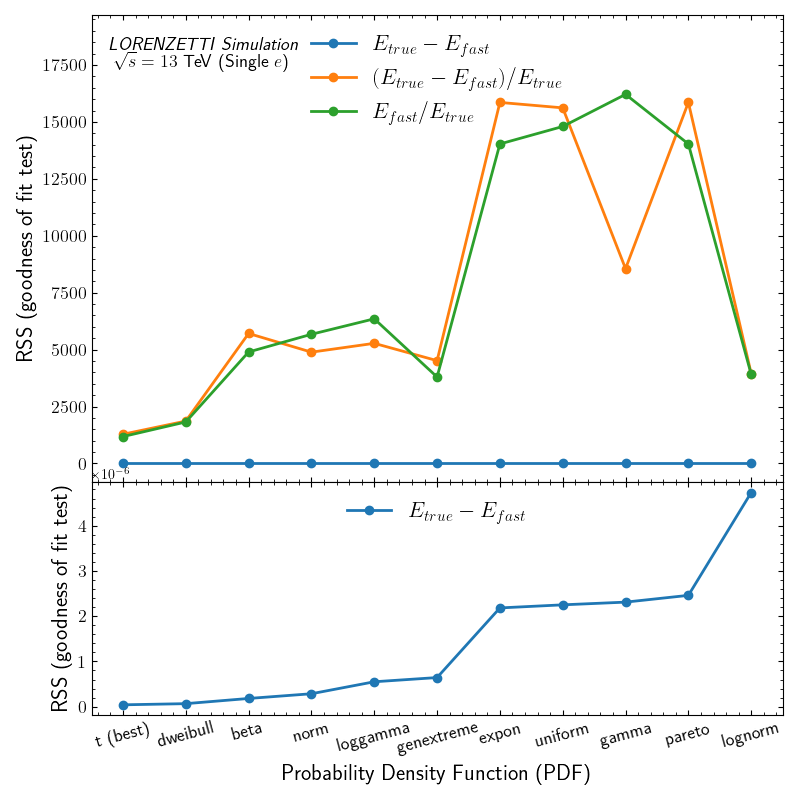

### Figure 6 — True calibration factor vs eta and ET

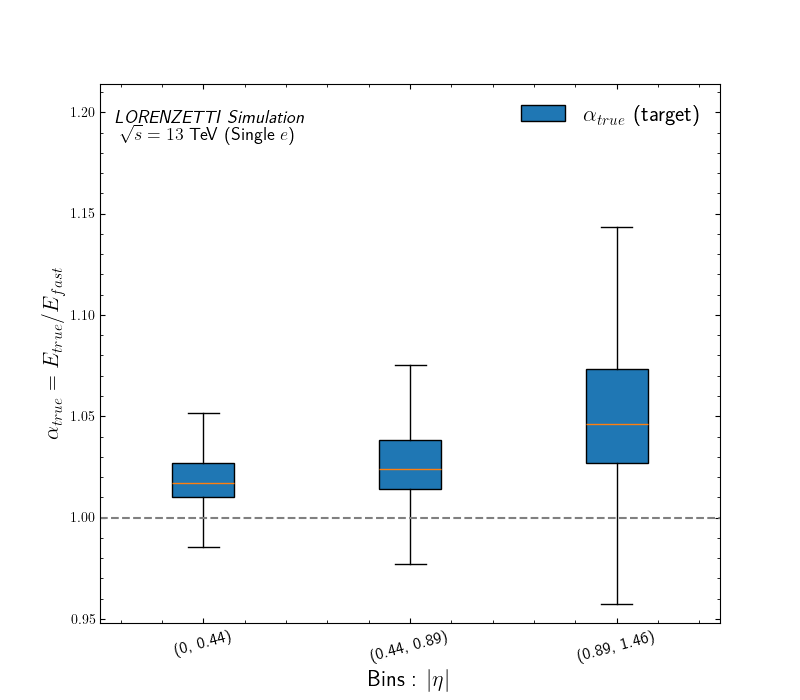

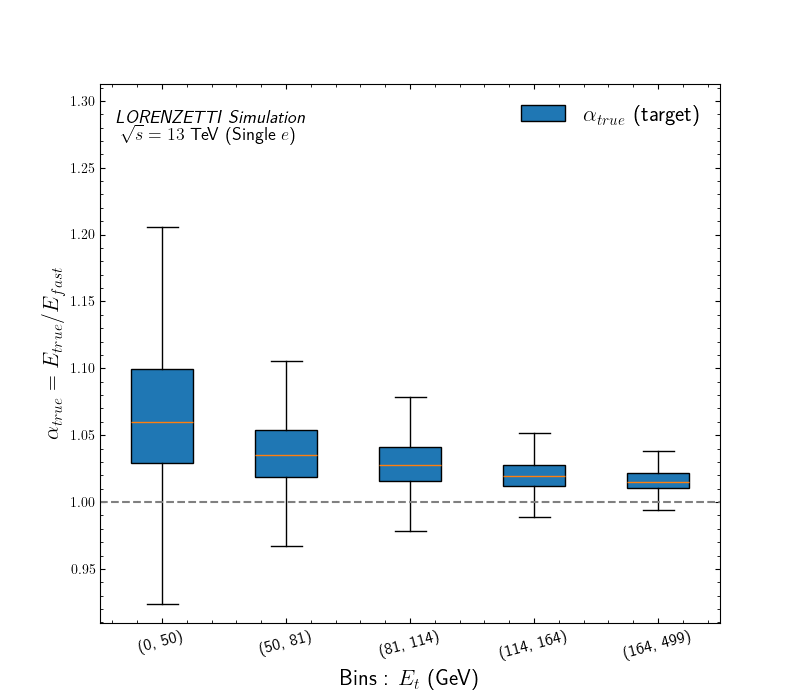

### Figure 7 — 100 ring distributions

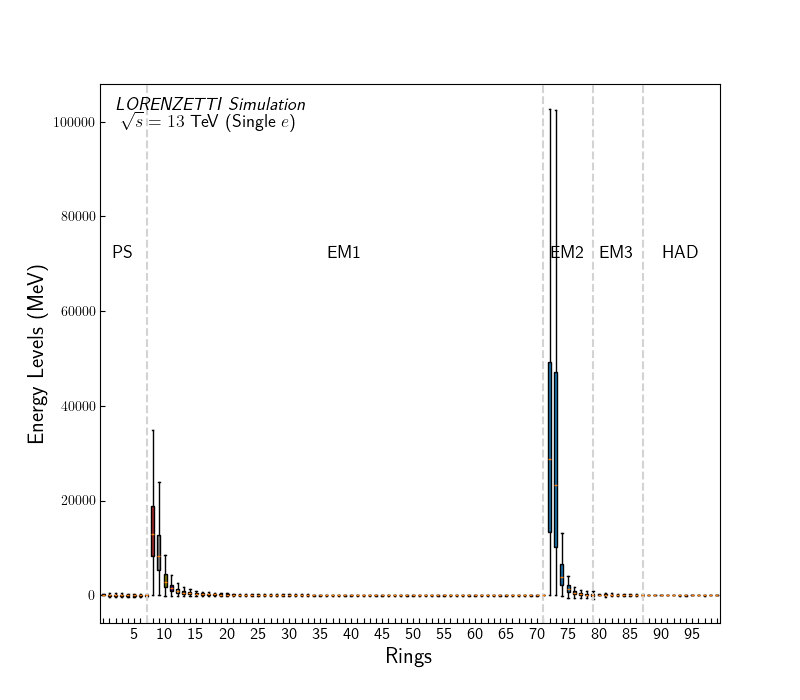

### Figure 8 — CORR, MI, PCA and ICA feature map

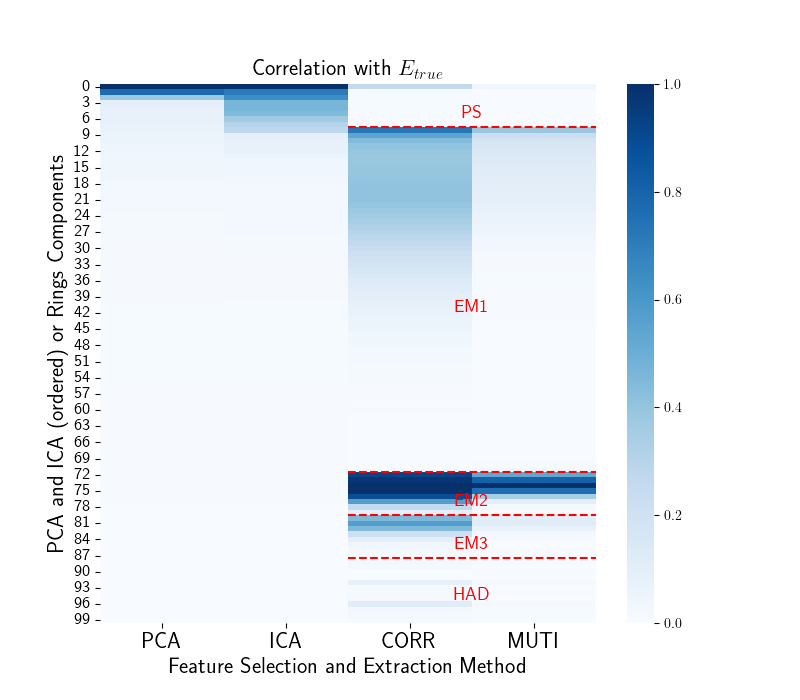

### Figure 9 — Calibrated energy residual distributions

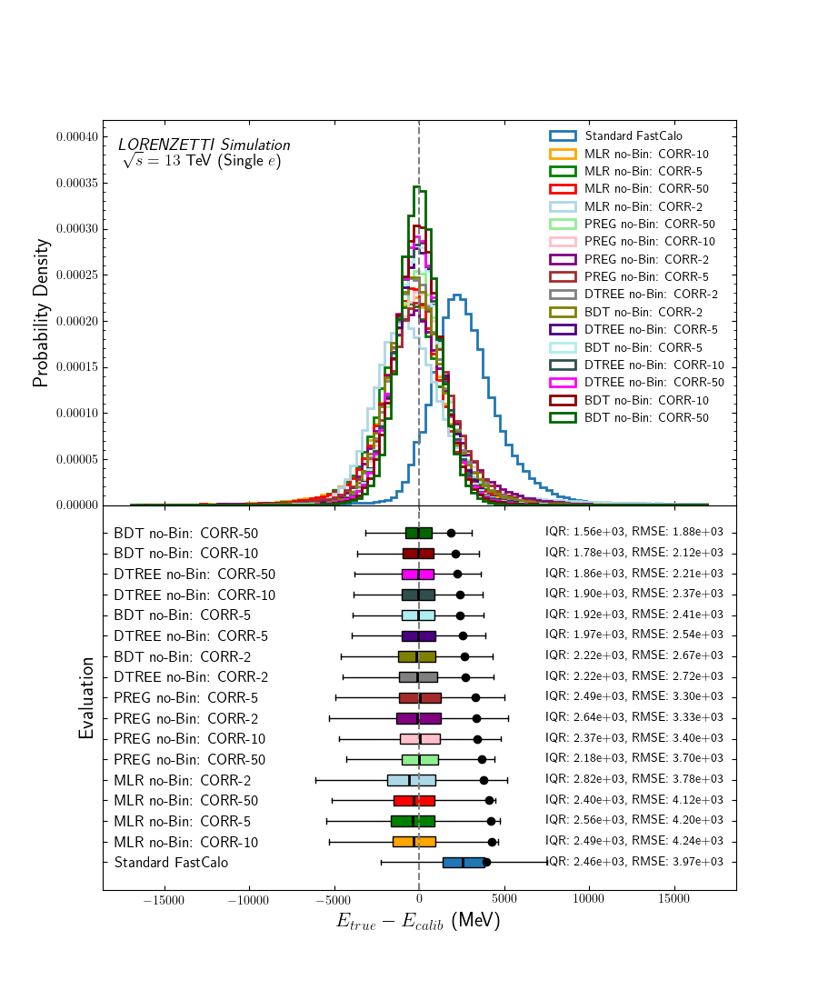

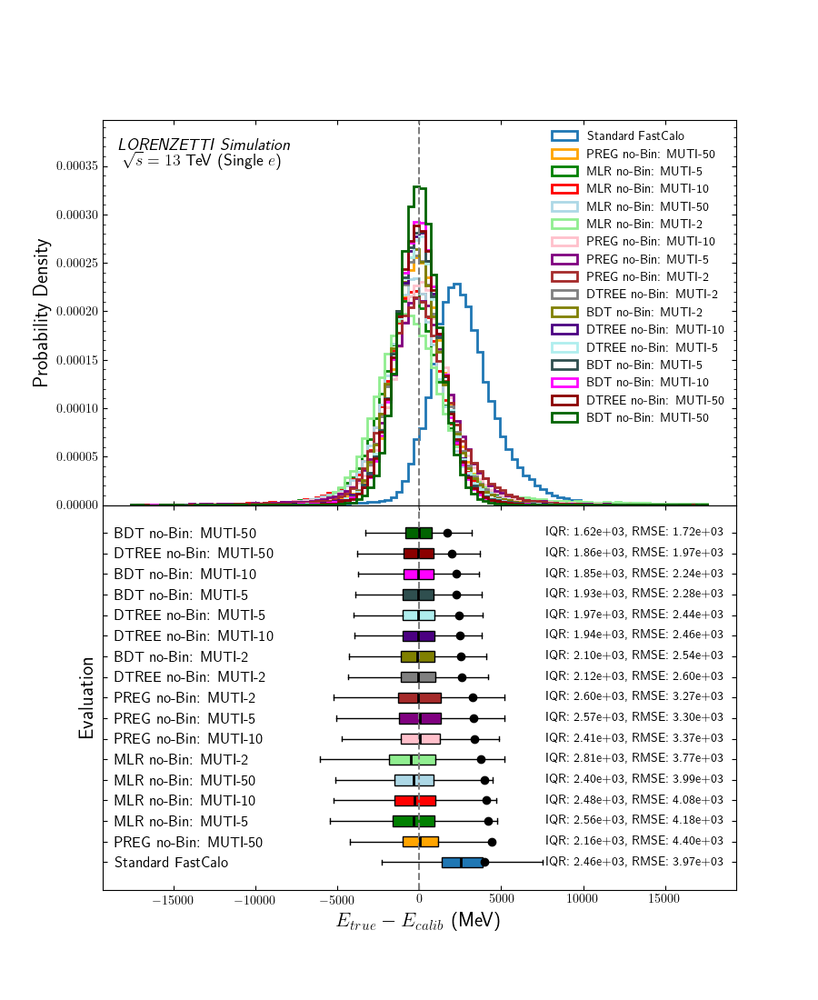

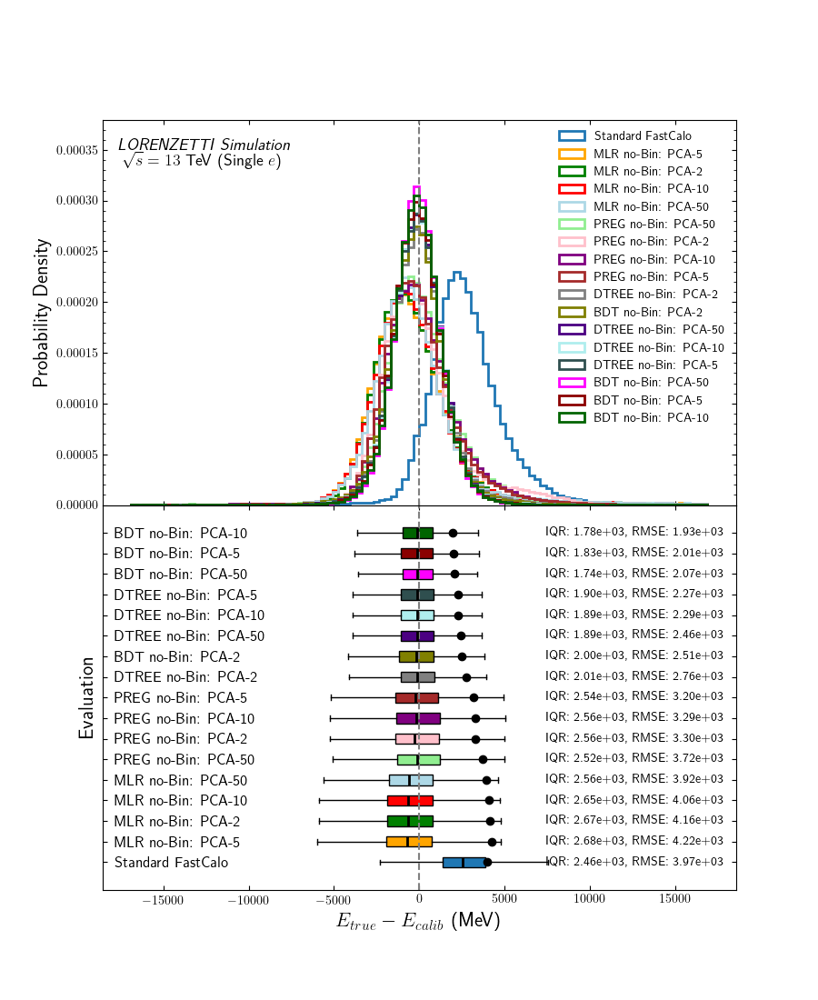

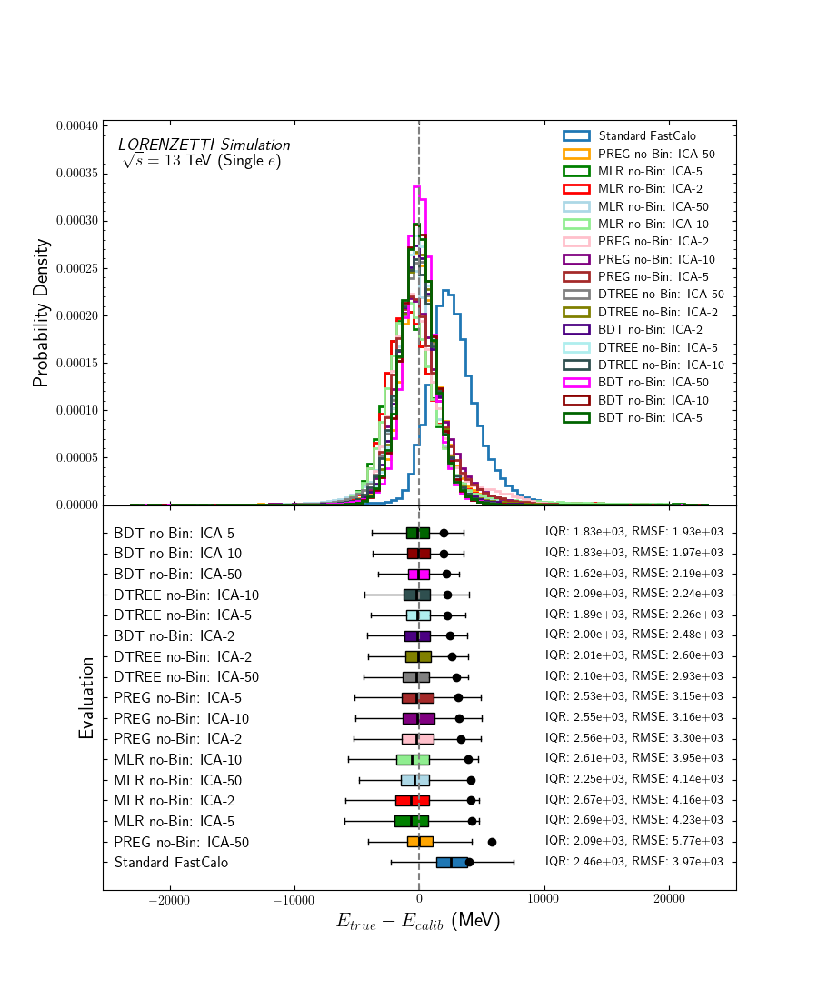

### Figure 10 — Top-ten accuracy/cost/complexity trade-off

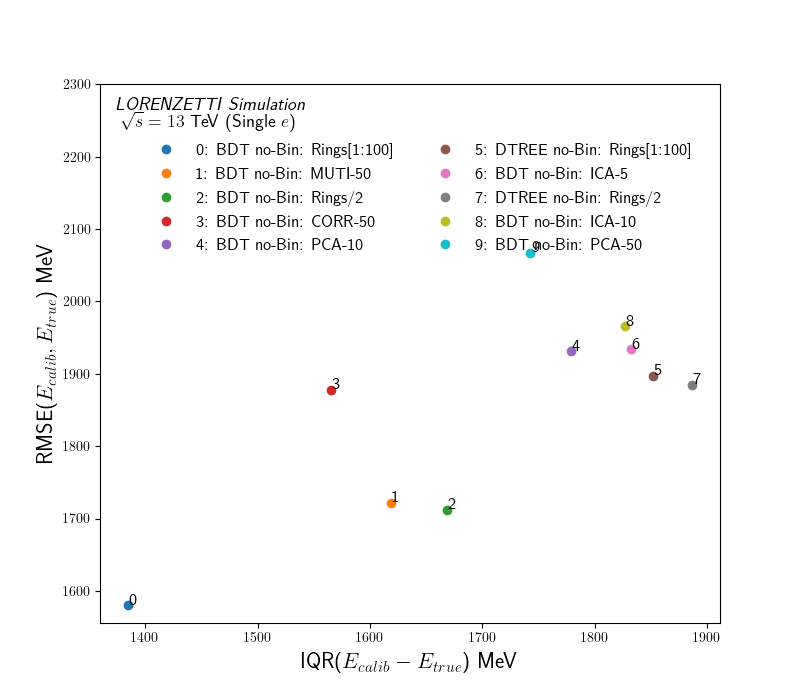

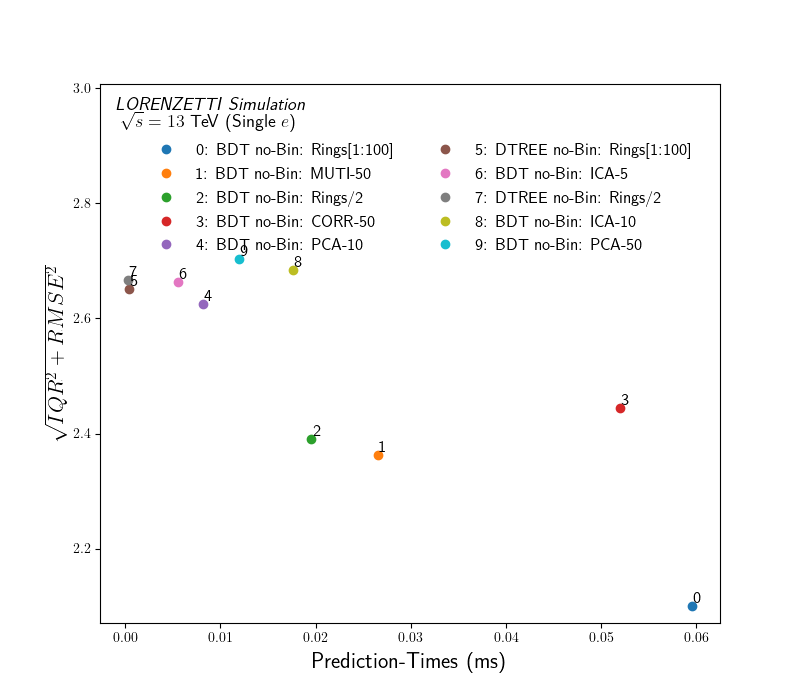

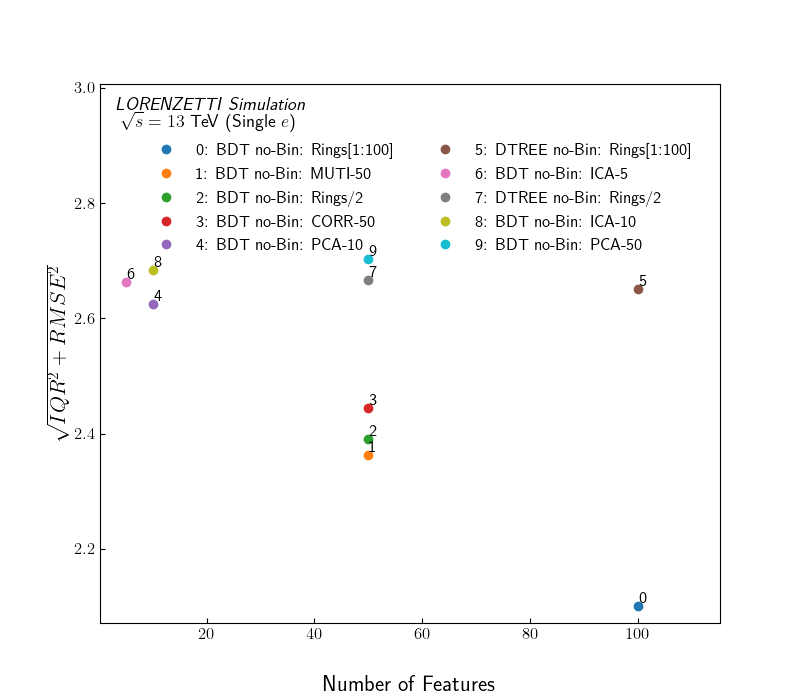

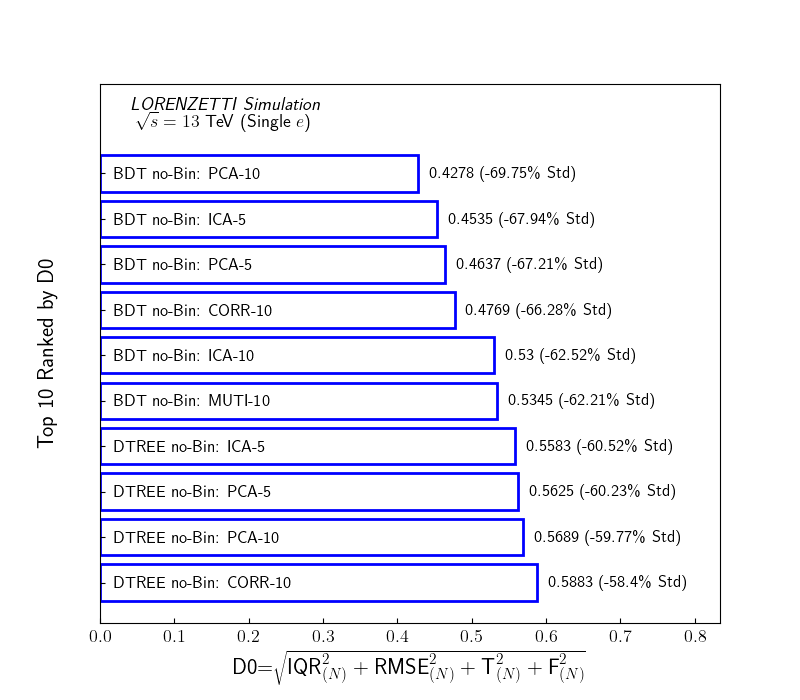

### Figure 11 — IQR of calibration factor in eta and ET

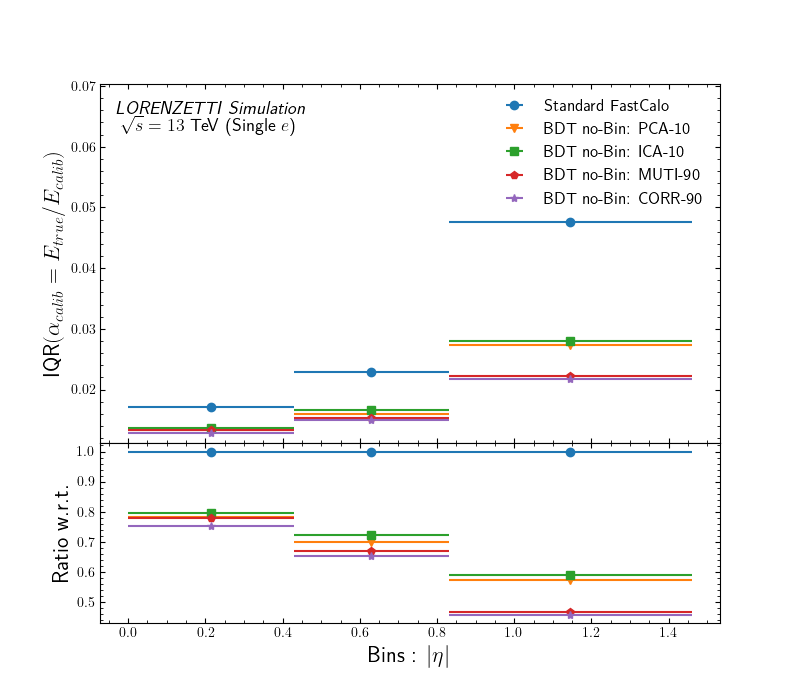

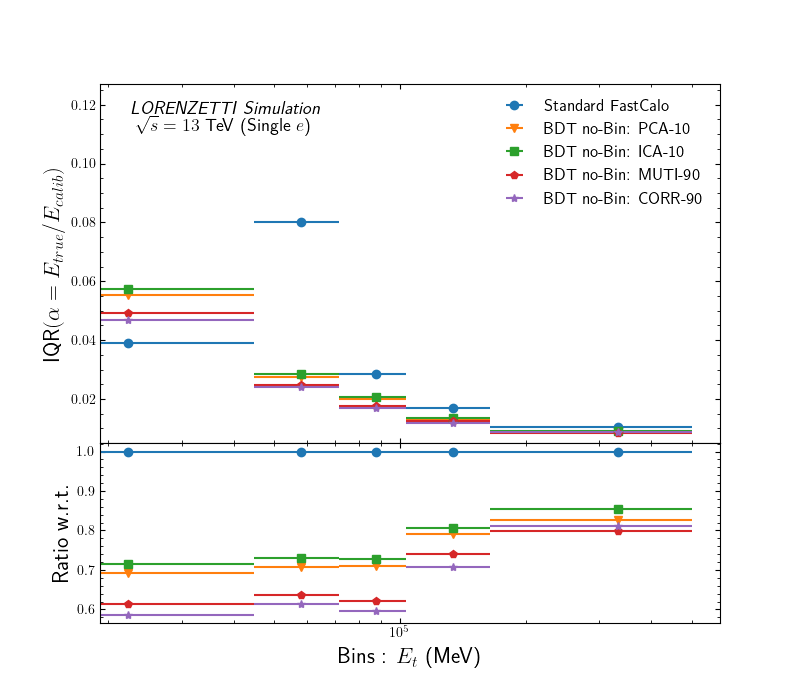

### Figure 12 — MAE and RMSE of calibration factor in eta and ET

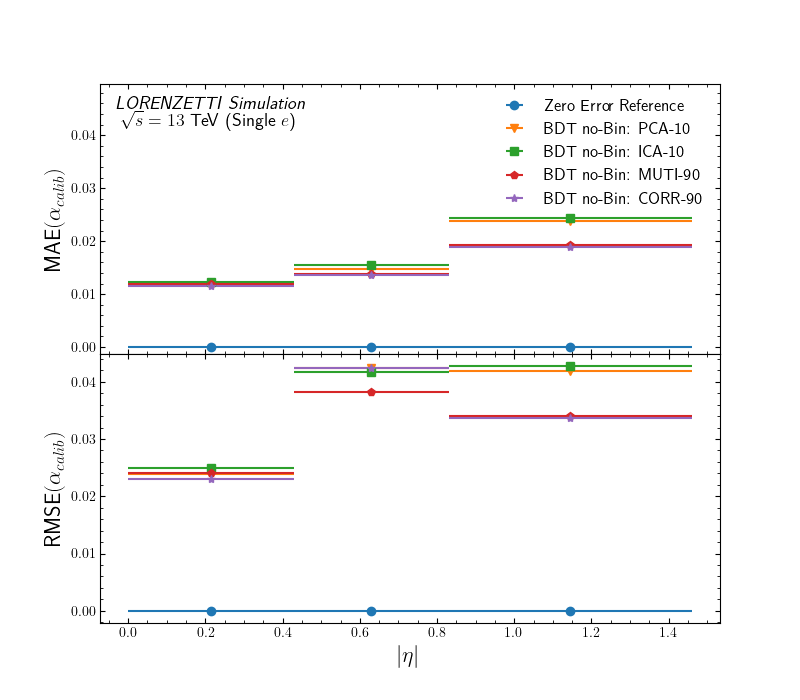

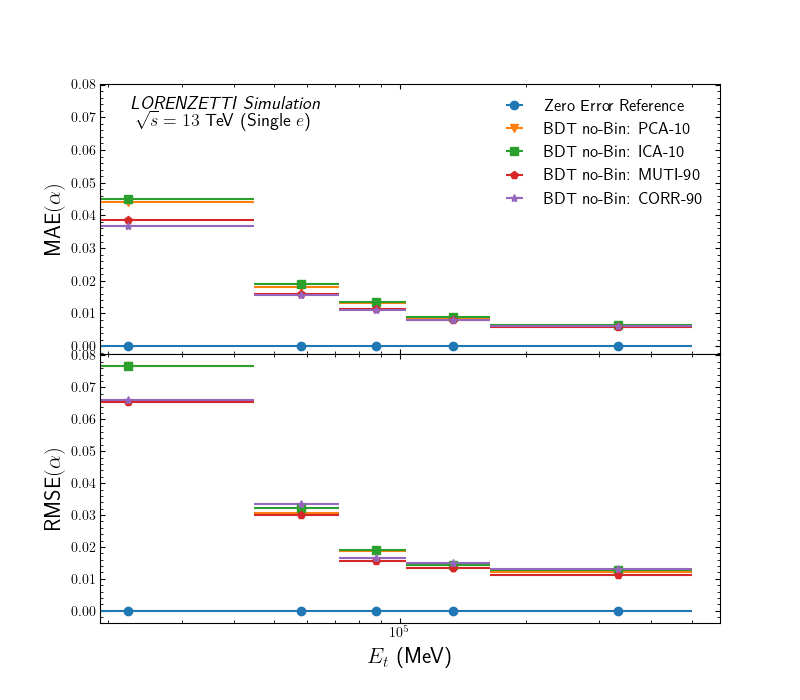

### Figure 13 — Calibration factor regional boxplots

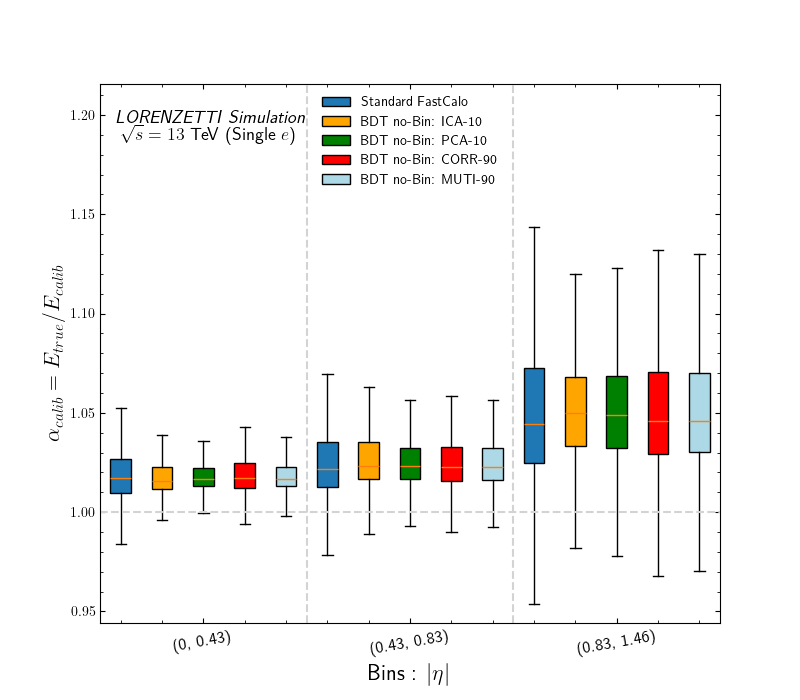

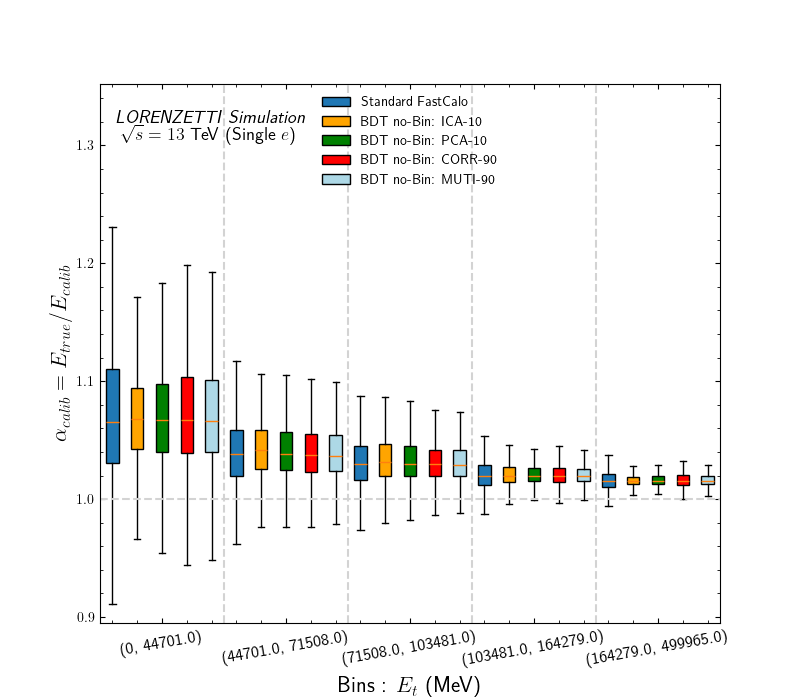

### Figure 14 — Threshold acceptance curve

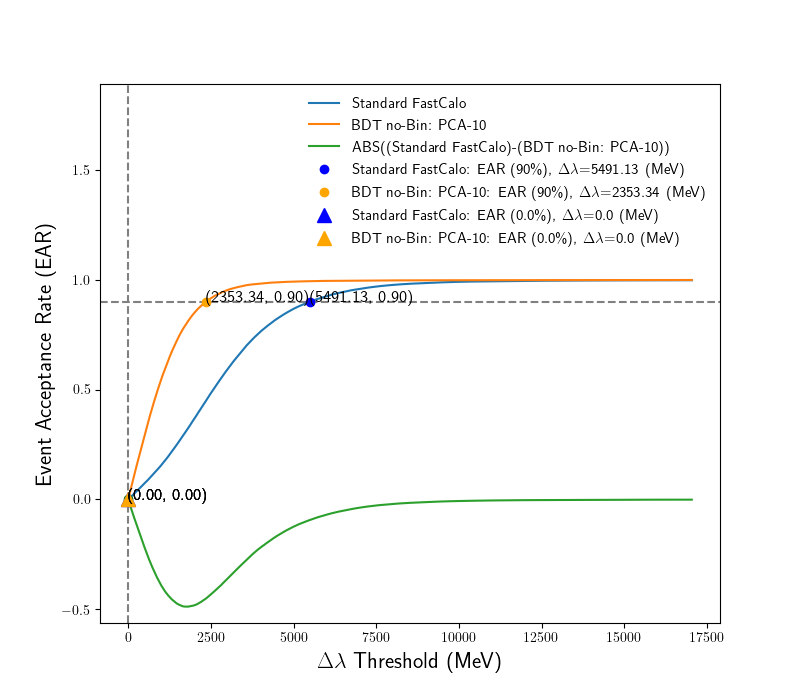

### Figure 15 — Error normal Q-Q comparison

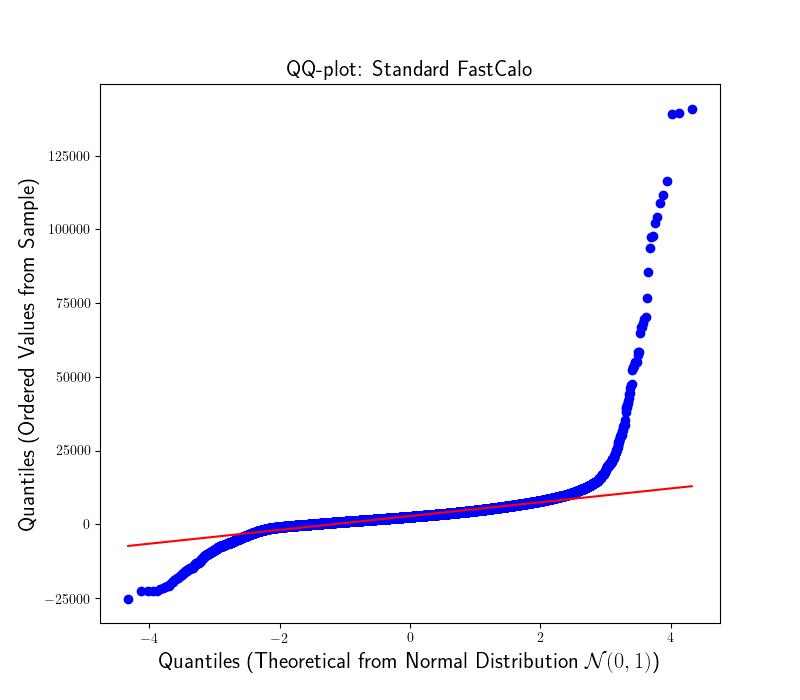

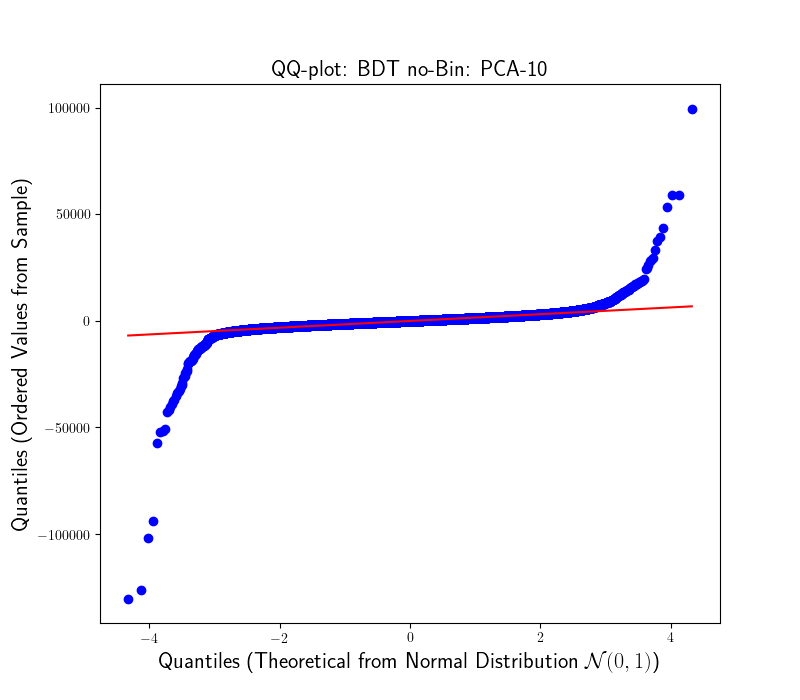

### Additional archived configurations

original_resolution_01.png


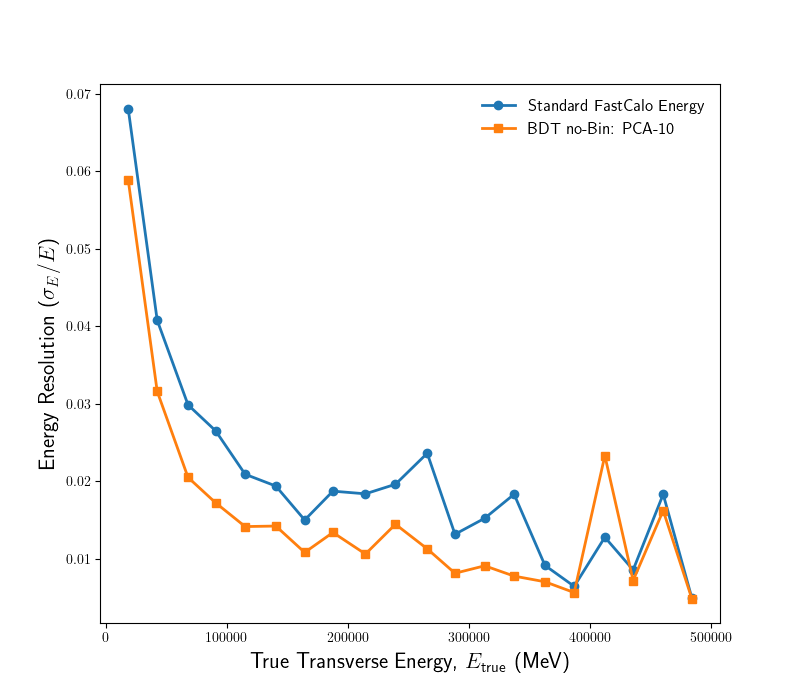

original_resolution_comparison_01_01.png


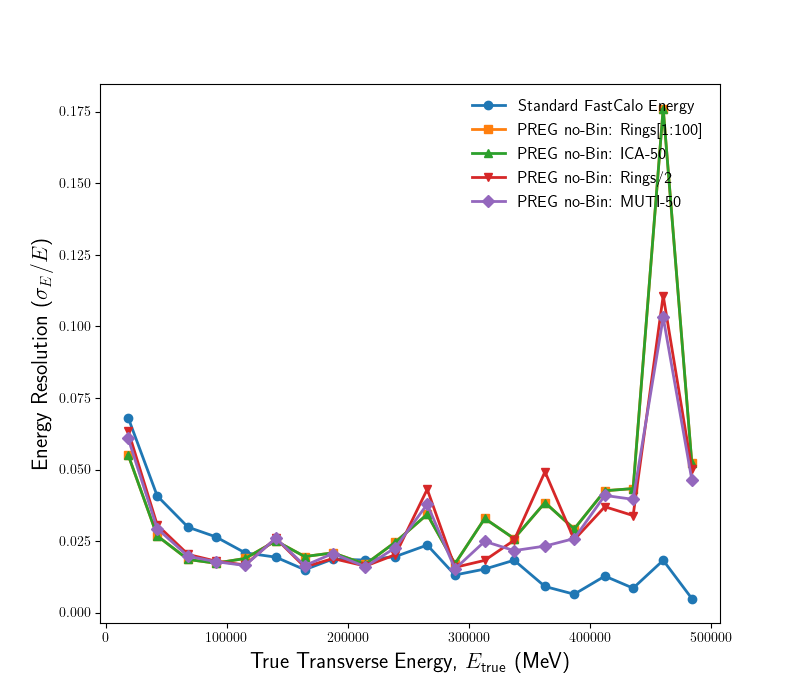

original_resolution_comparison_02_01.png


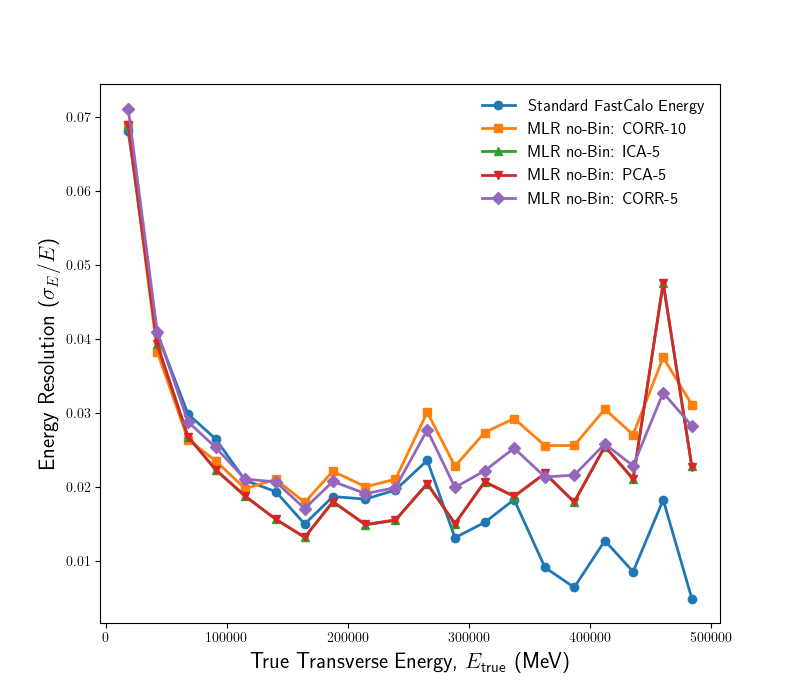

original_resolution_comparison_03_01.png


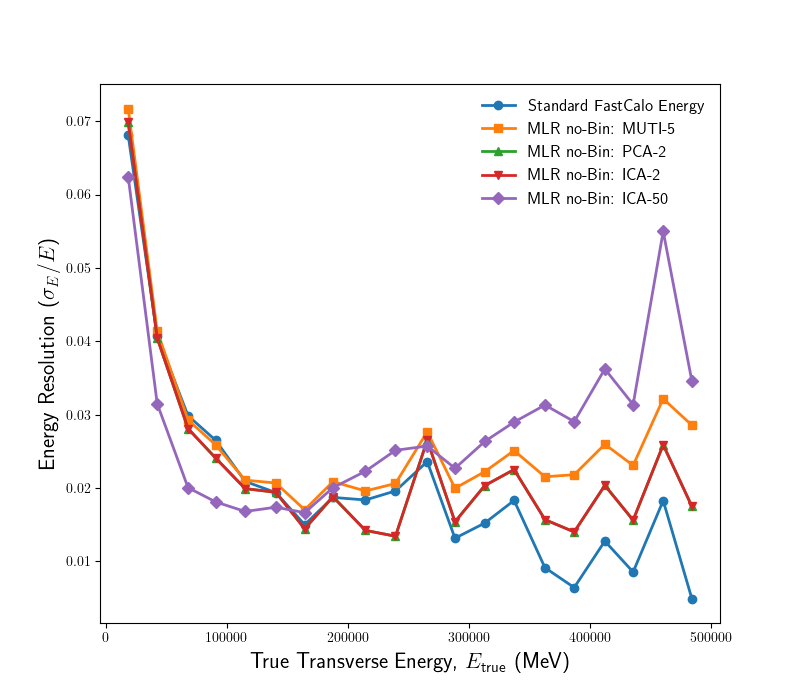

original_resolution_comparison_04_01.png


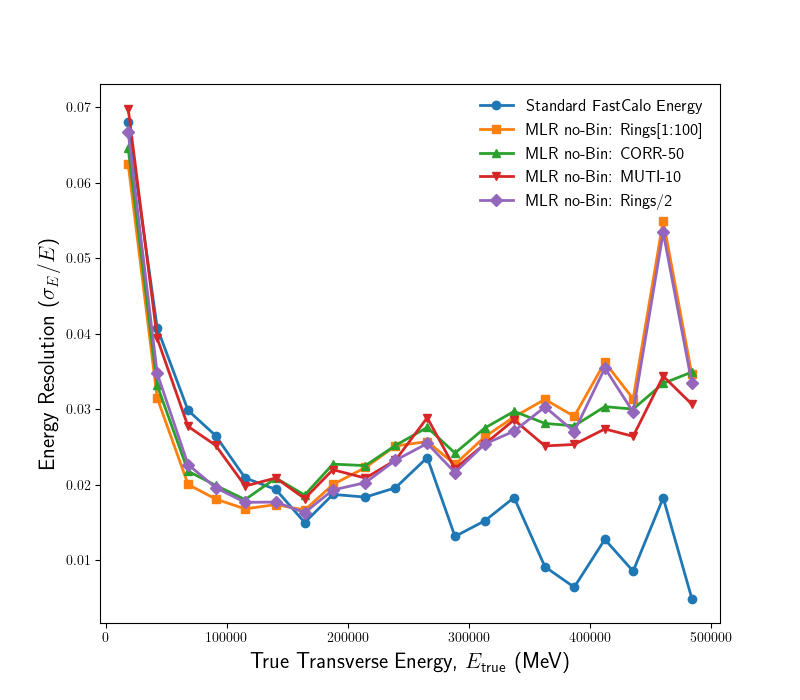

original_resolution_comparison_05_01.png


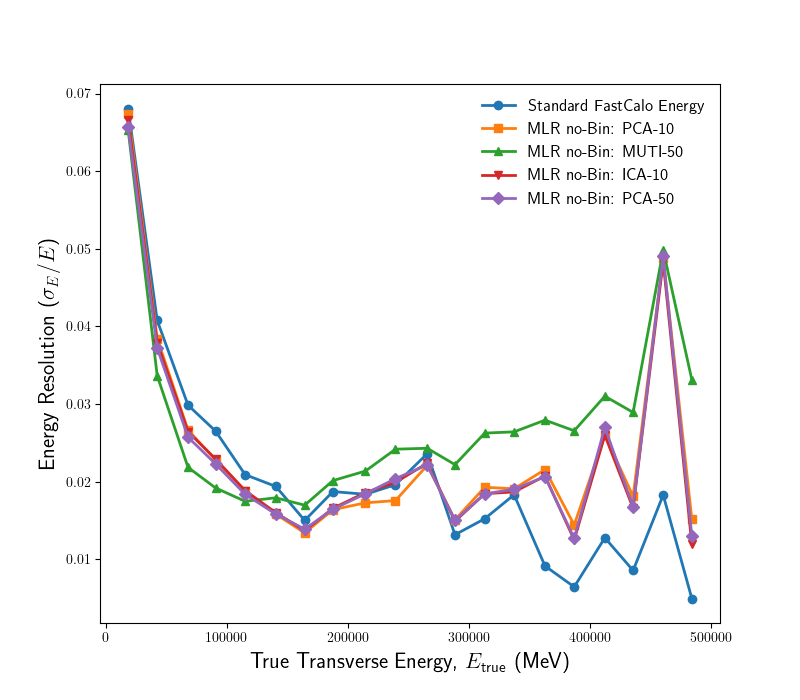

original_resolution_comparison_06_01.png


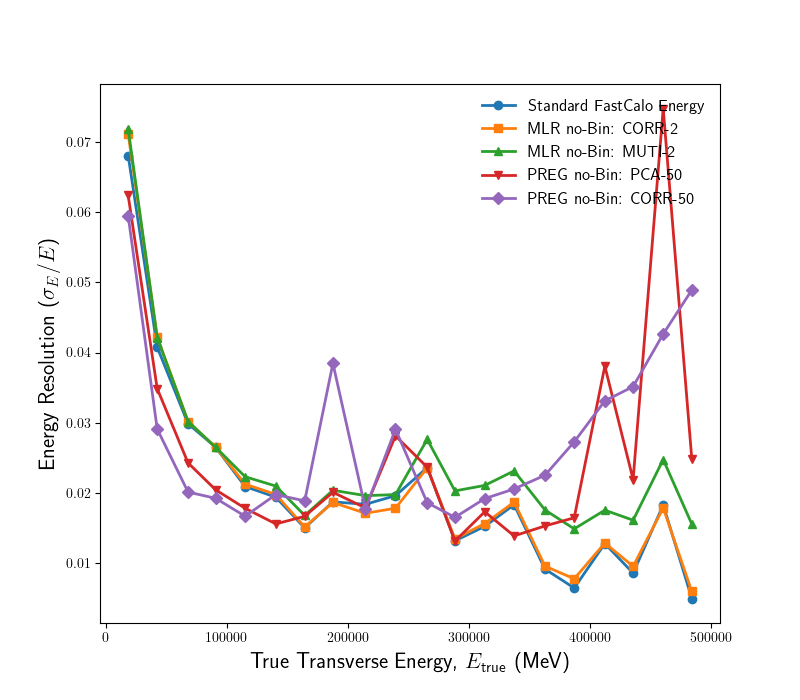

original_resolution_comparison_07_01.png


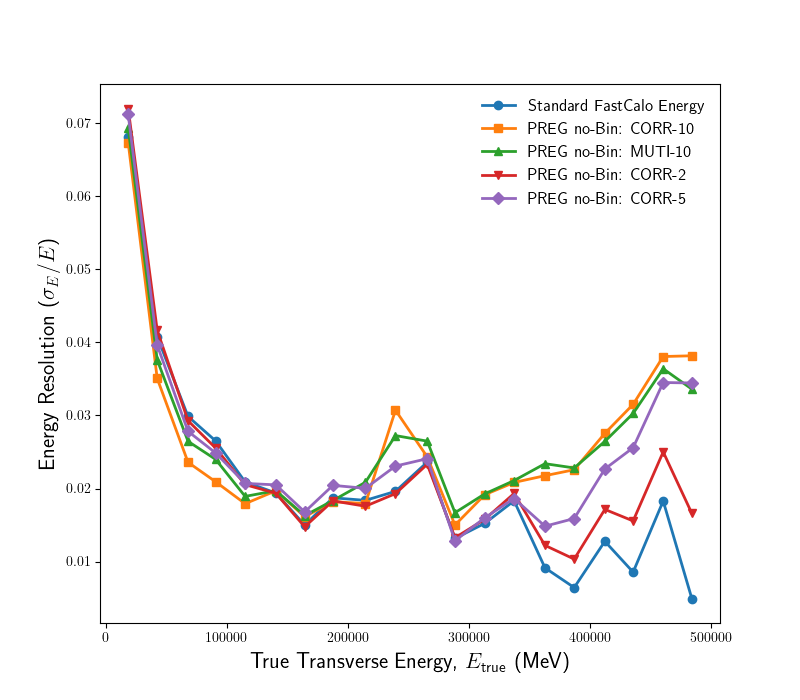

original_resolution_comparison_08_01.png


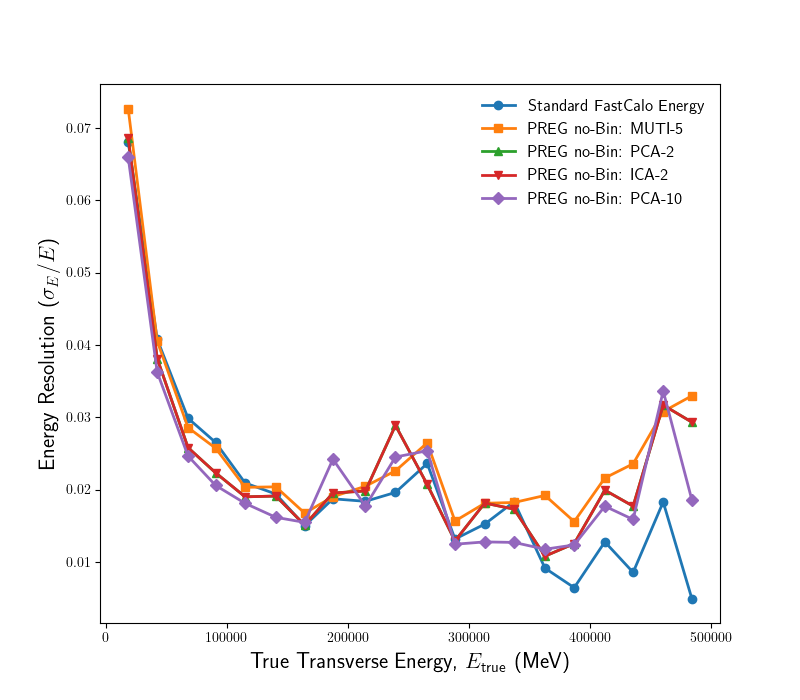

original_resolution_comparison_09_01.png


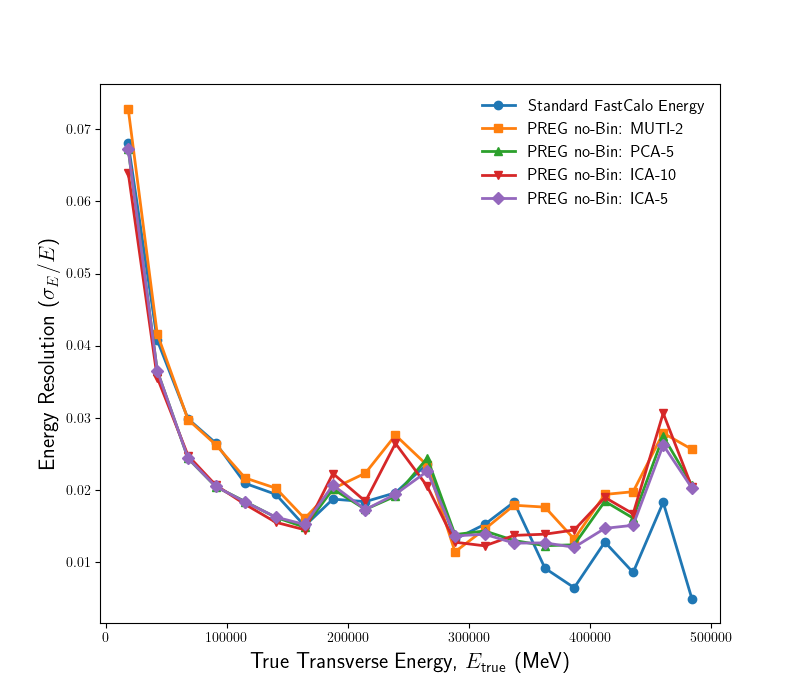

original_resolution_comparison_10_01.png


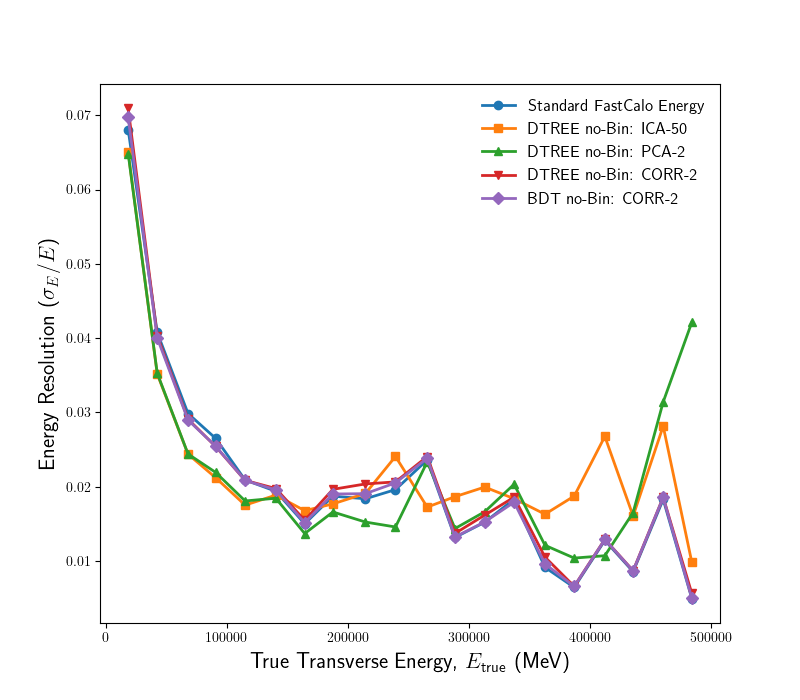

original_resolution_comparison_11_01.png


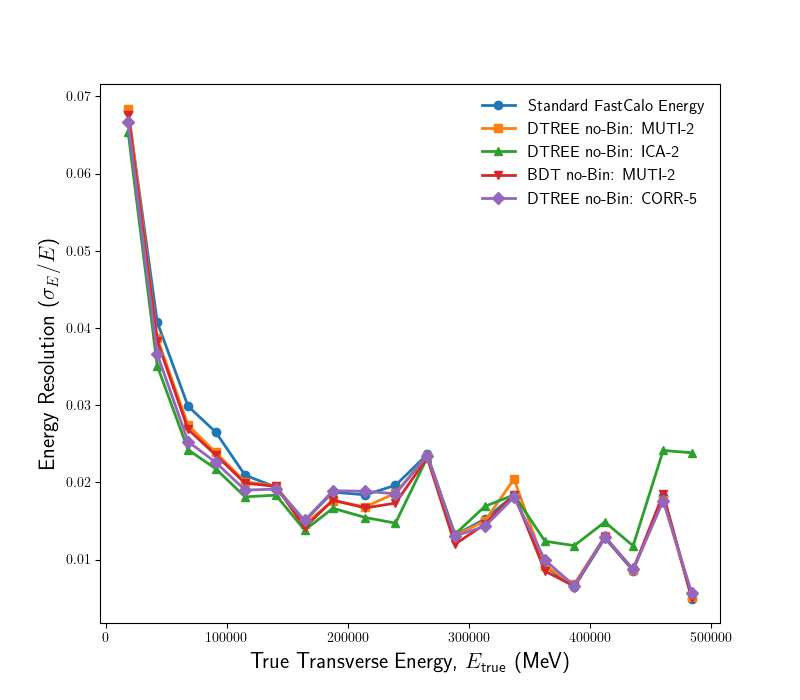

original_resolution_comparison_12_01.png


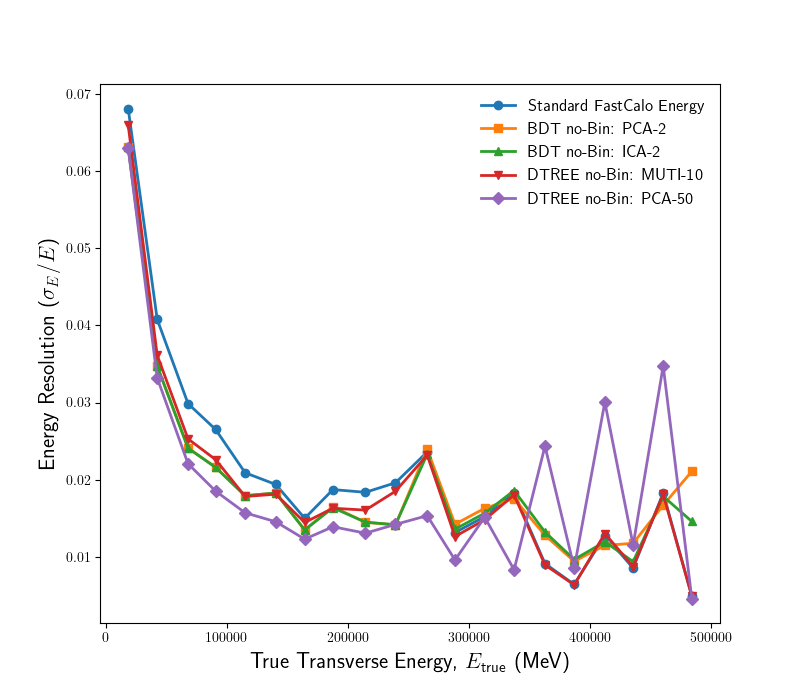

original_resolution_comparison_13_01.png


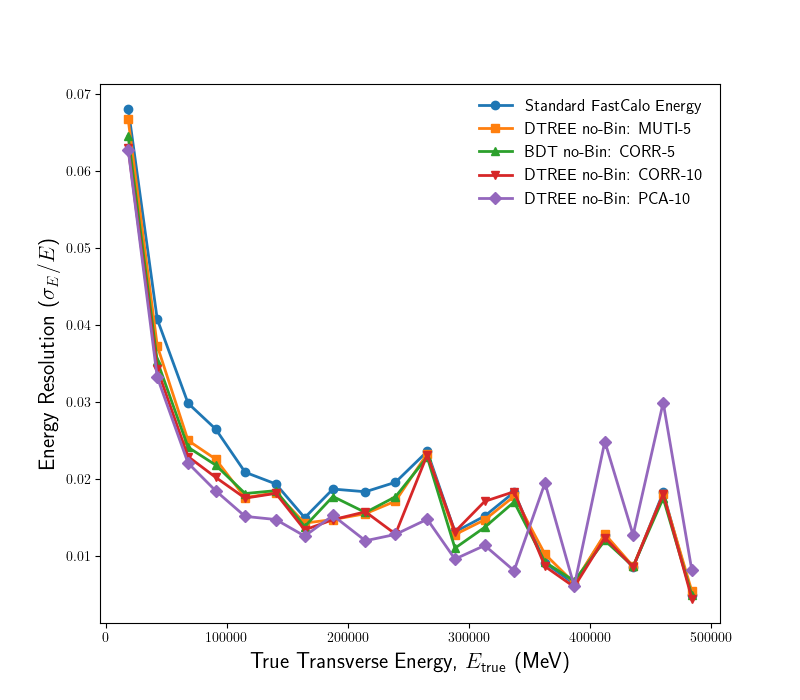

original_resolution_comparison_14_01.png


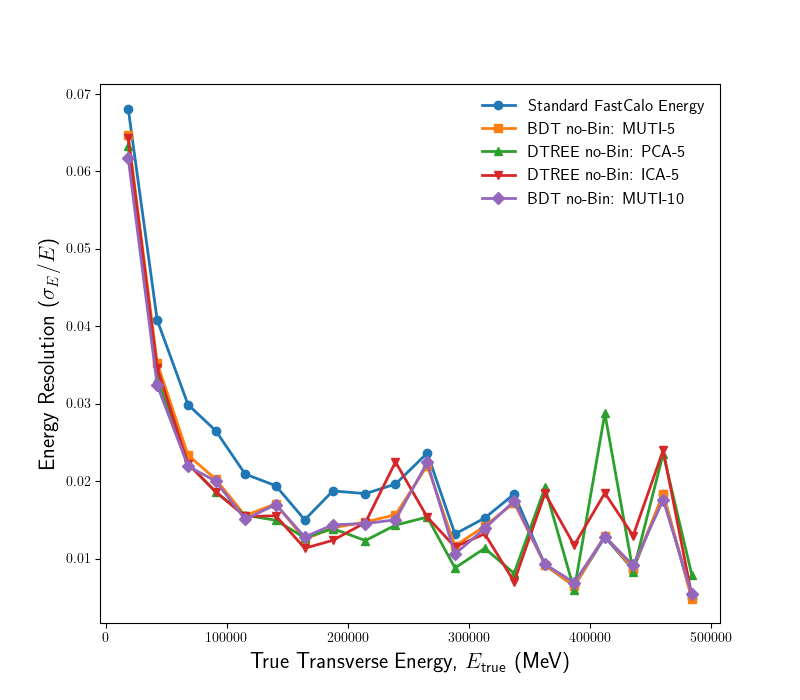

original_resolution_comparison_15_01.png


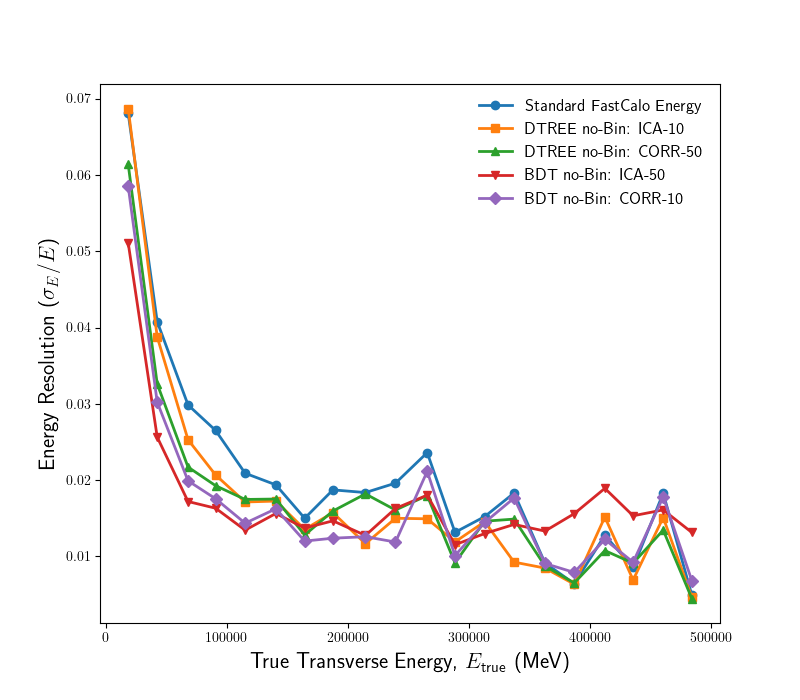

original_resolution_comparison_16_01.png


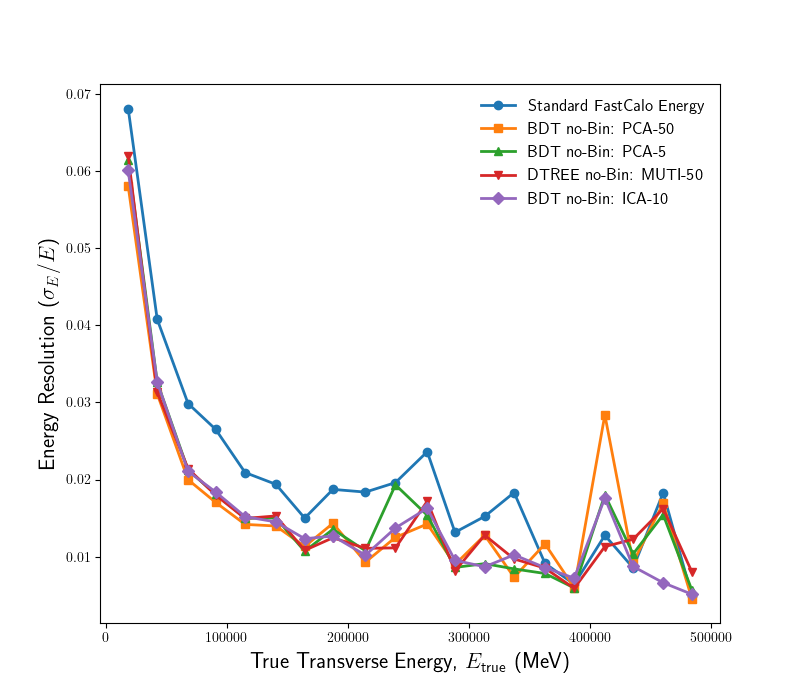

original_resolution_comparison_17_01.png


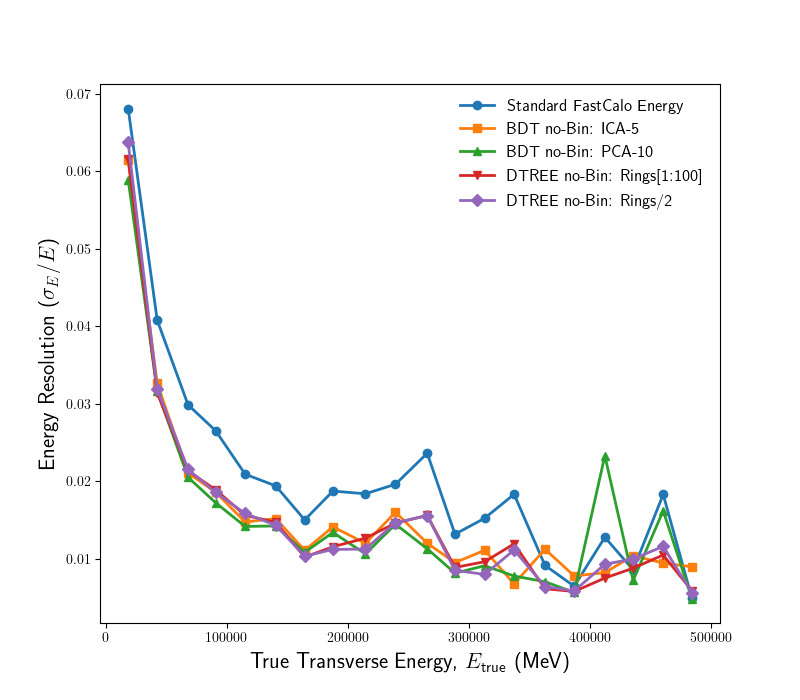

original_resolution_comparison_18_01.png


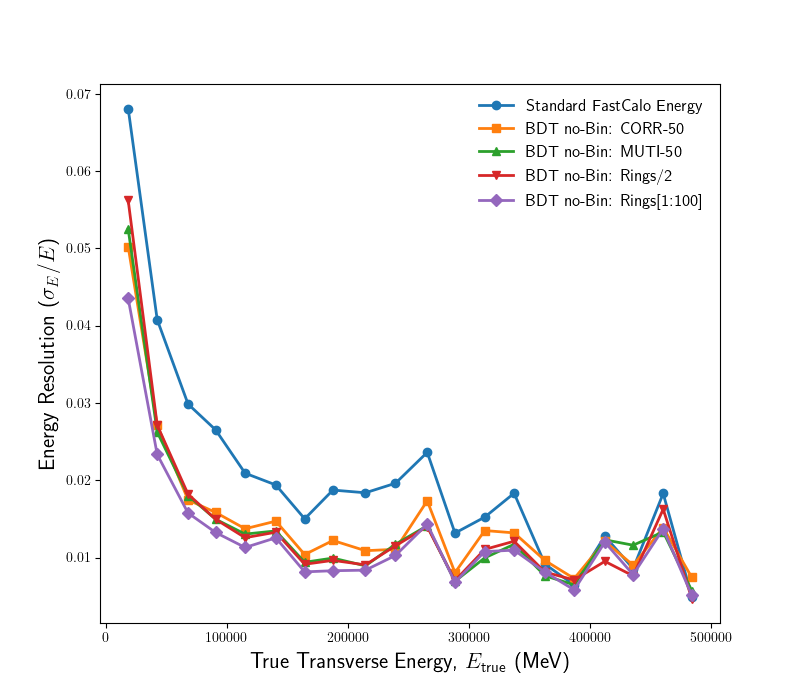

original_scatter_01.png


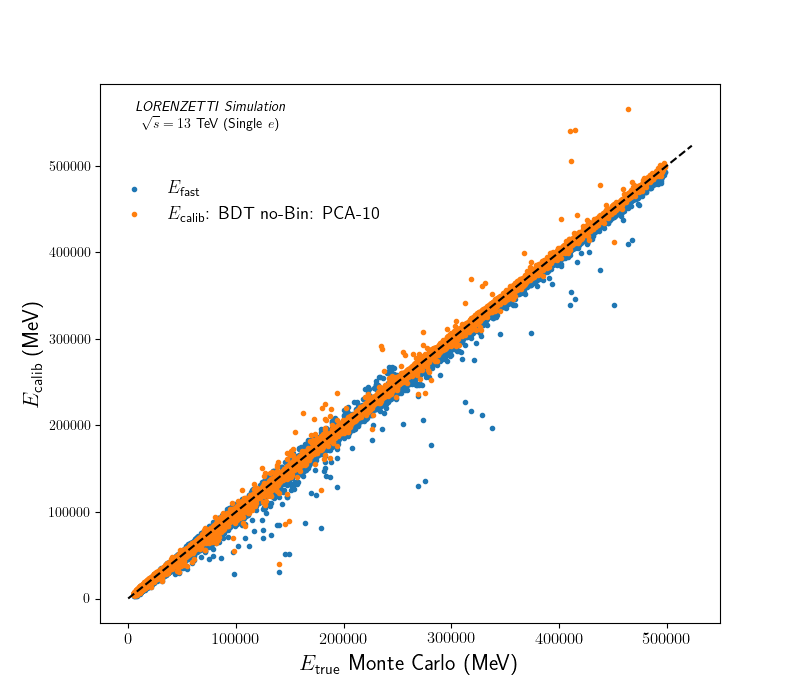

original_scatter_02.png


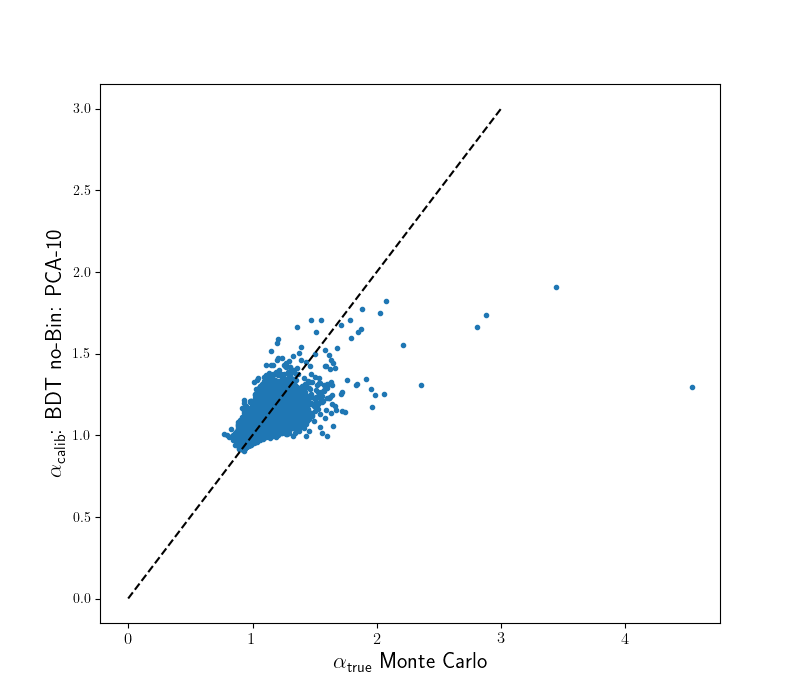

original_scatter_03.png


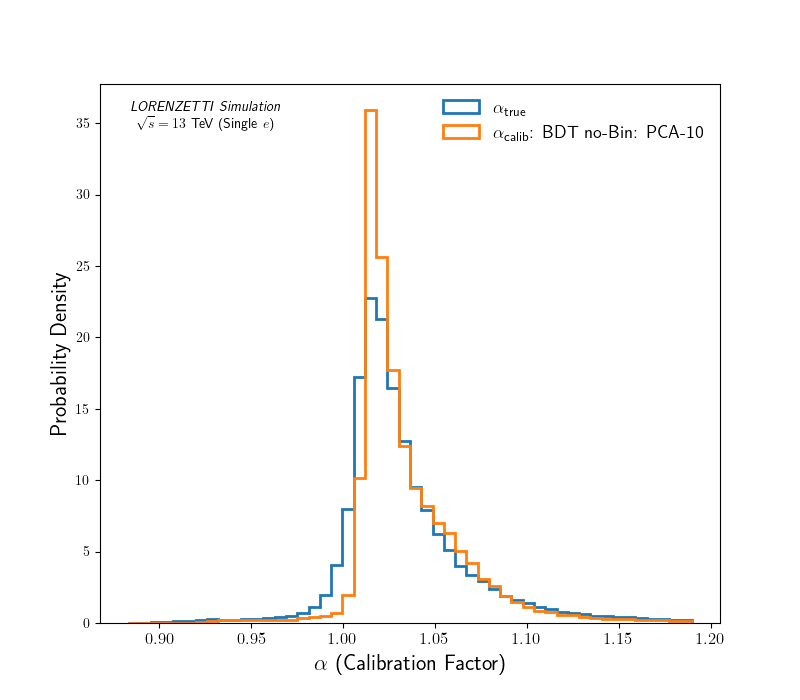

original_scatter_04.png


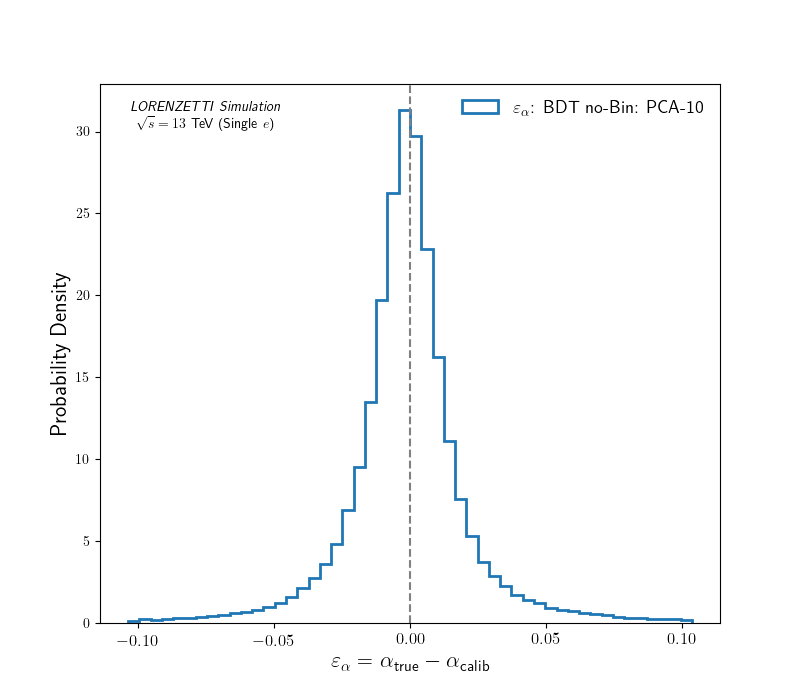

original_scatter_05.png


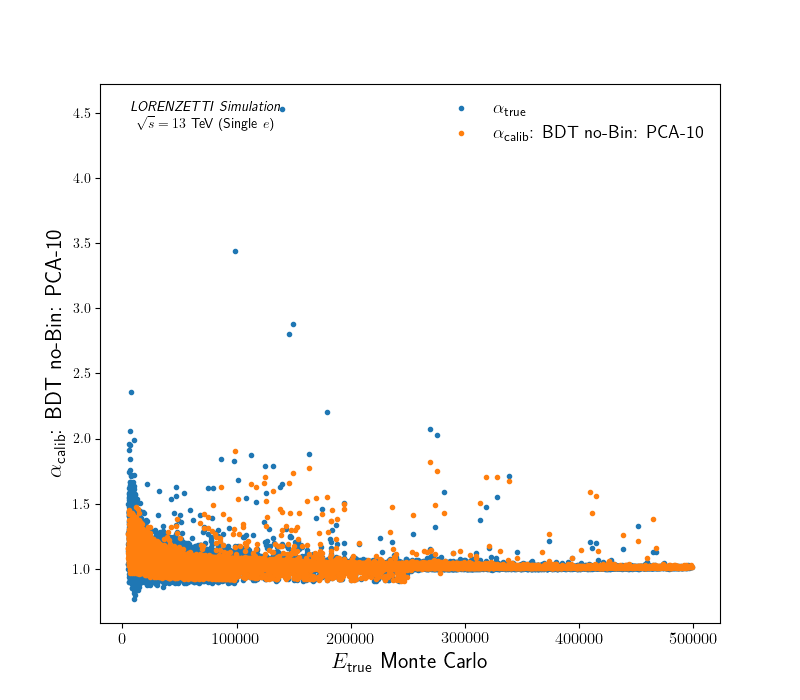

original_segmented_02.png


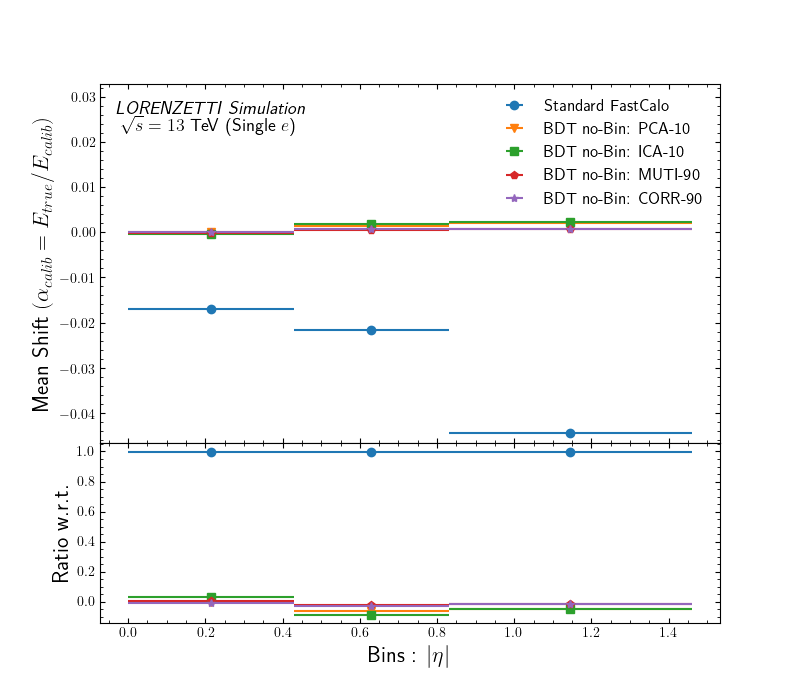

original_segmented_04.png


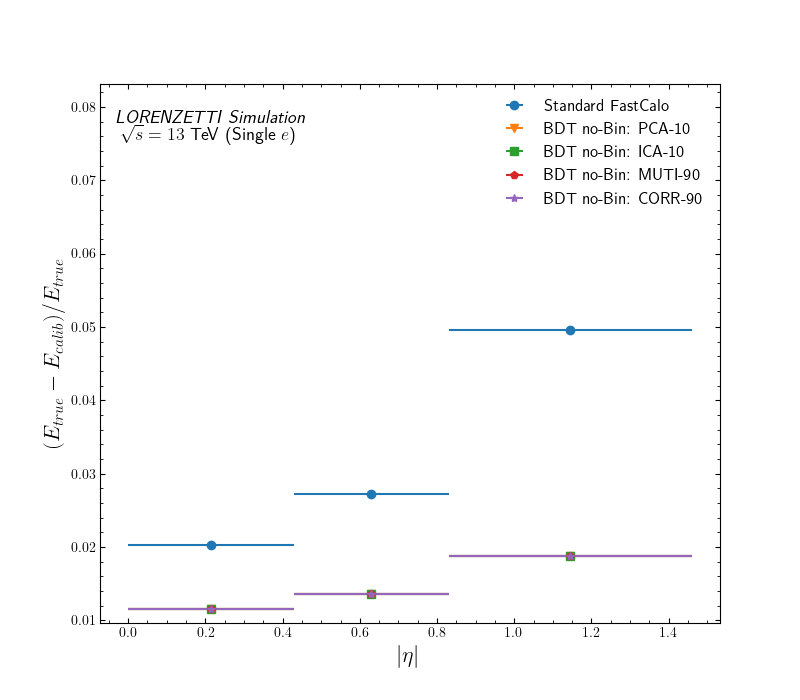

original_segmented_05.png


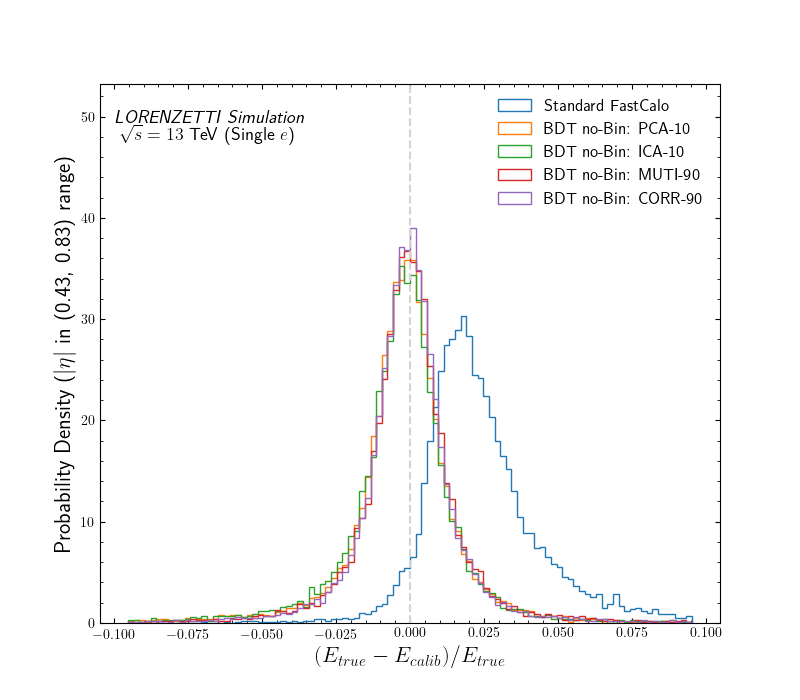

original_segmented_06.png


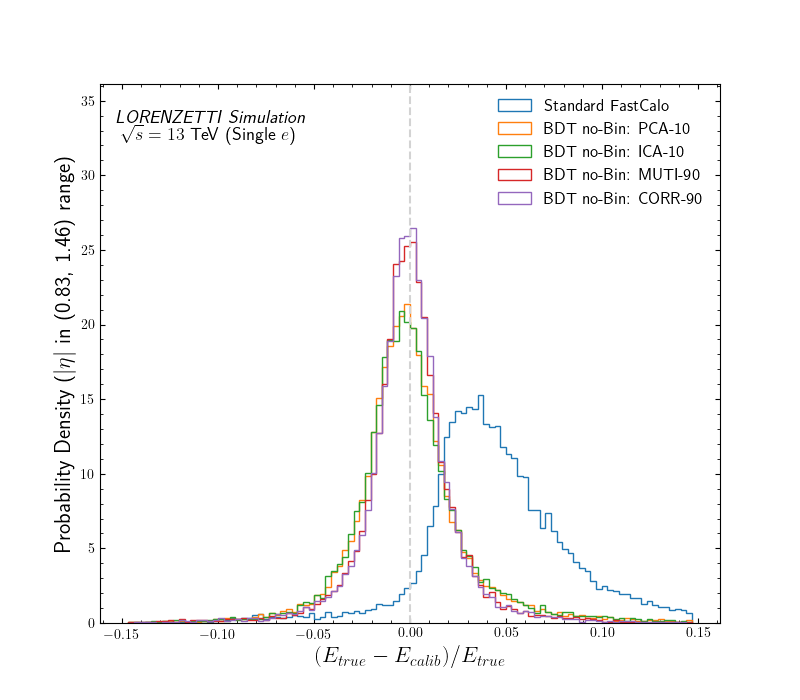

original_segmented_07.png


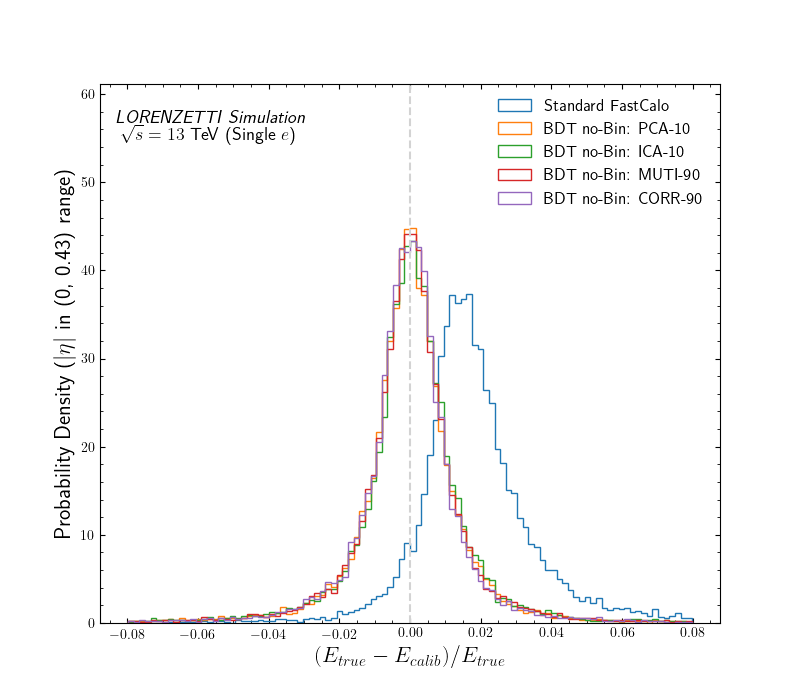

original_segmented_09.png


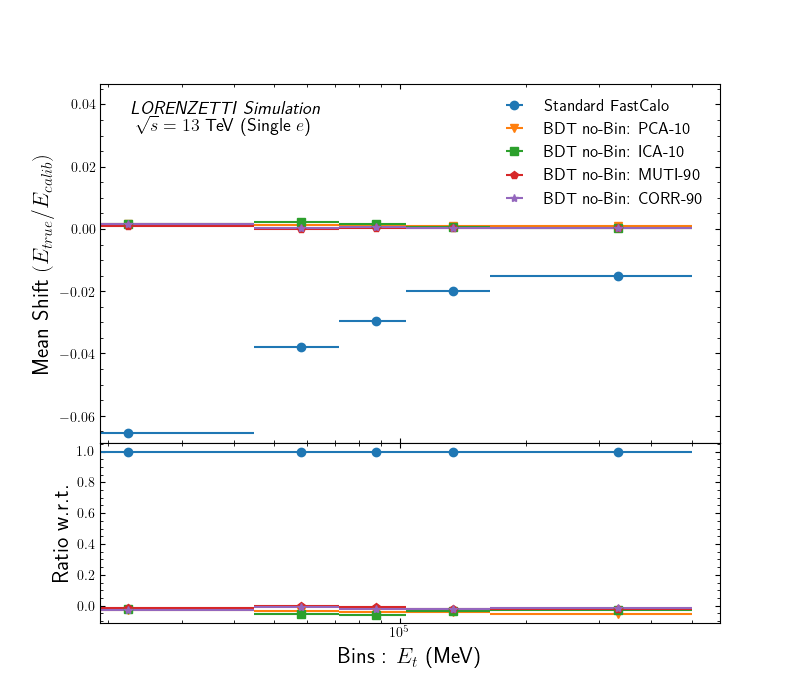

original_segmented_11.png


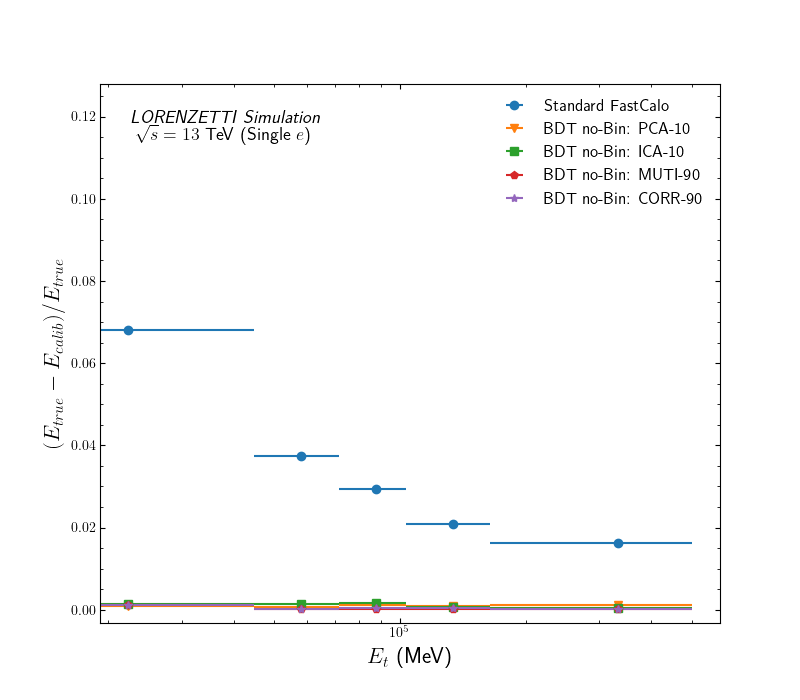

original_segmented_12.png


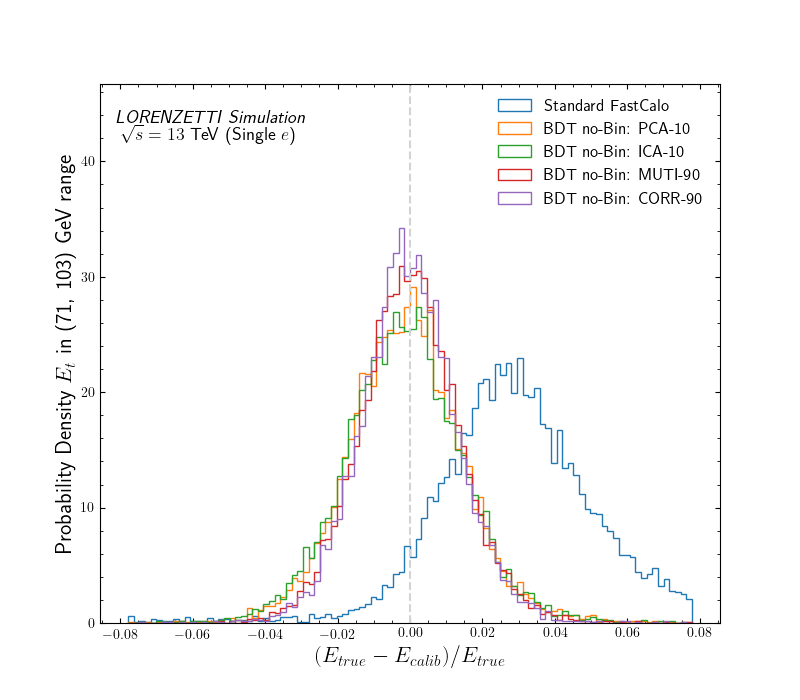

original_segmented_13.png


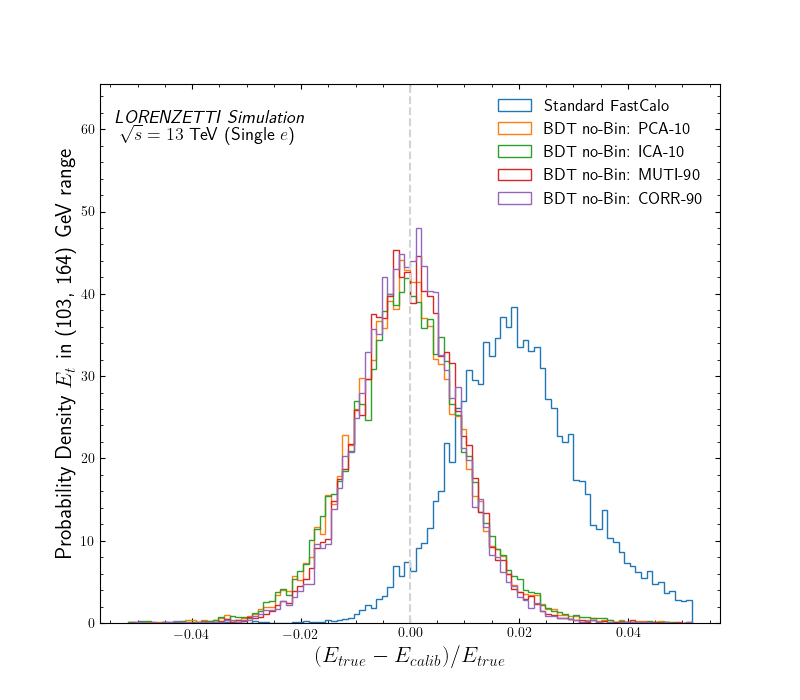

original_segmented_14.png


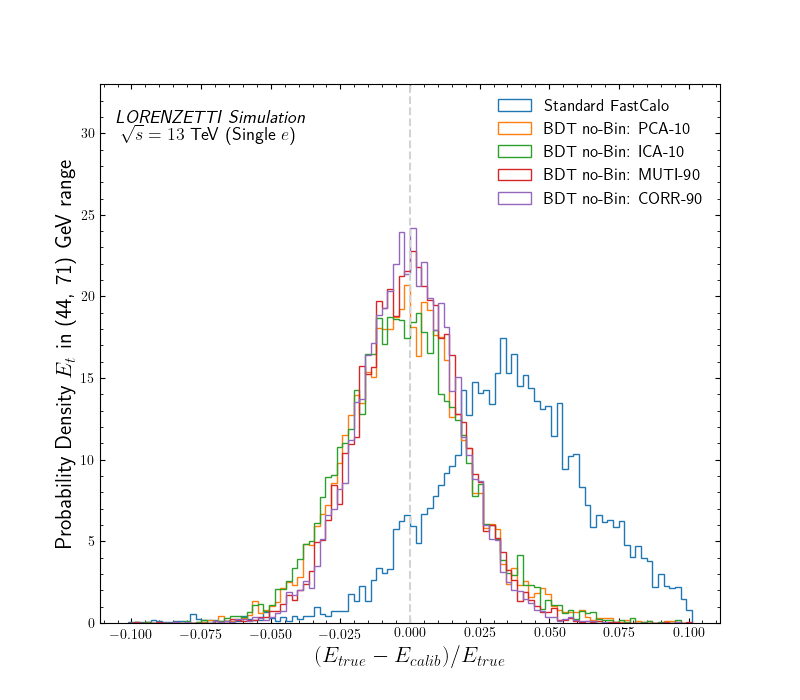

original_segmented_15.png


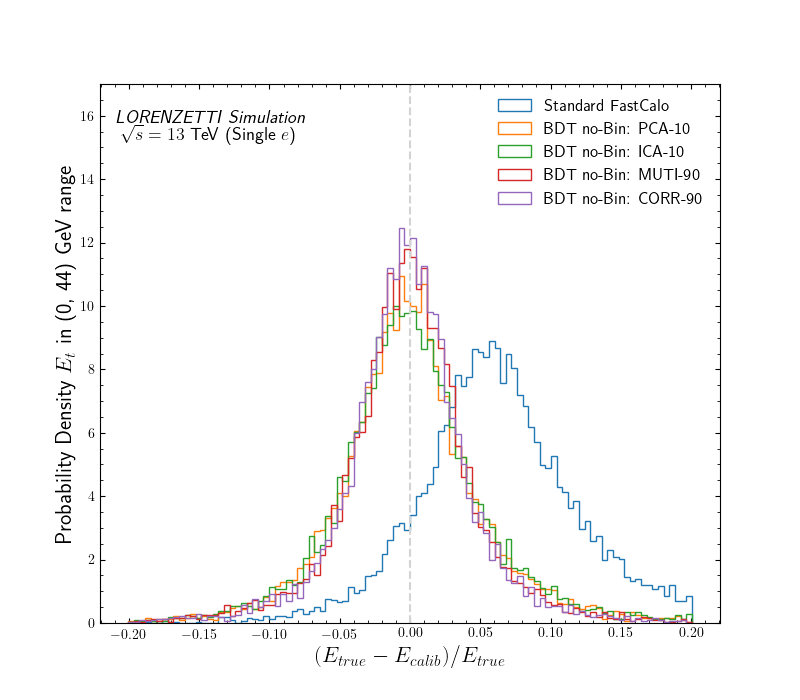

original_segmented_16.png


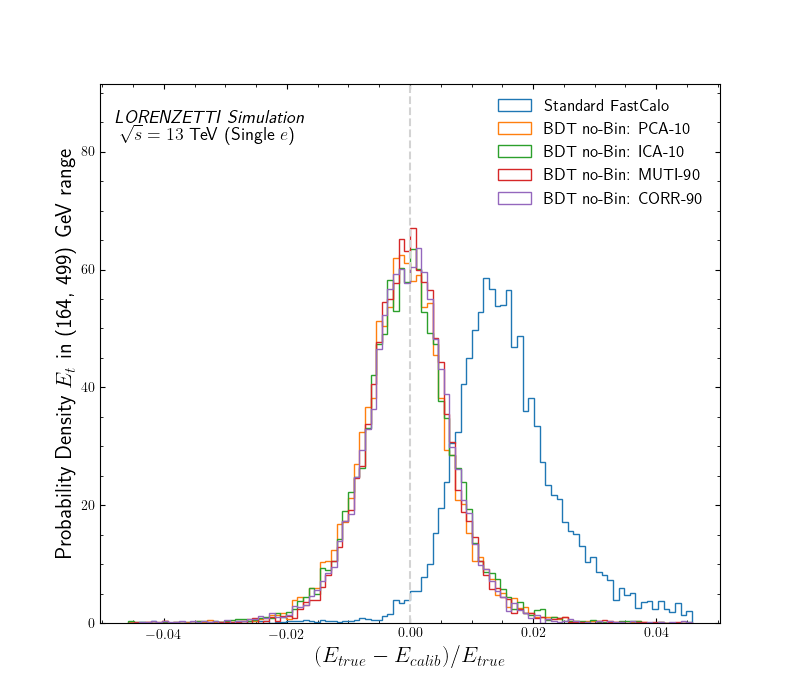

original_segmented_17.png


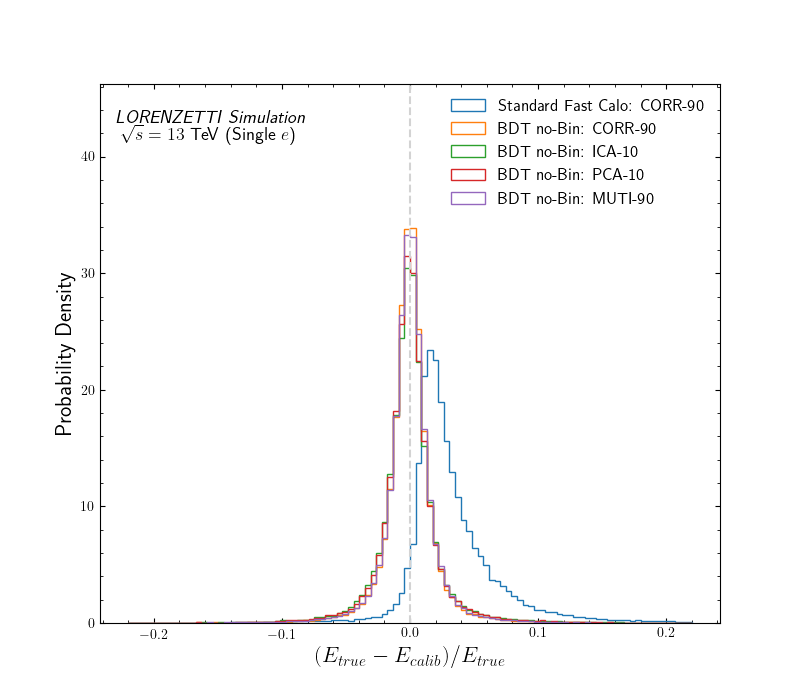

original_segmented_18.png


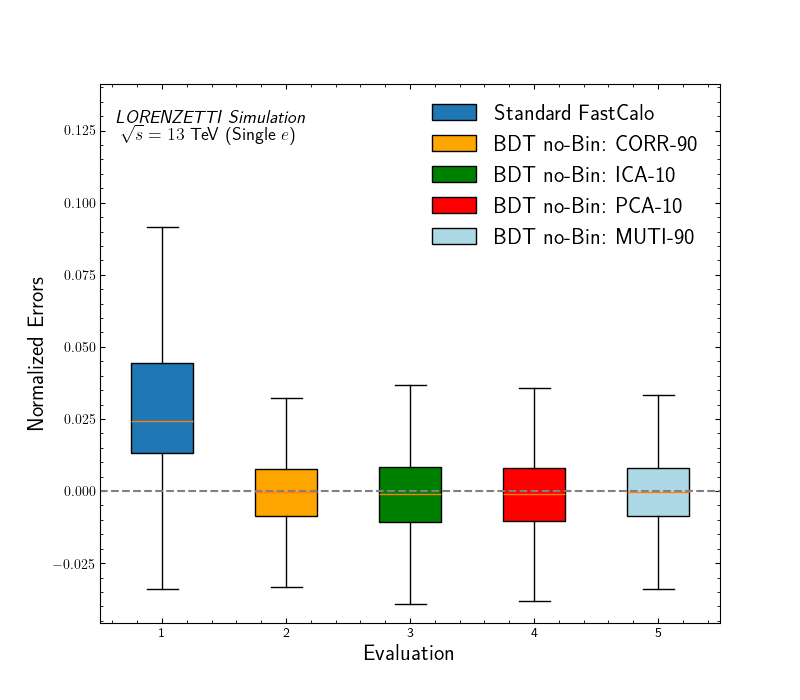

original_top10_residual_hist_box_01.png


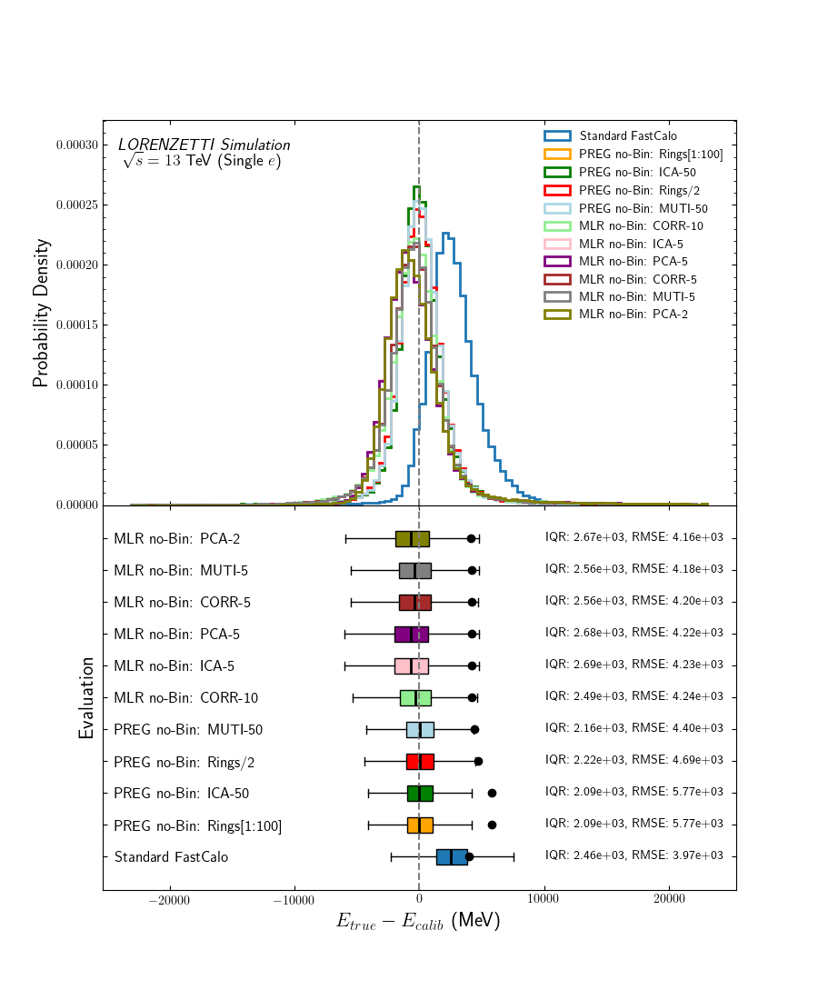

original_top10_boxplot_01.png


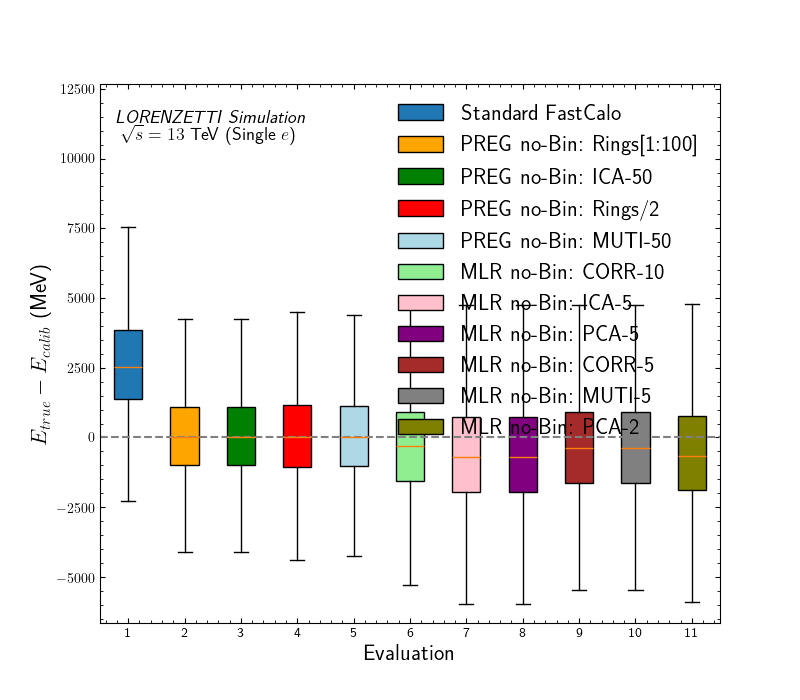

original_resolution_errorbars_01.png


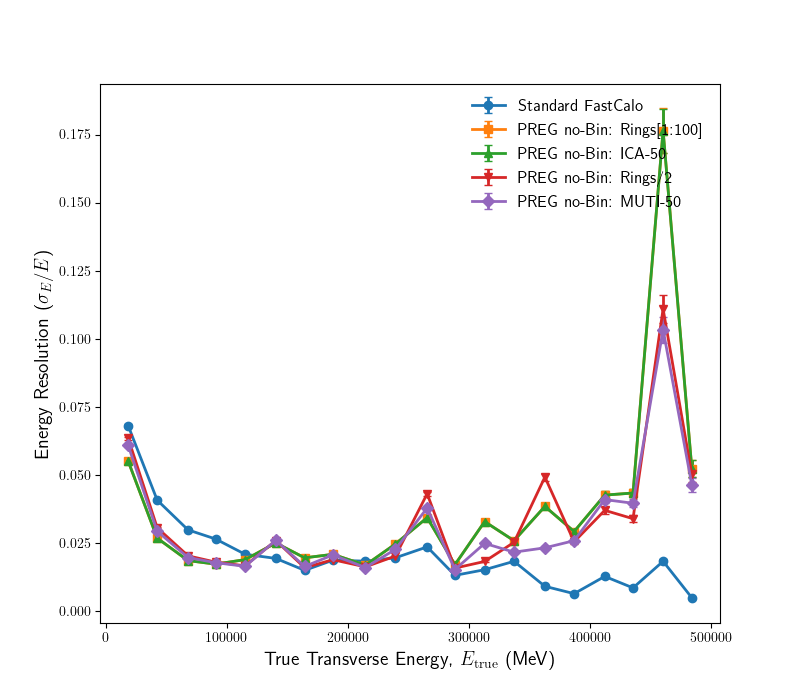

original_ranked_histogram_01.png


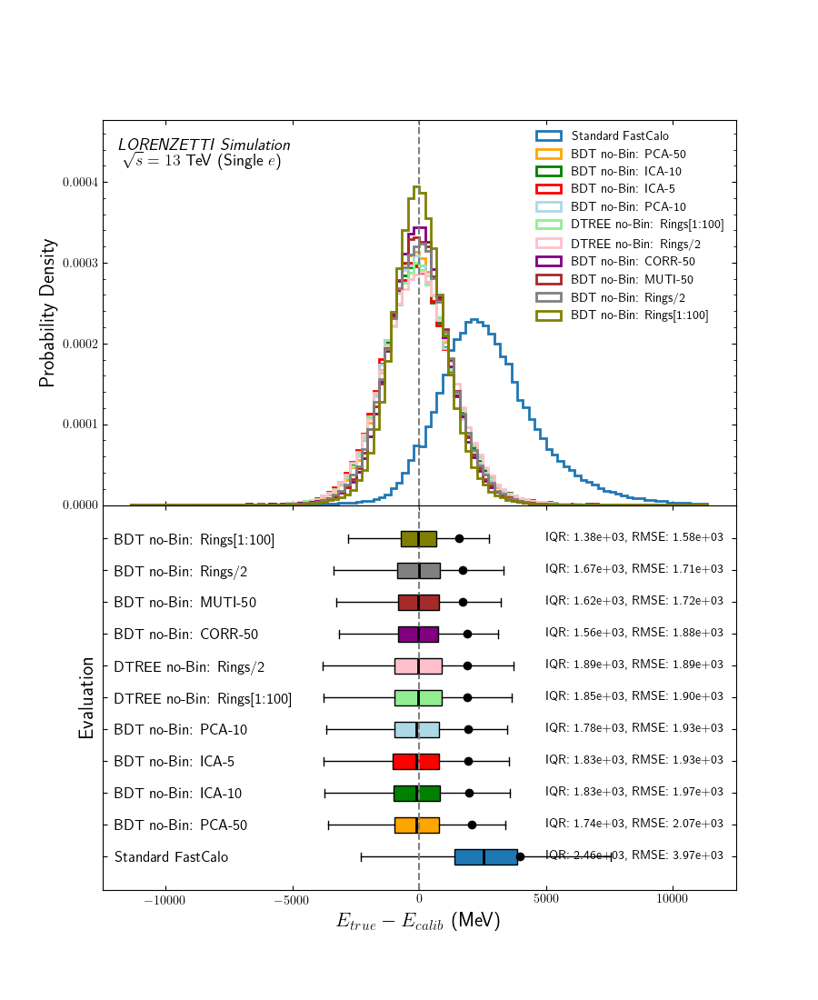

original_D0_ranked_d0_01.png


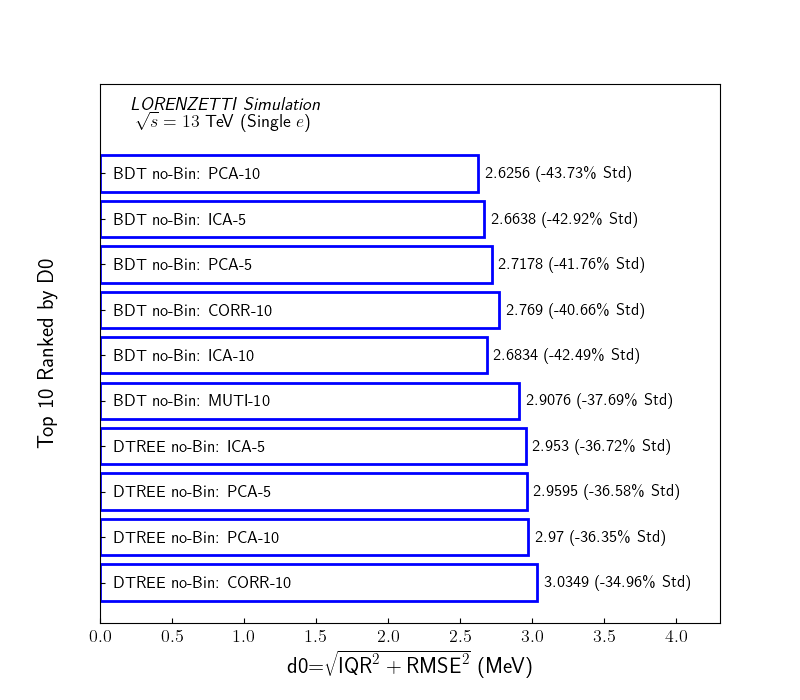

original_all_d0_comparison_01.png


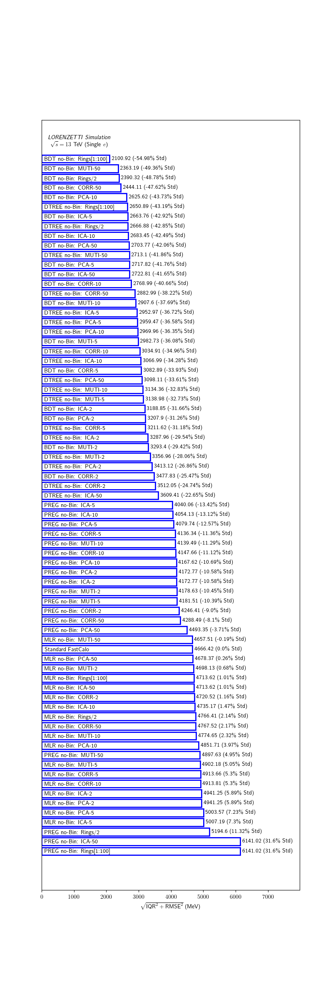

original_all_prediction_times_01.png


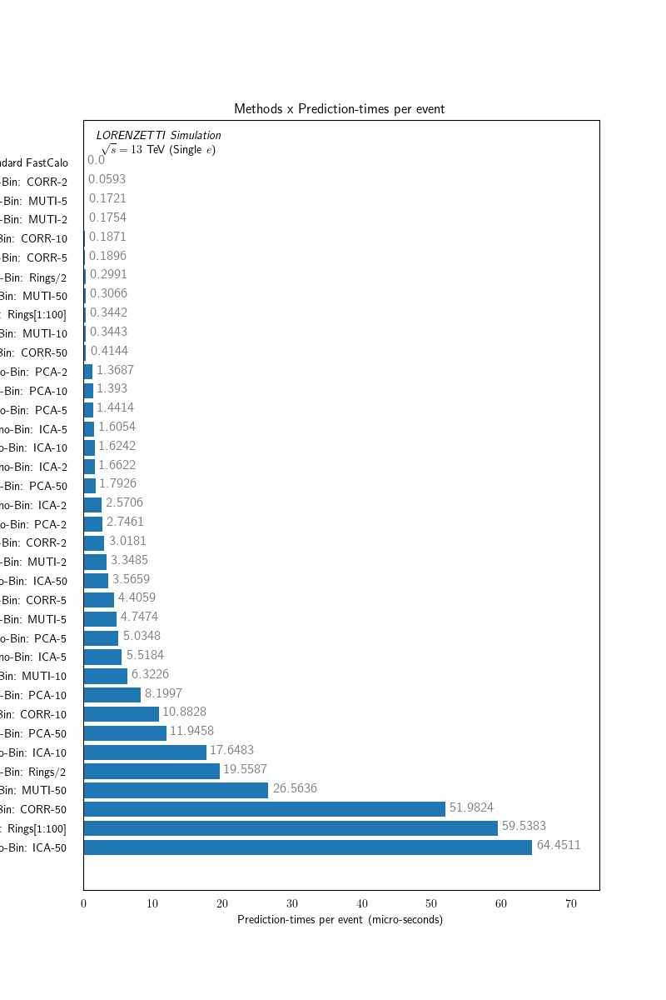

original_statistics_intervals_vertical_01.png


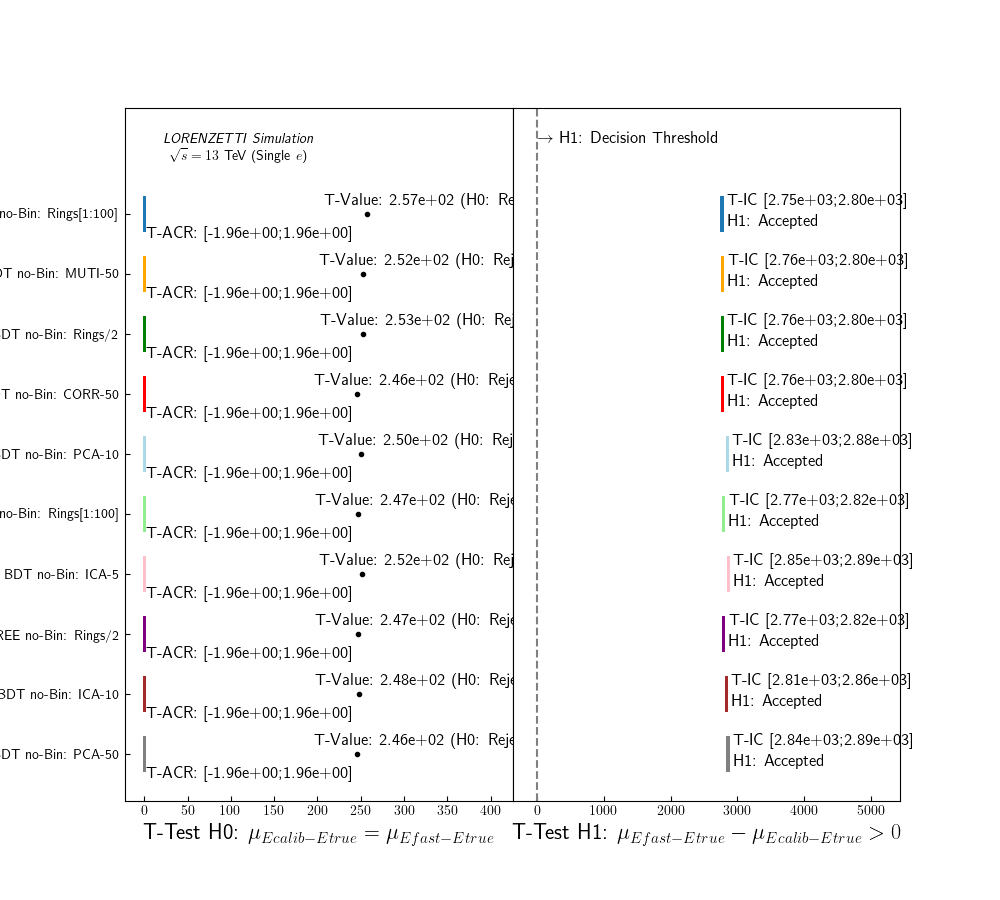

original_statistics_intervals_vertical_02.png


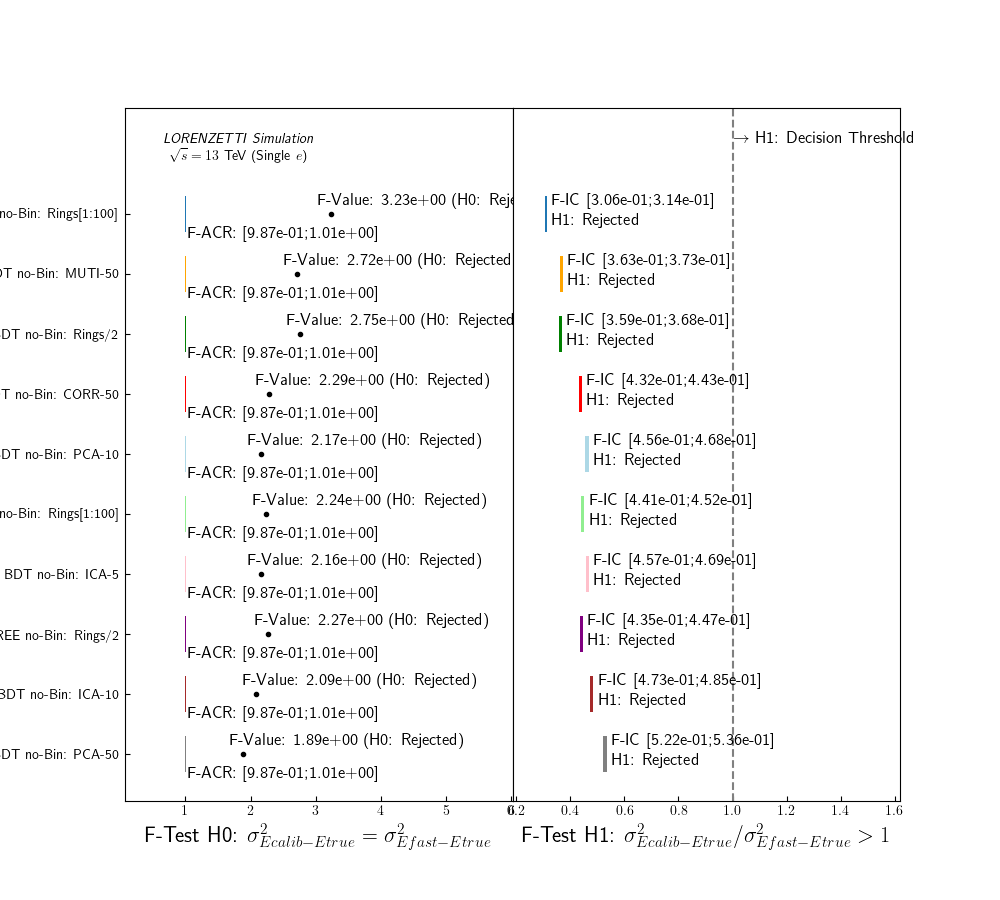

original_statistics_intervals_horizontal_01.png


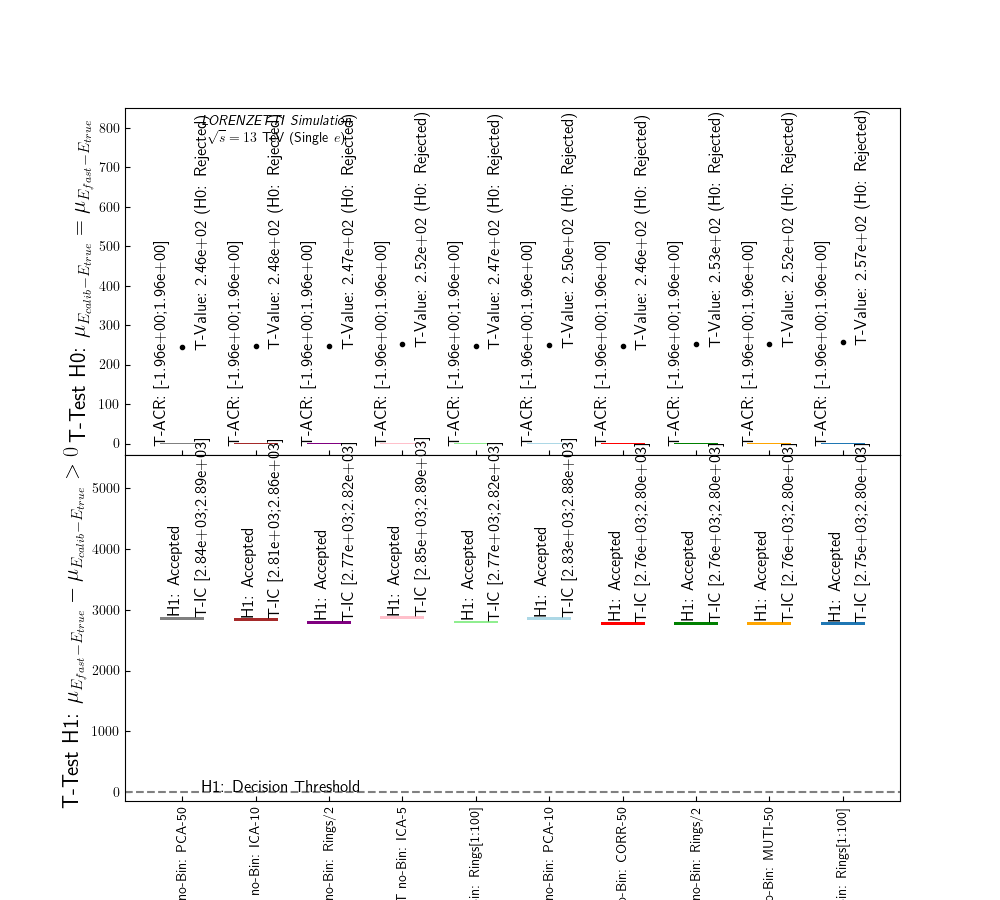

original_statistics_intervals_horizontal_02.png


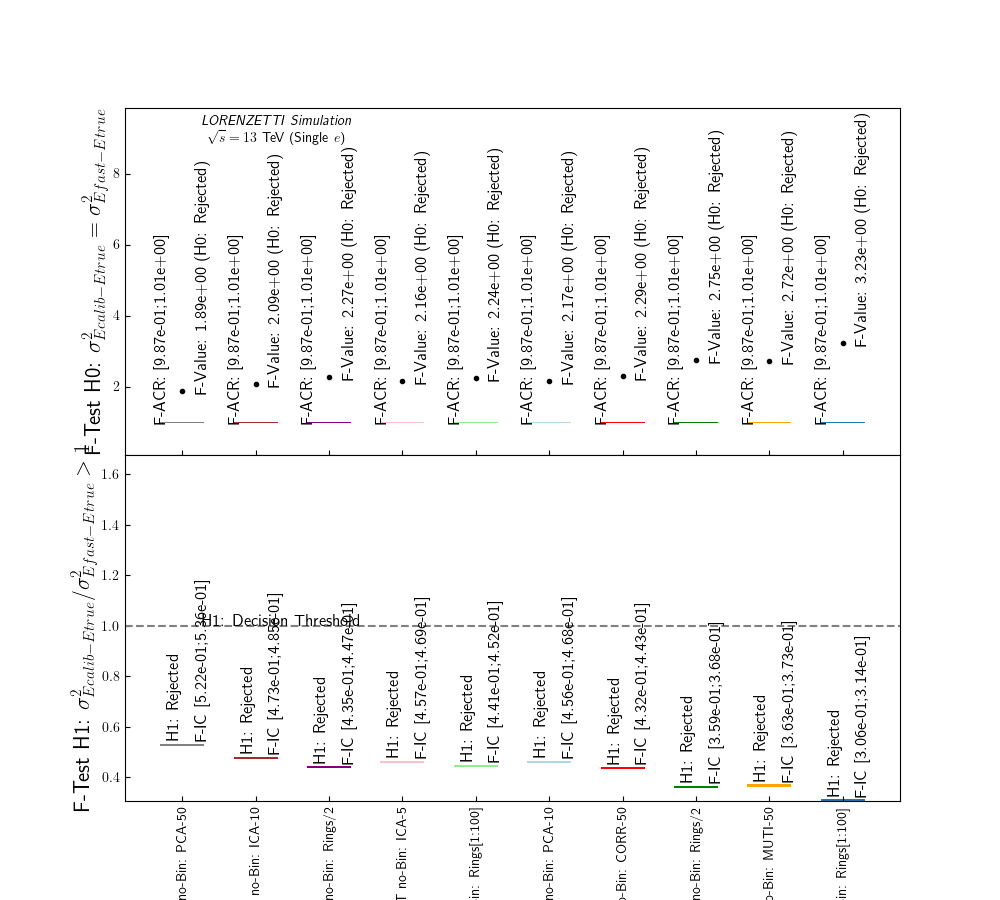

original_energy_histogram.png


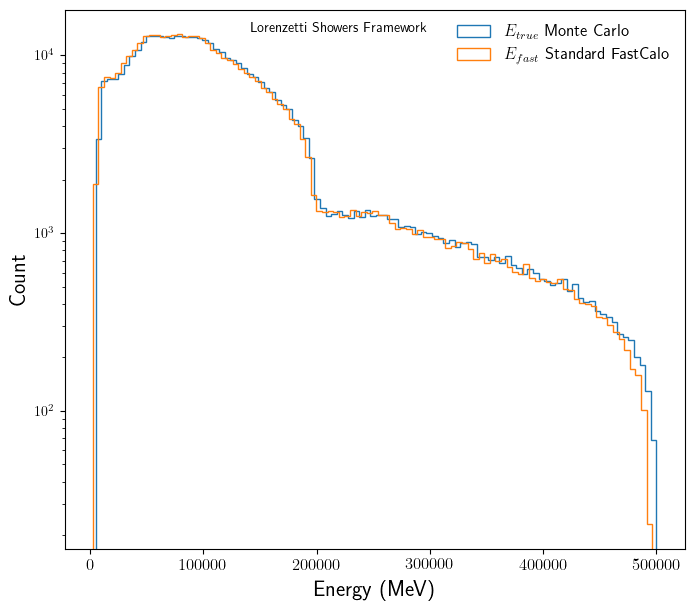

original_fast_vs_truth.png


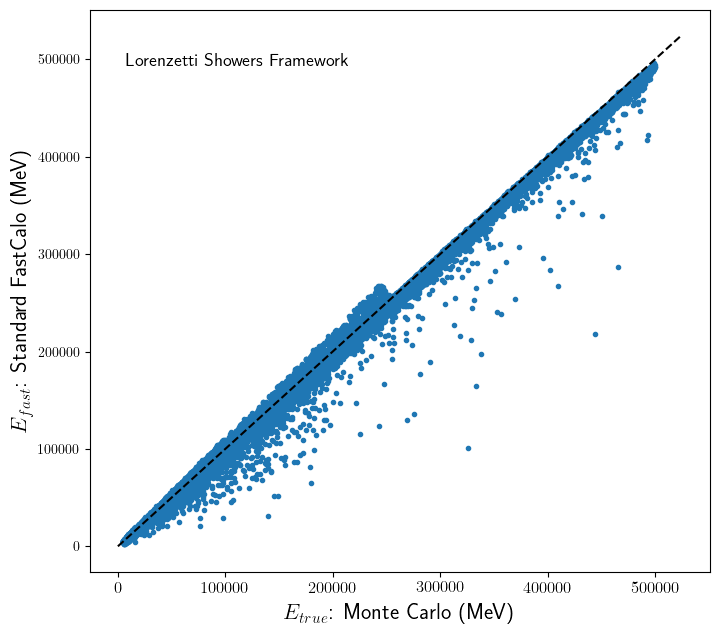

stage1_feature_relevance.png


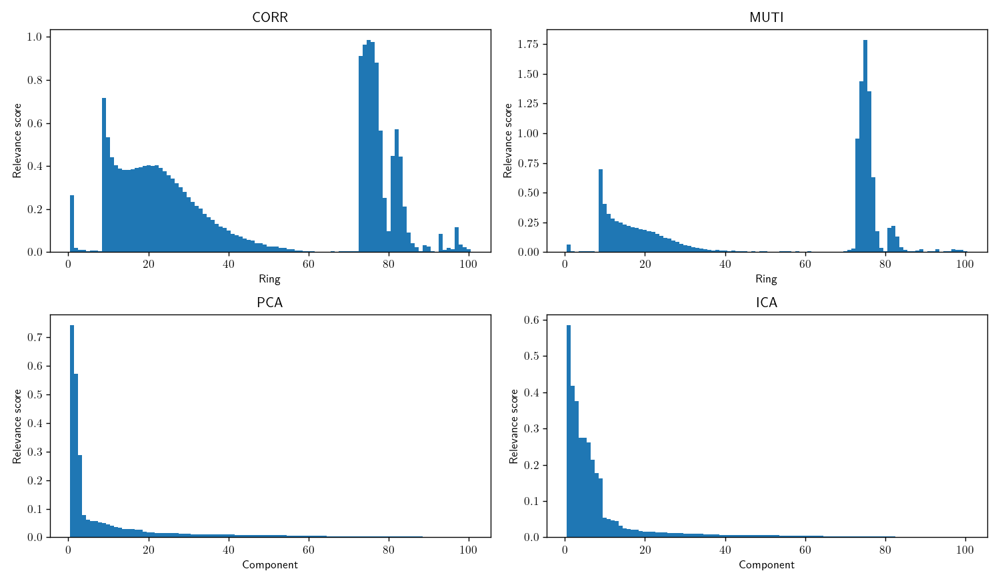

comparison_metric_cell702_01.png


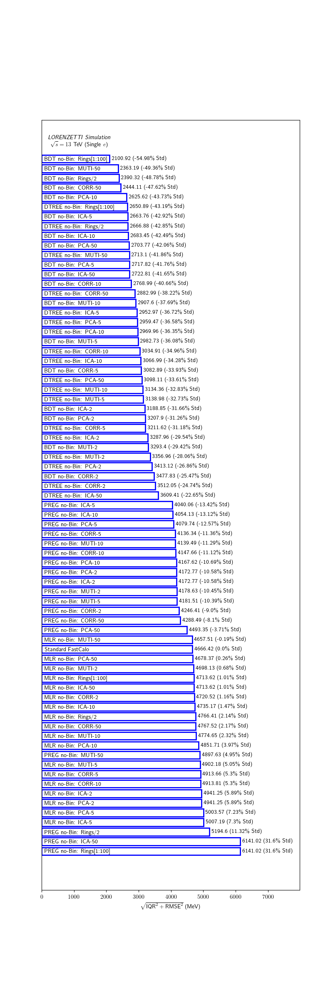

comparison_metric_all_cell705_01.png


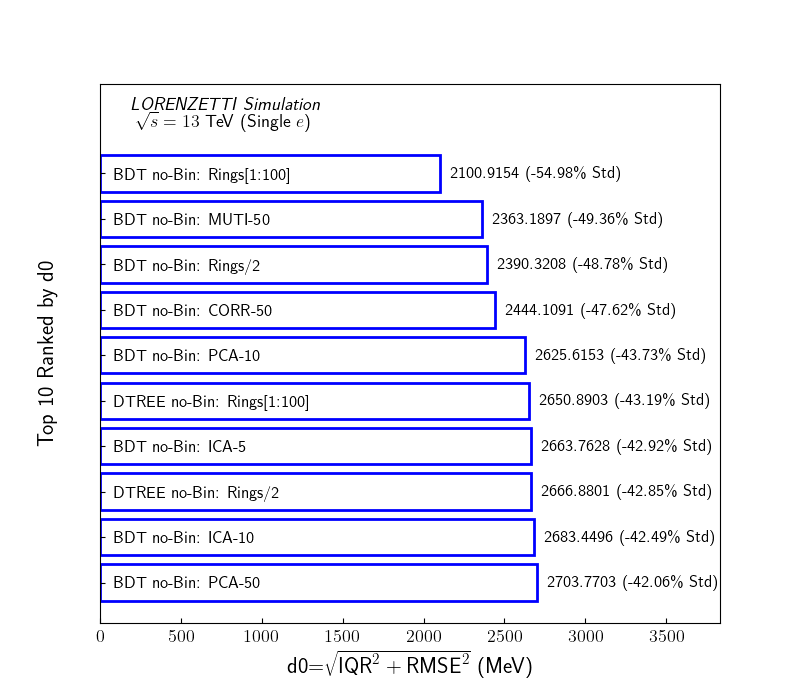

top_ten_residuals_cell749_01.png


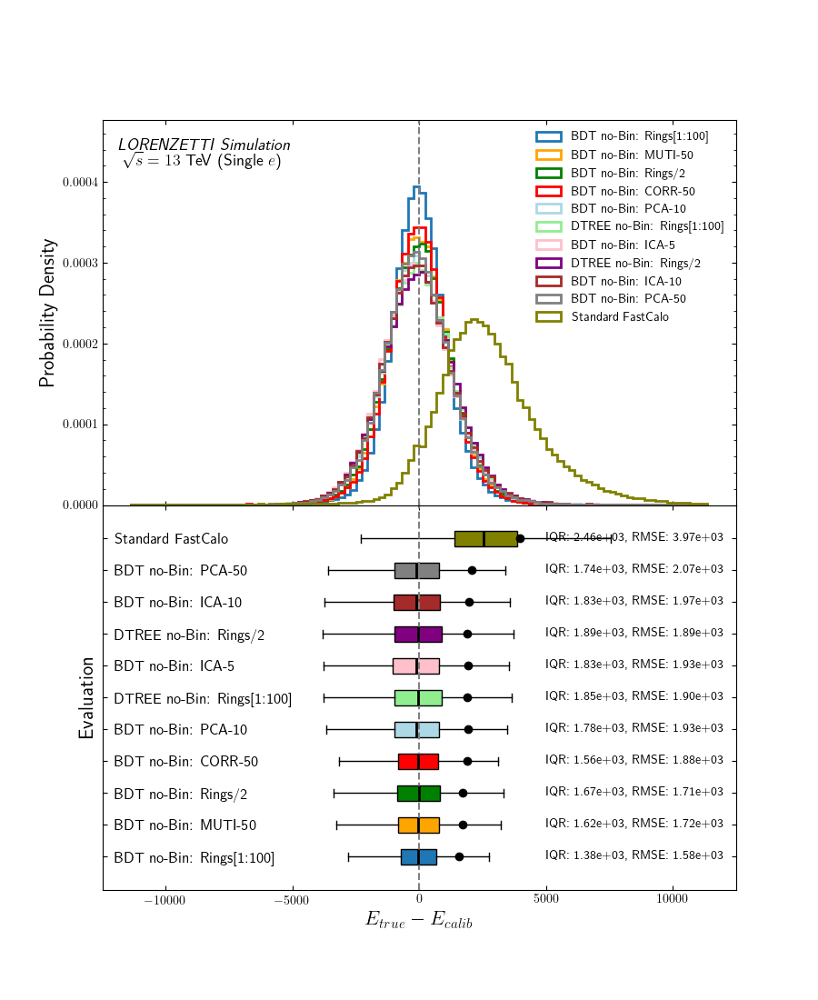

rmse_iqr_quadrant_cell767_01.png


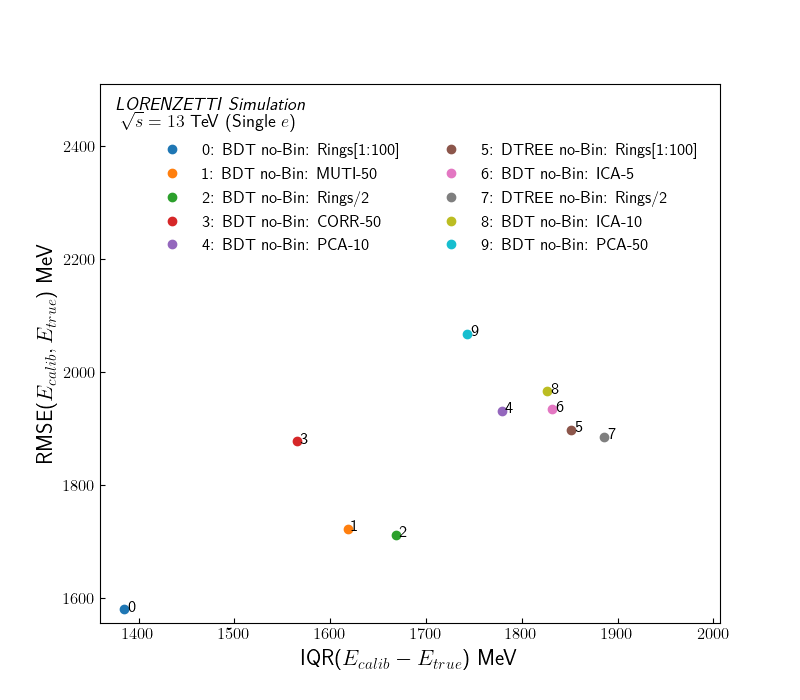

comparison_by_representation_CORR_10_01.png


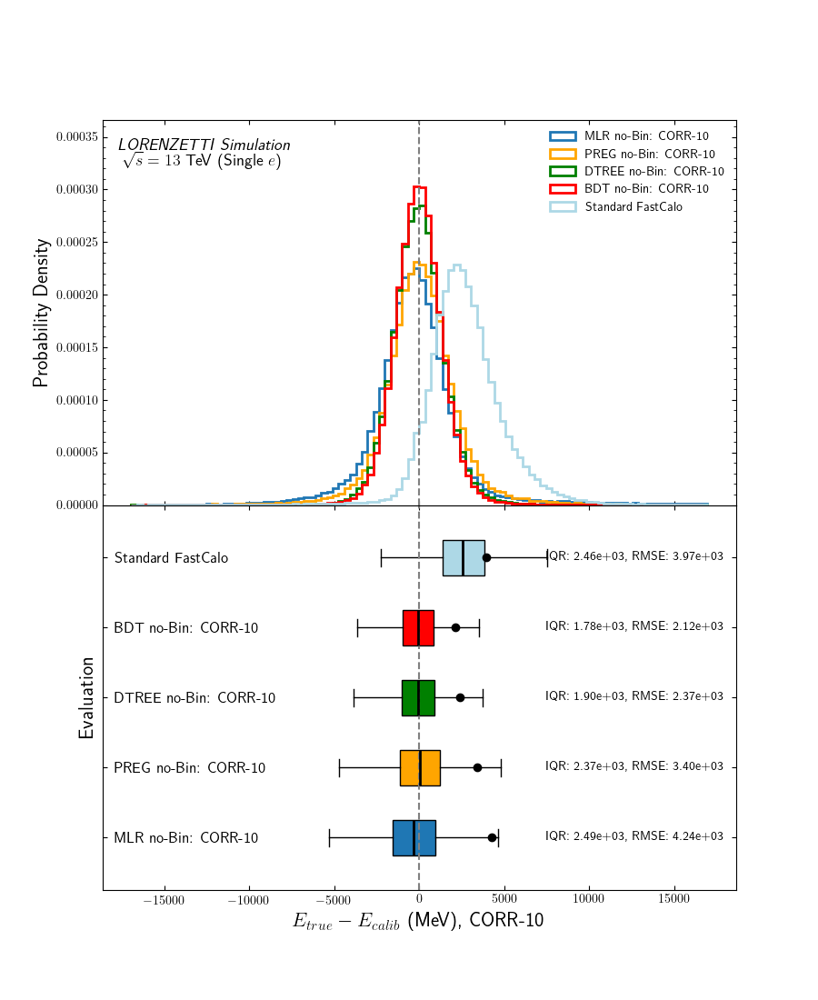

comparison_by_representation_CORR_2_01.png


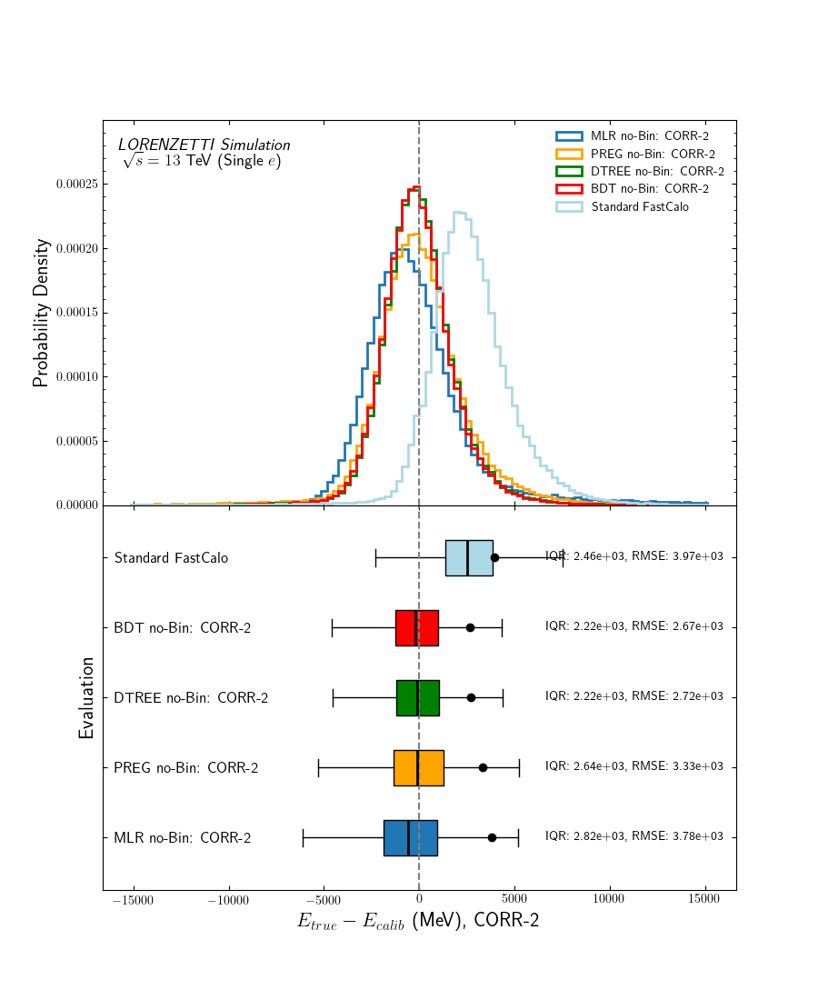

comparison_by_representation_CORR_5_01.png


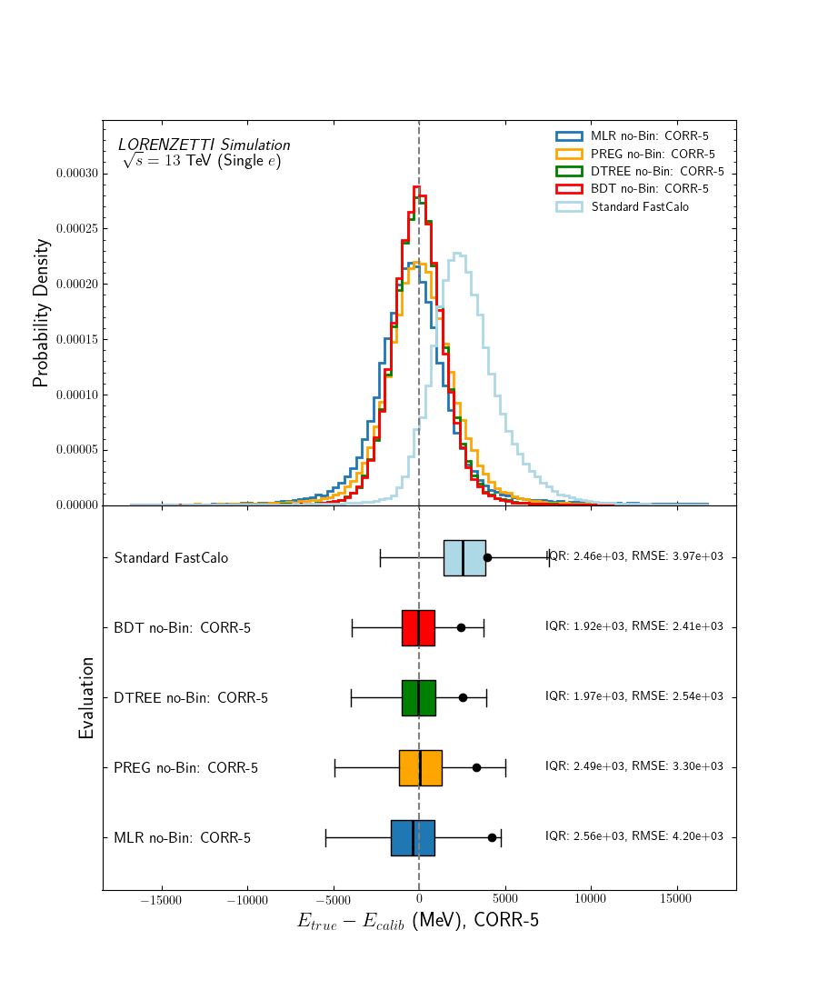

comparison_by_representation_CORR_50_01.png


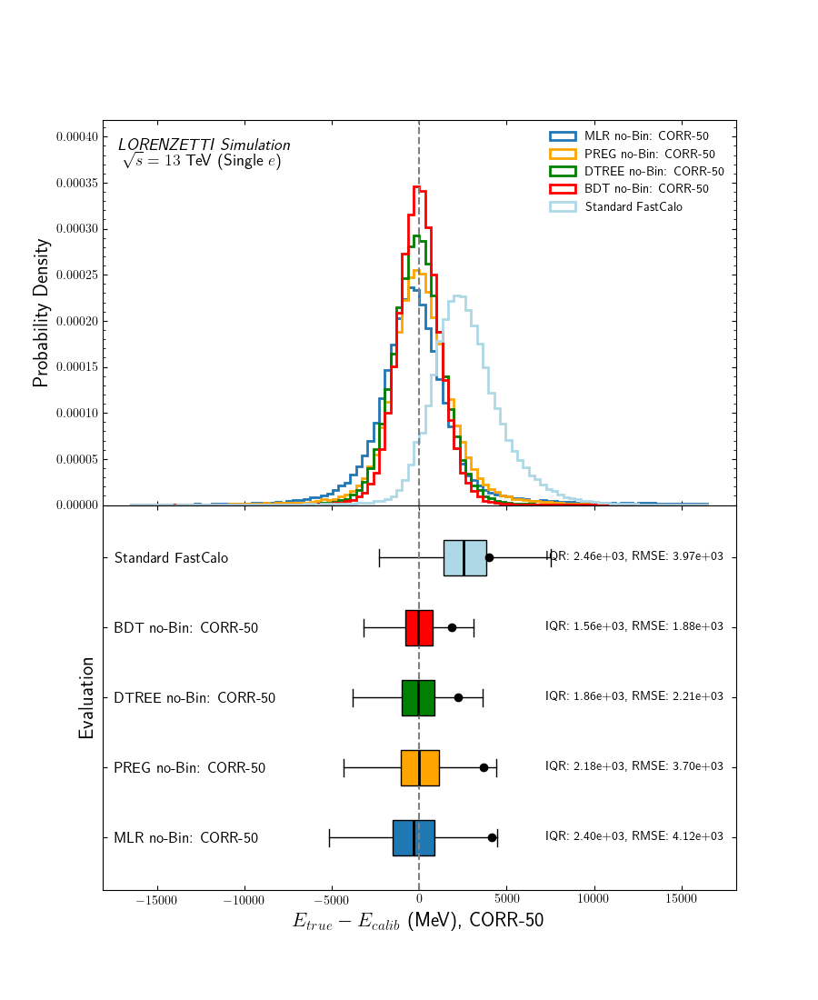

comparison_by_representation_ICA_10_01.png


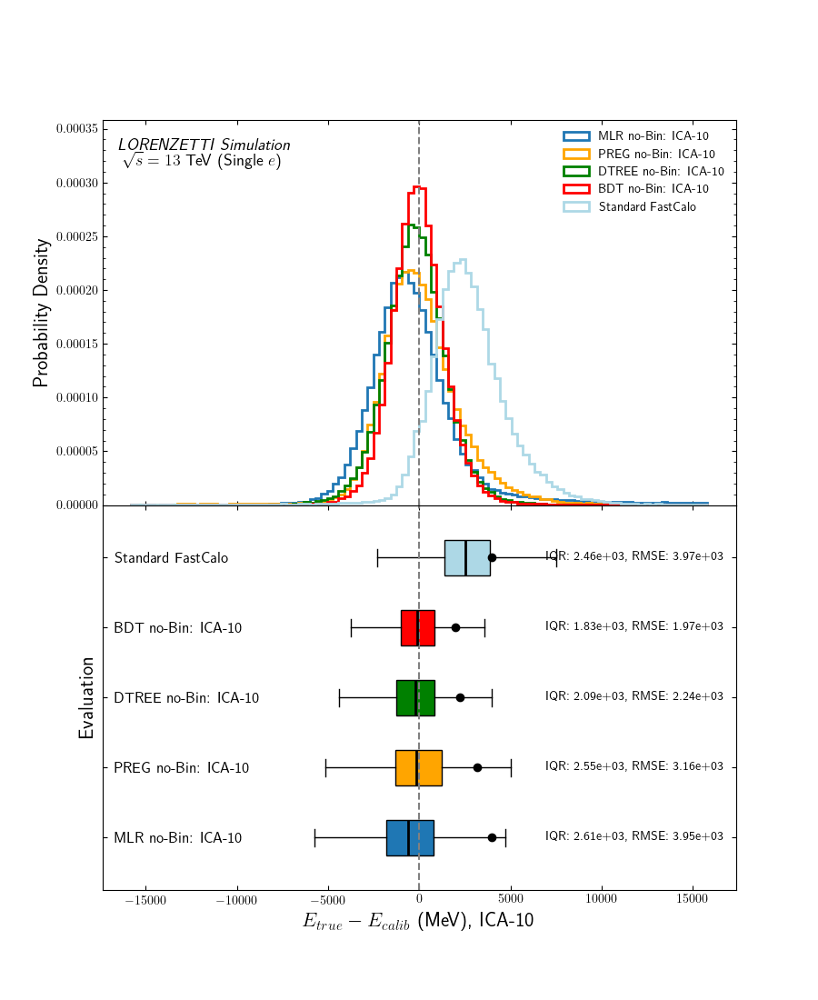

comparison_by_representation_ICA_2_01.png


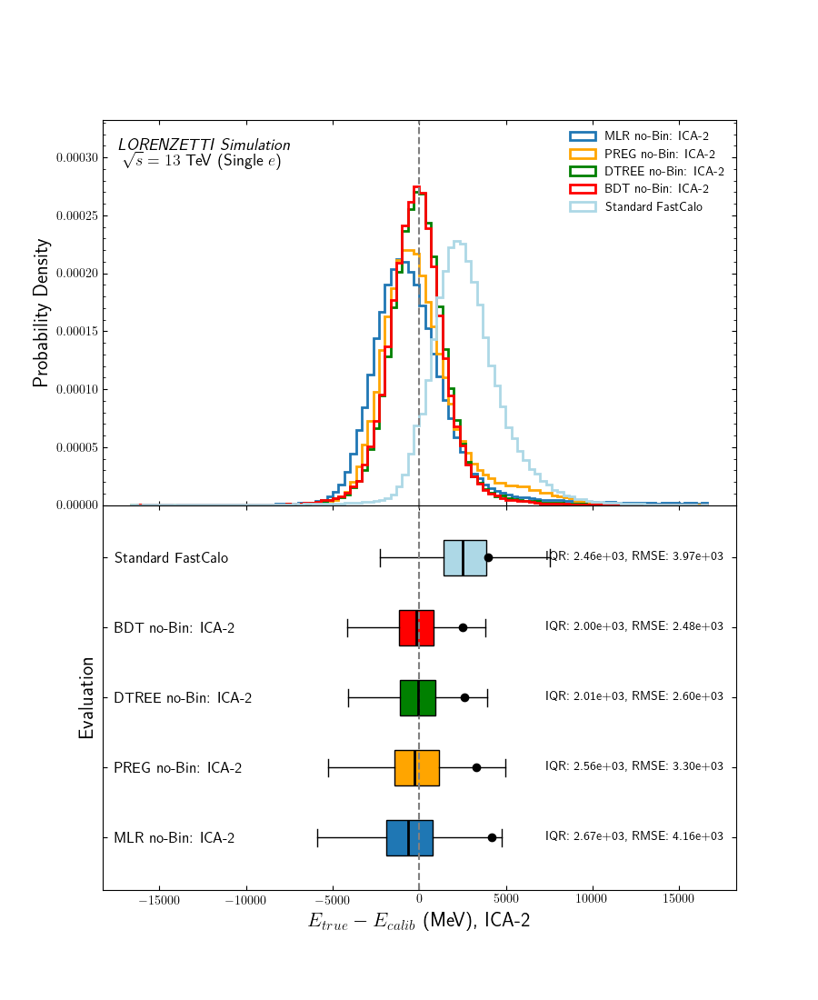

comparison_by_representation_ICA_5_01.png


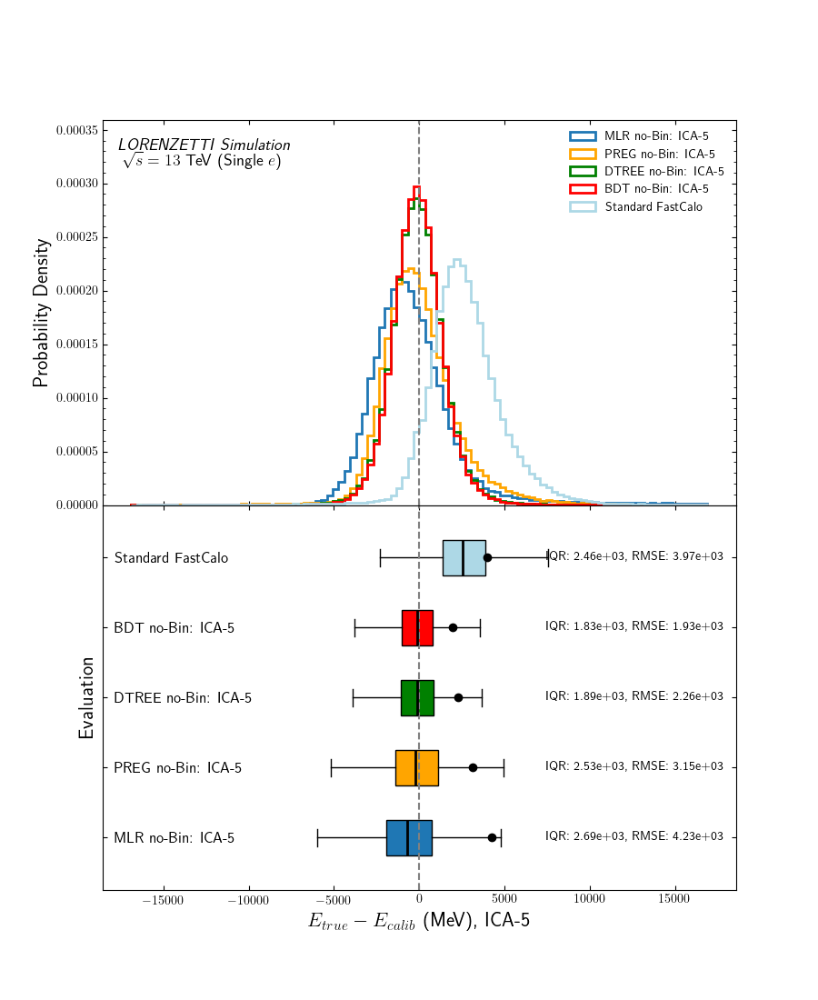

comparison_by_representation_ICA_50_01.png


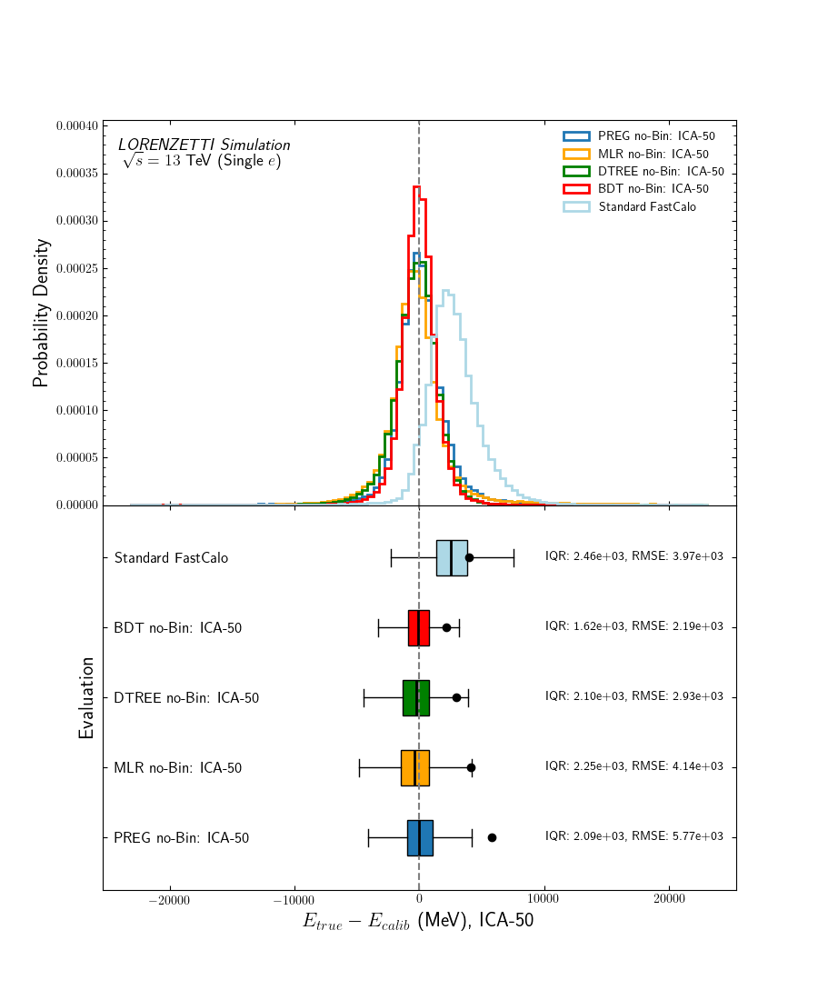

comparison_by_representation_MUTI_10_01.png


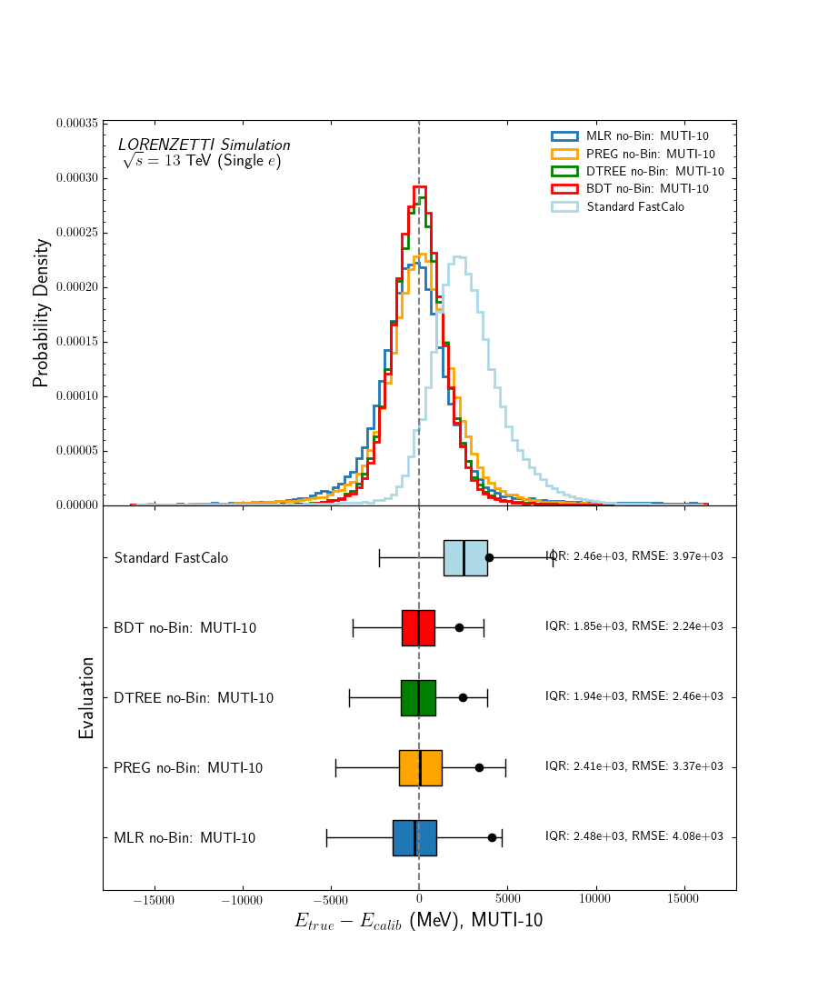

comparison_by_representation_MUTI_2_01.png


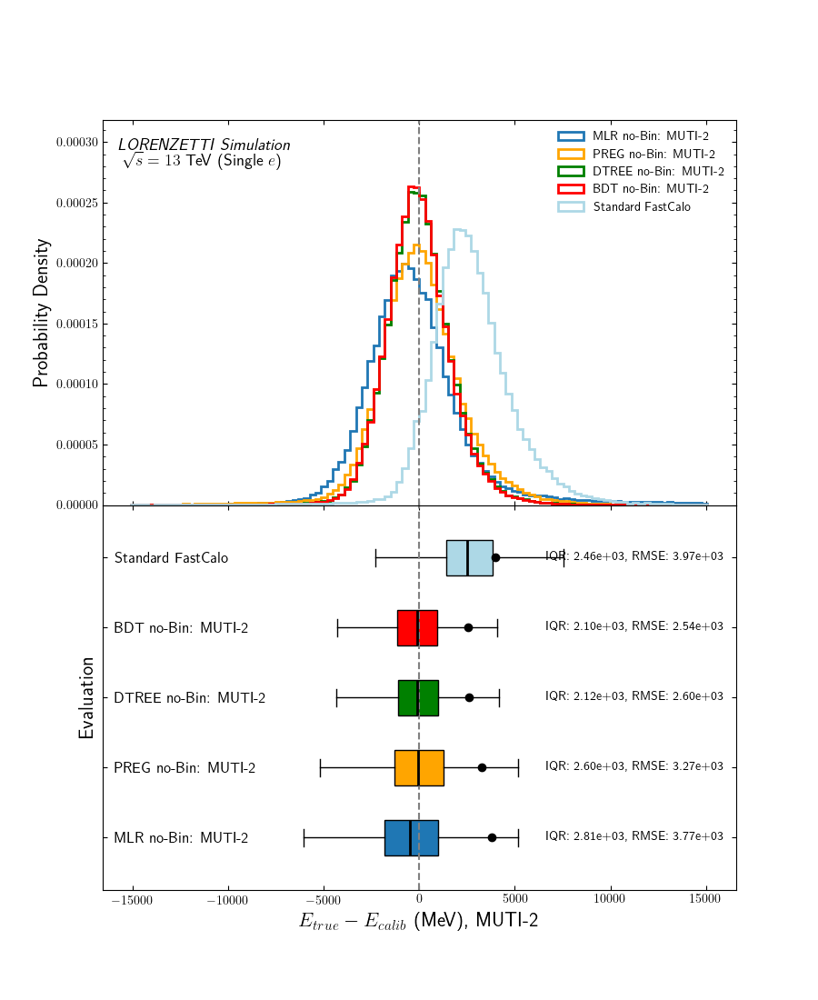

comparison_by_representation_MUTI_5_01.png


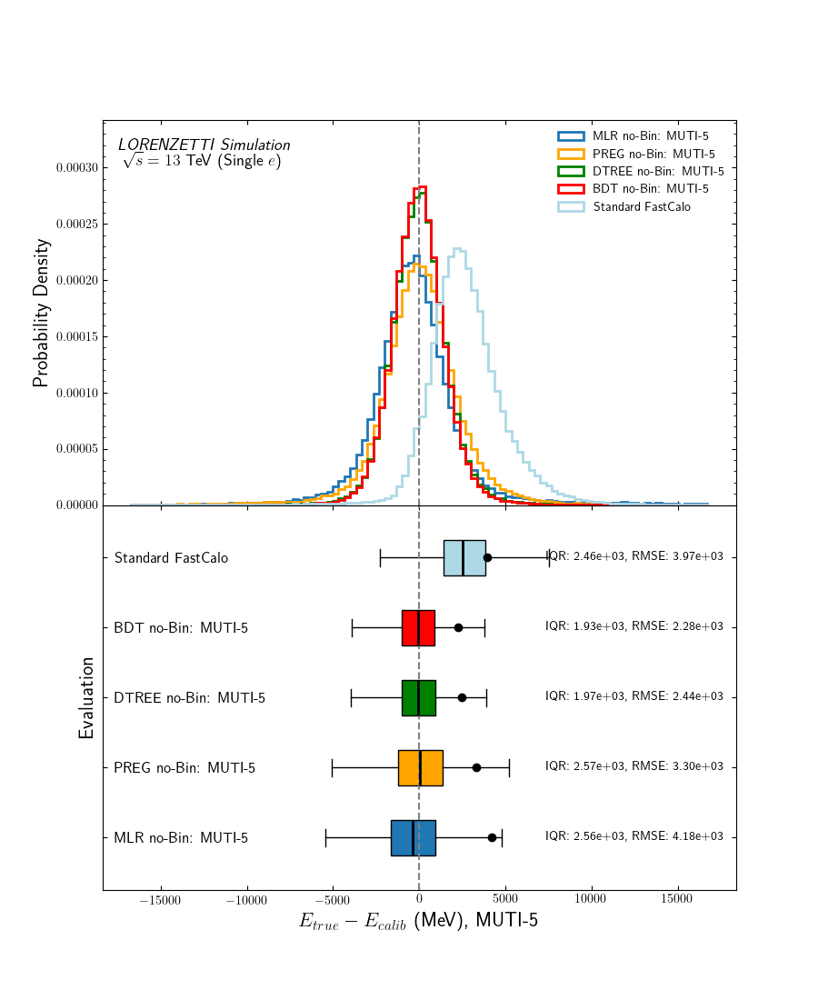

comparison_by_representation_MUTI_50_01.png


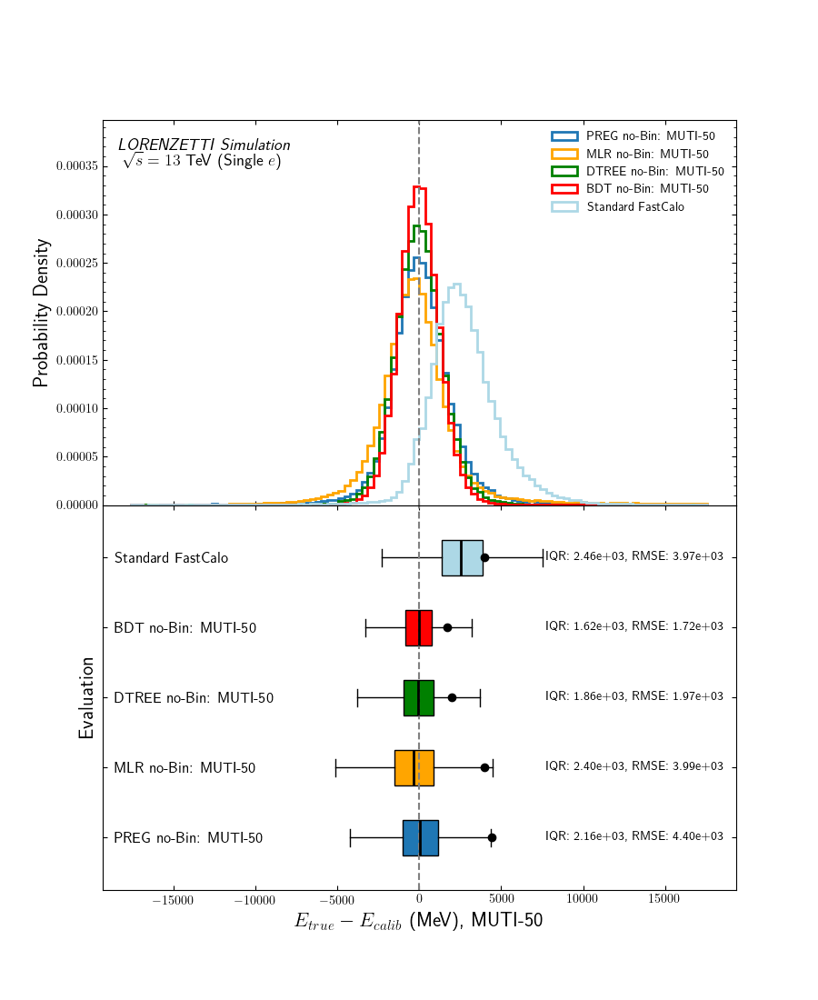

comparison_by_representation_PCA_10_01.png


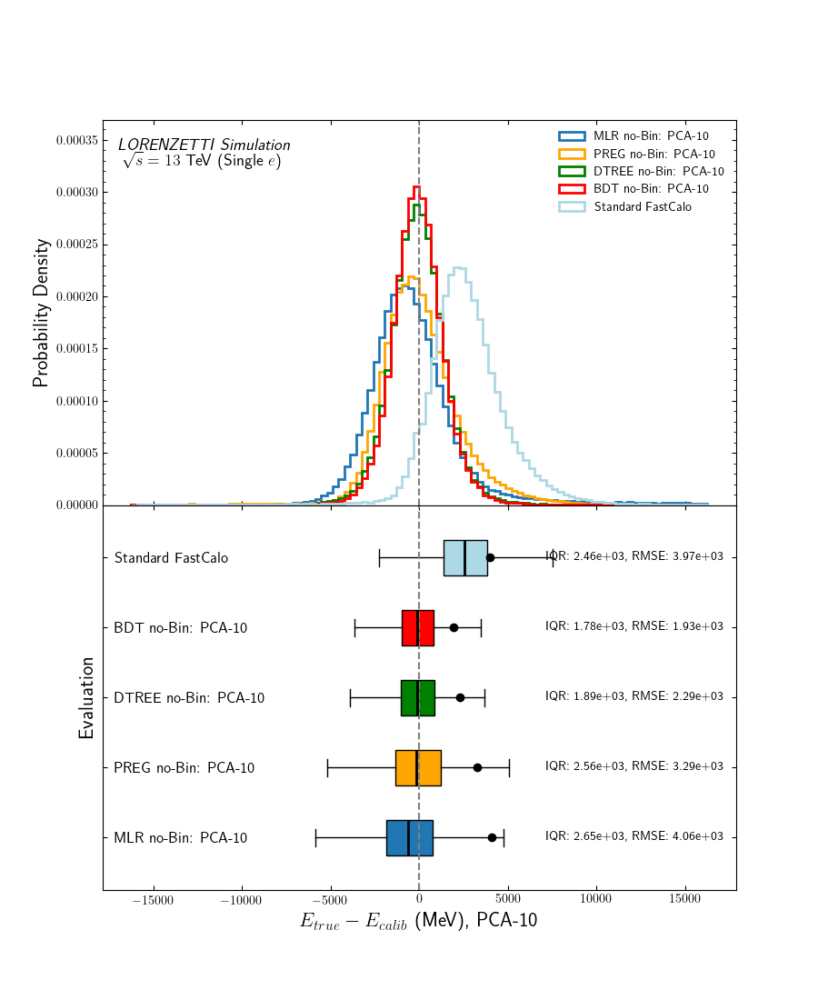

comparison_by_representation_PCA_2_01.png


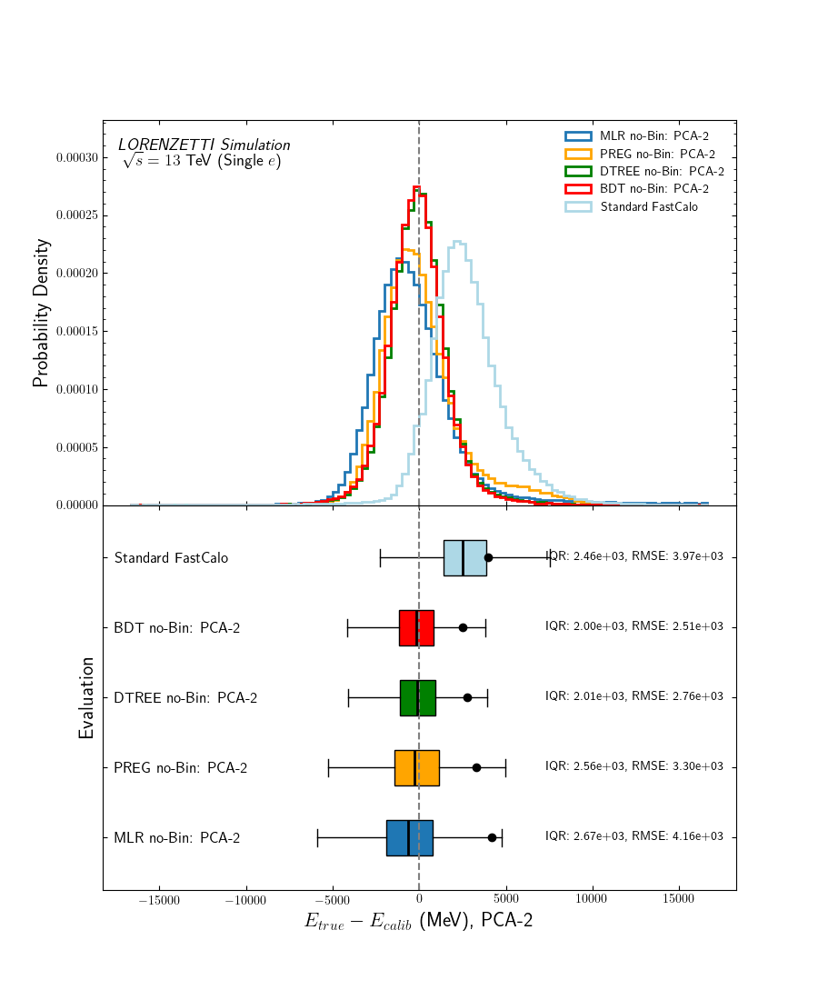

comparison_by_representation_PCA_5_01.png


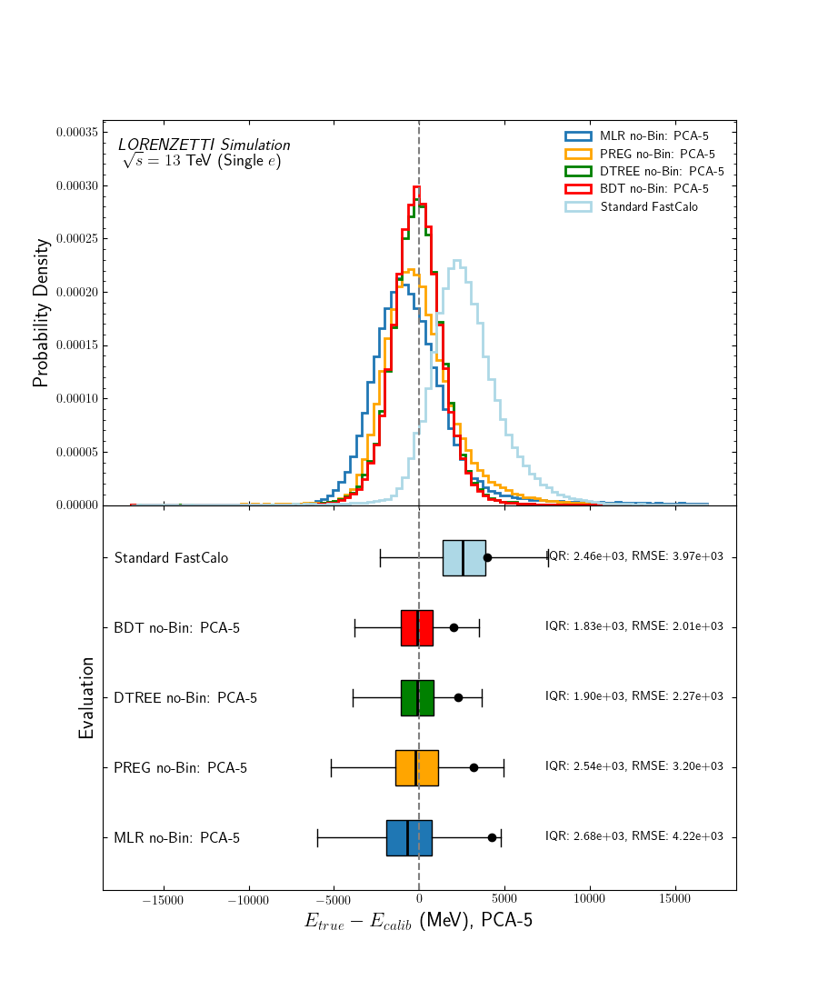

comparison_by_representation_PCA_50_01.png


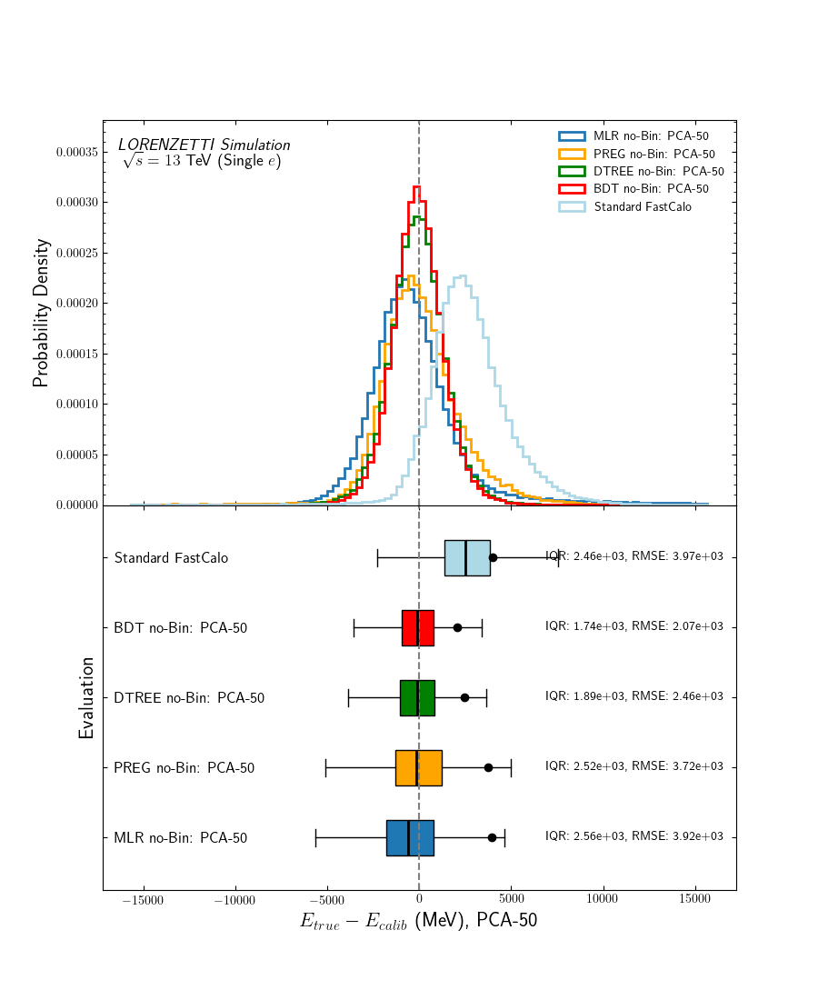

comparison_by_representation_Rings_2_01.png


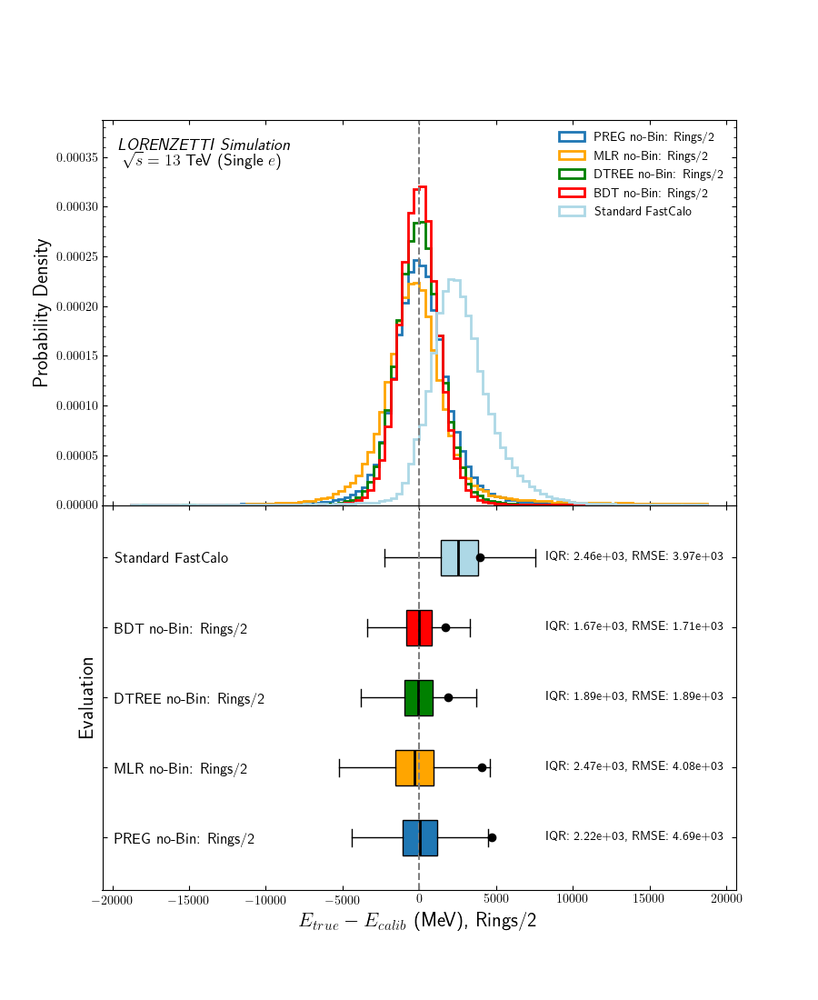

comparison_by_representation_Rings_1_100_01.png


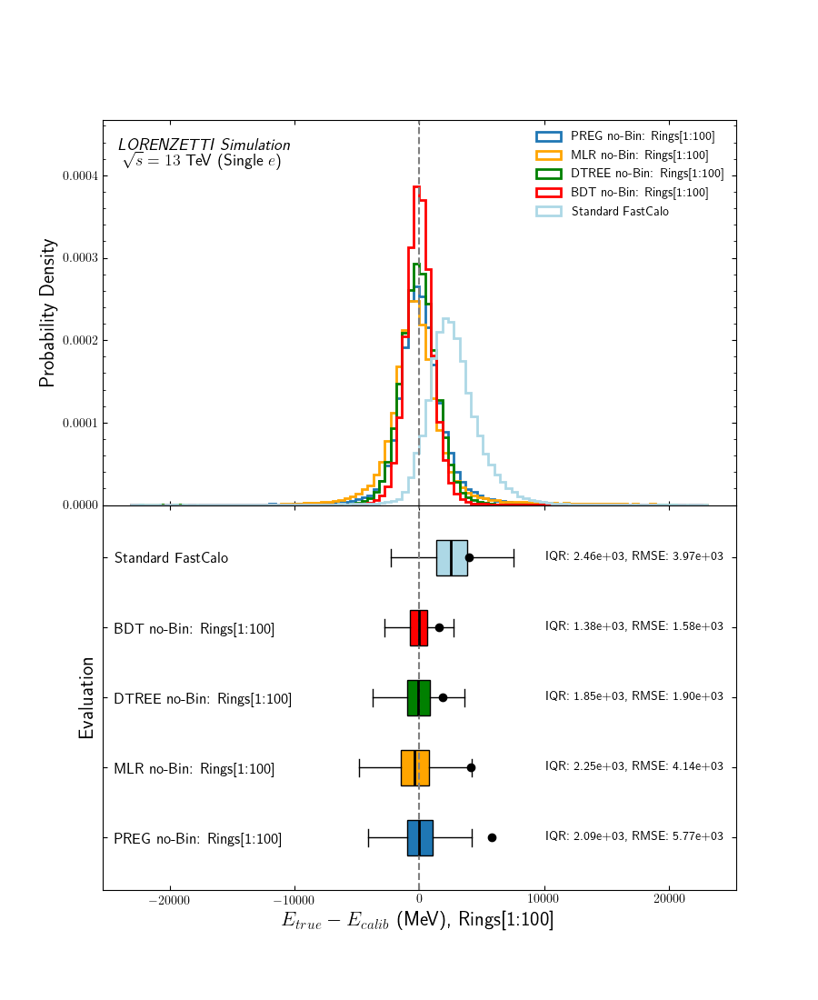

comparison_by_family_rings_cell747_01.png


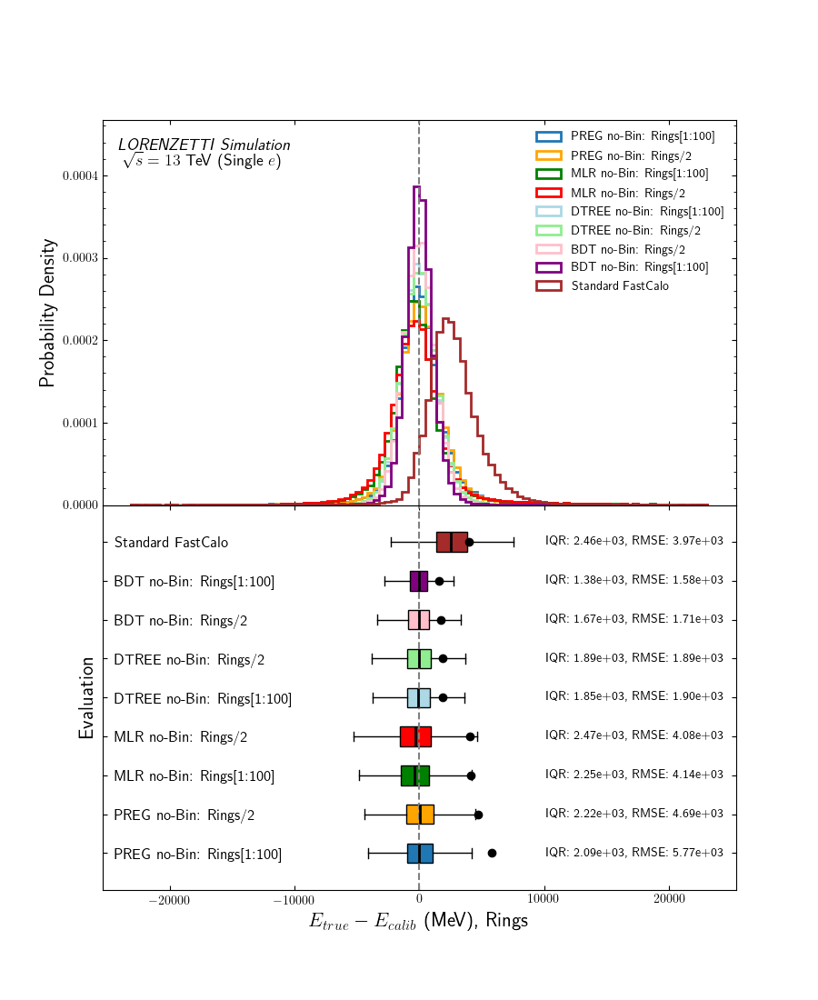

comparison_by_family_corr_cell747_01.png


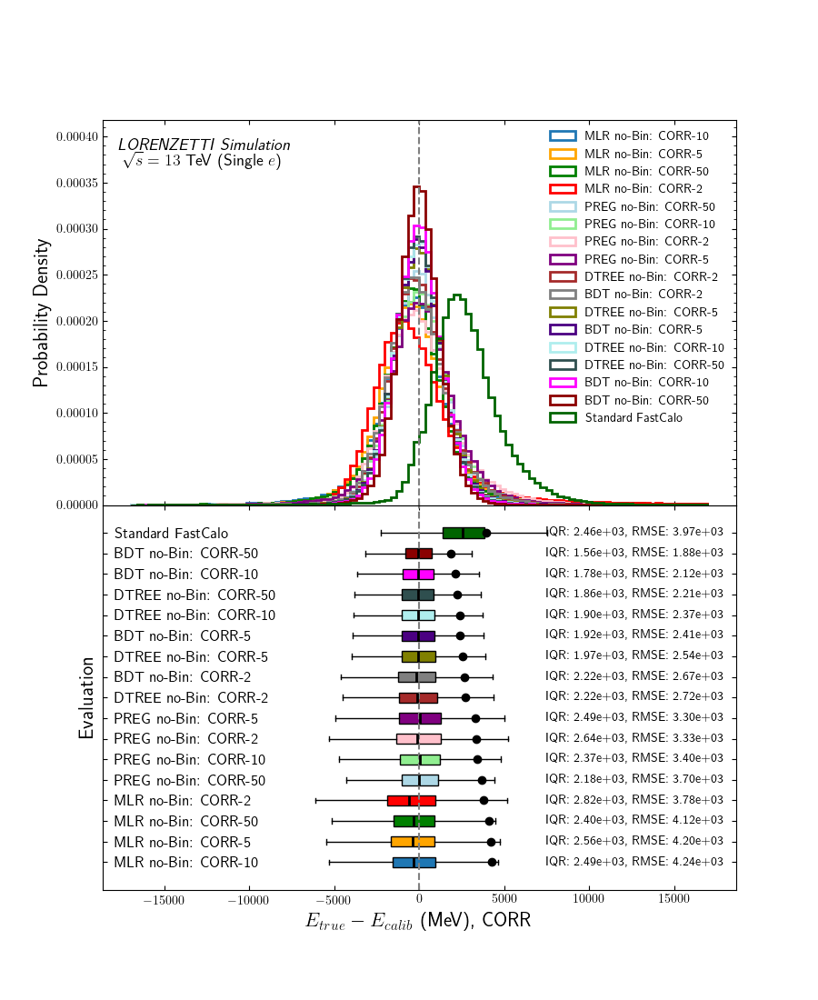

comparison_by_family_muti_cell747_01.png


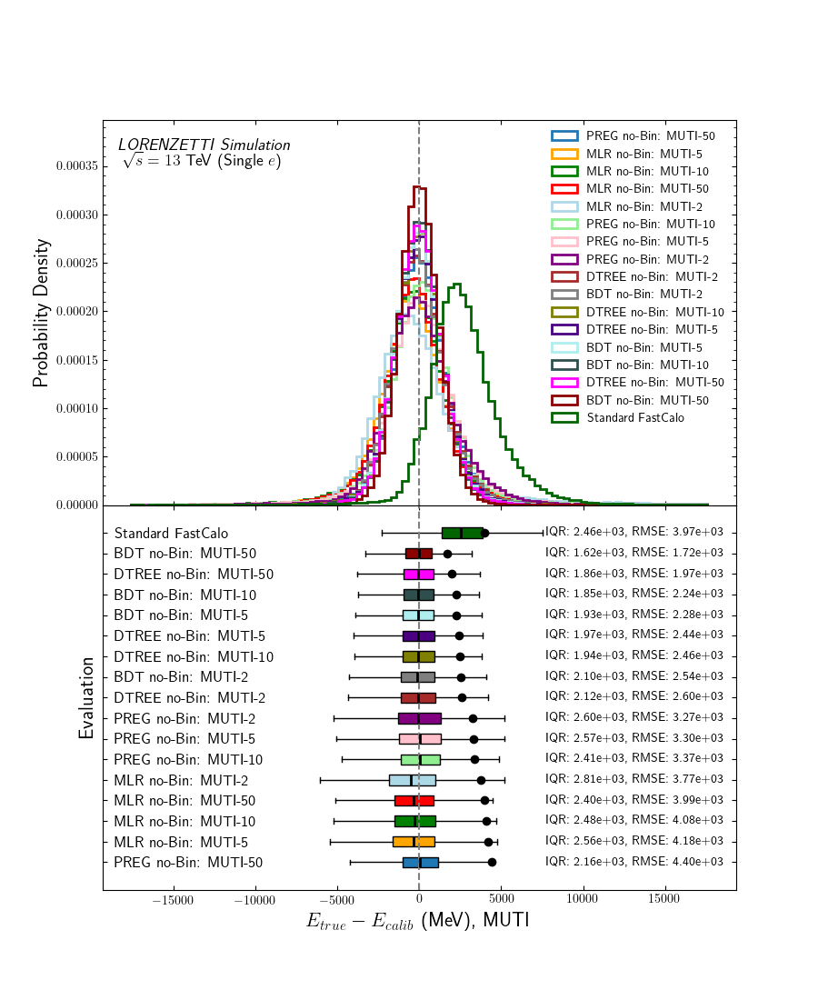

comparison_by_family_pca_cell747_01.png


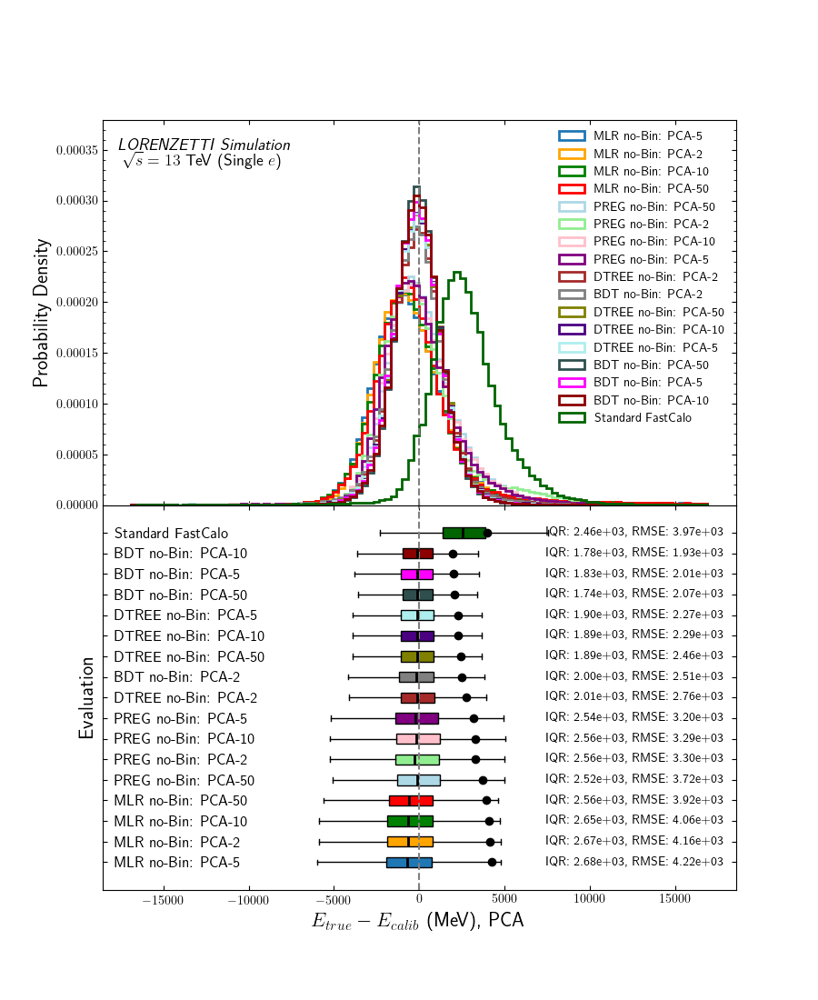

comparison_by_family_ica_cell747_01.png


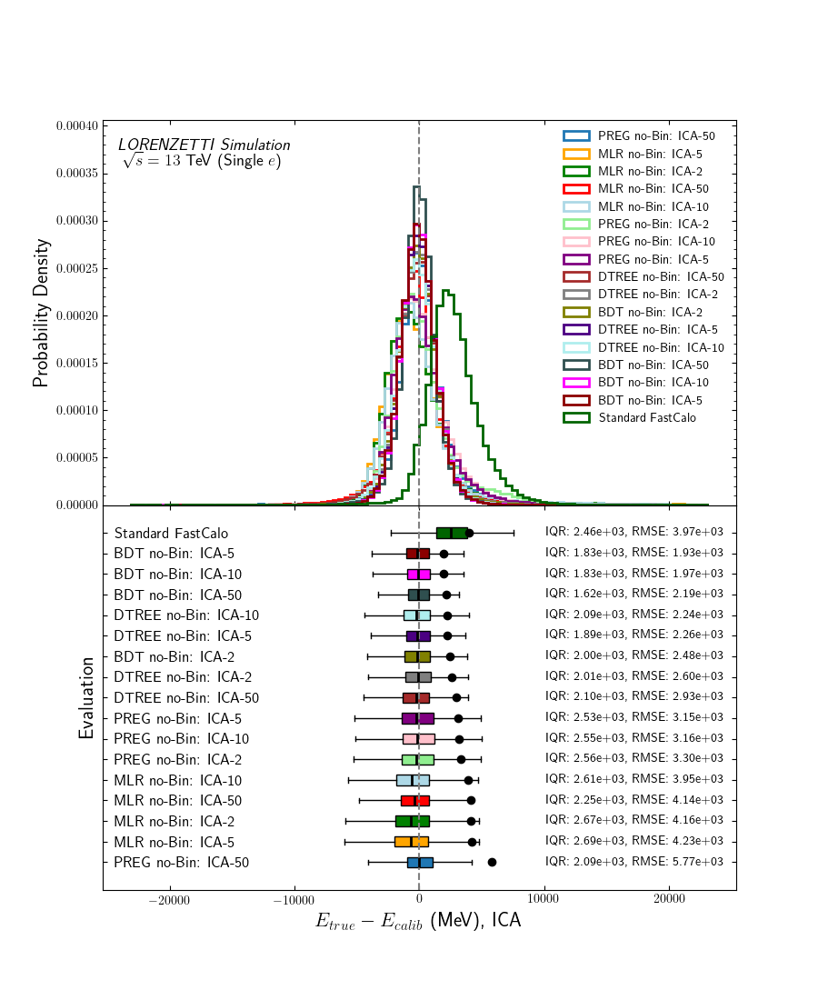

processing_times_cell708_01.png


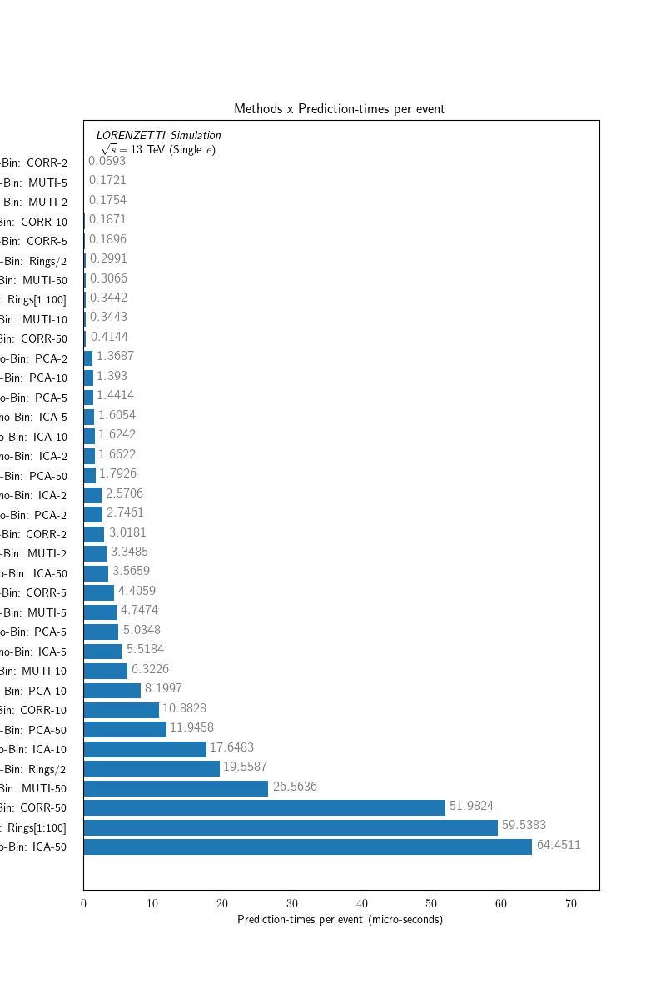

d0_vs_prediction_time_cell713_01.png


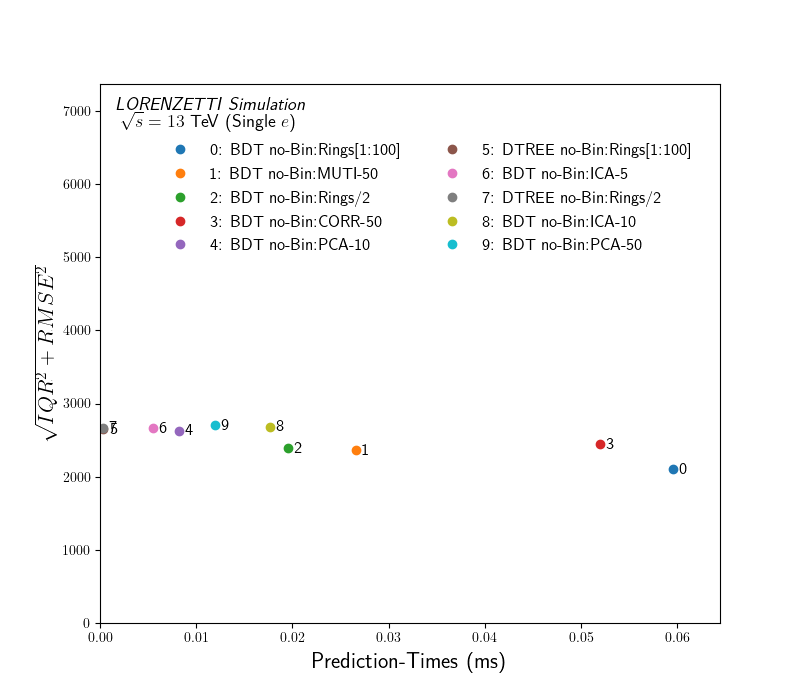

d0_vs_feature_count_cell722_01.png


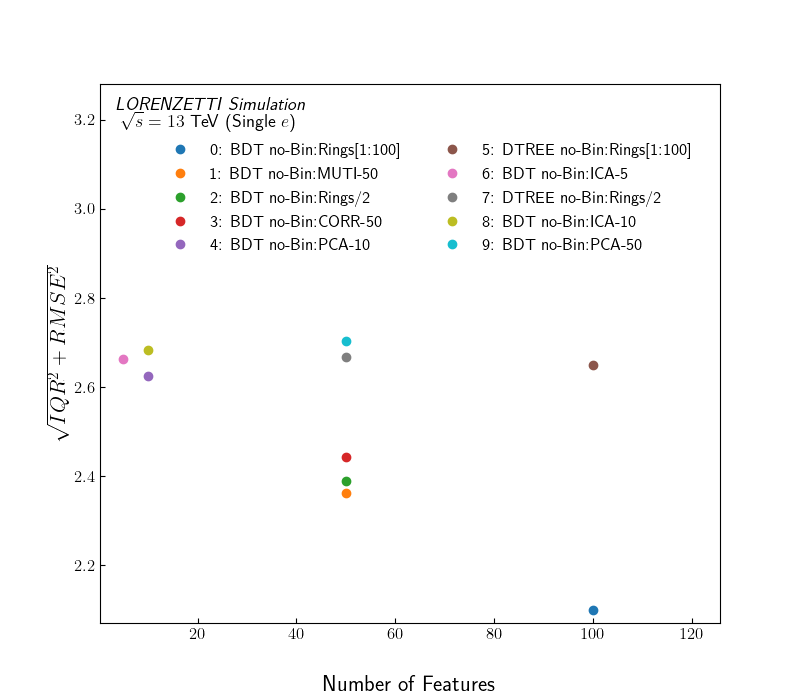

D0_ranked_cell733_01.png


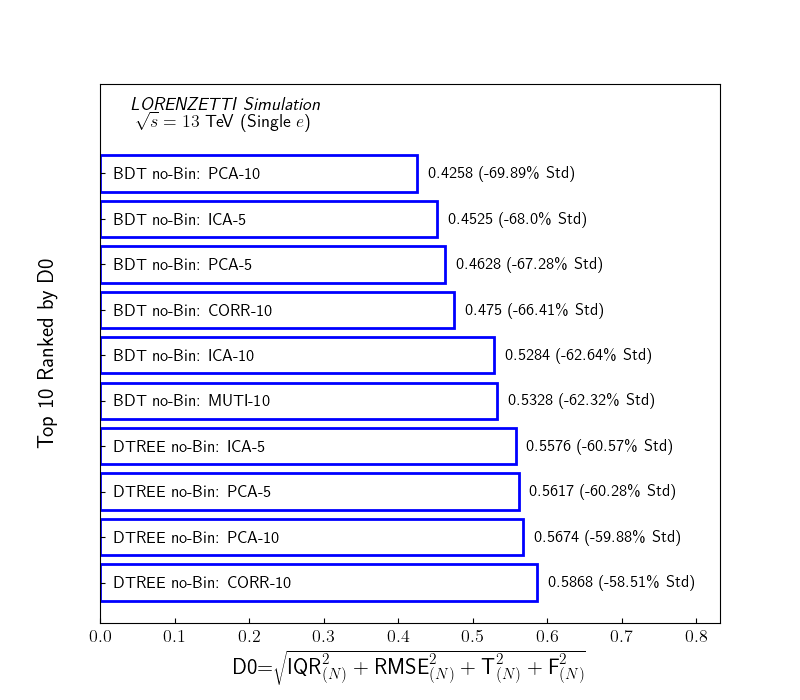

d0_ordered_by_D0_cell734_01.png


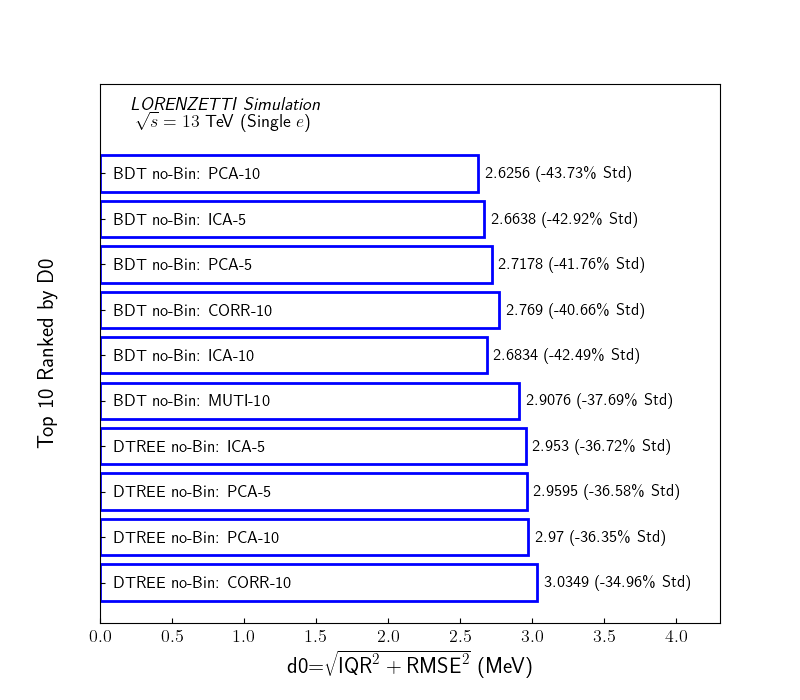

D0_ordered_by_d0_cell735_01.png


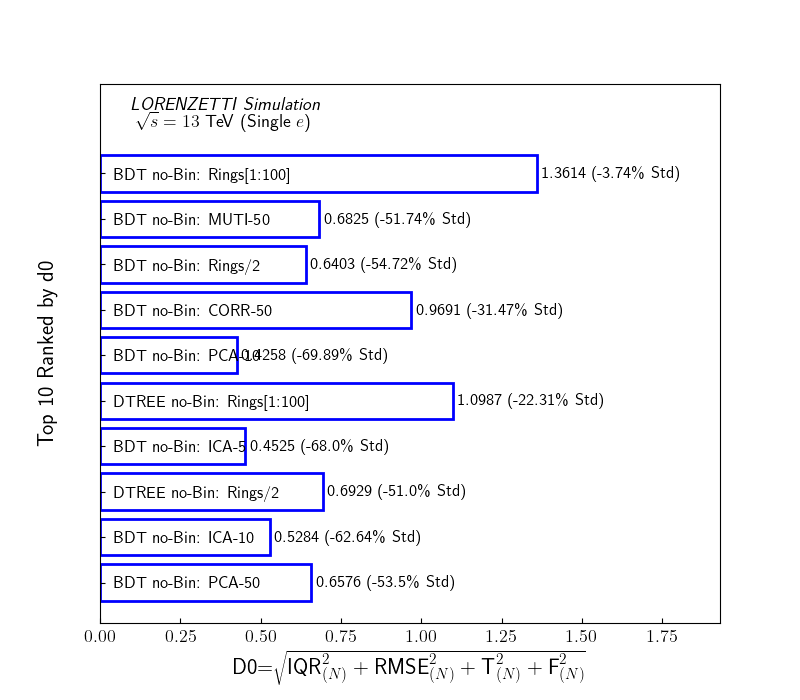

top_ten_by_d0_cells756_757_01.png


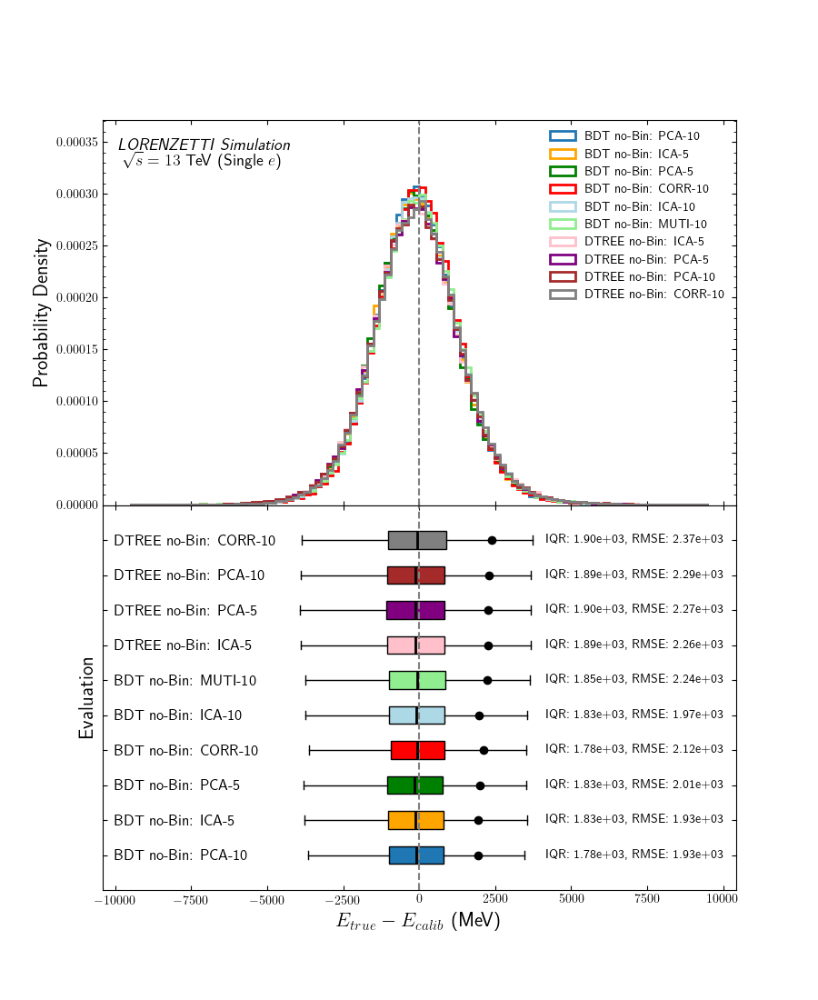

paired_difference_qq_cell789_01.png


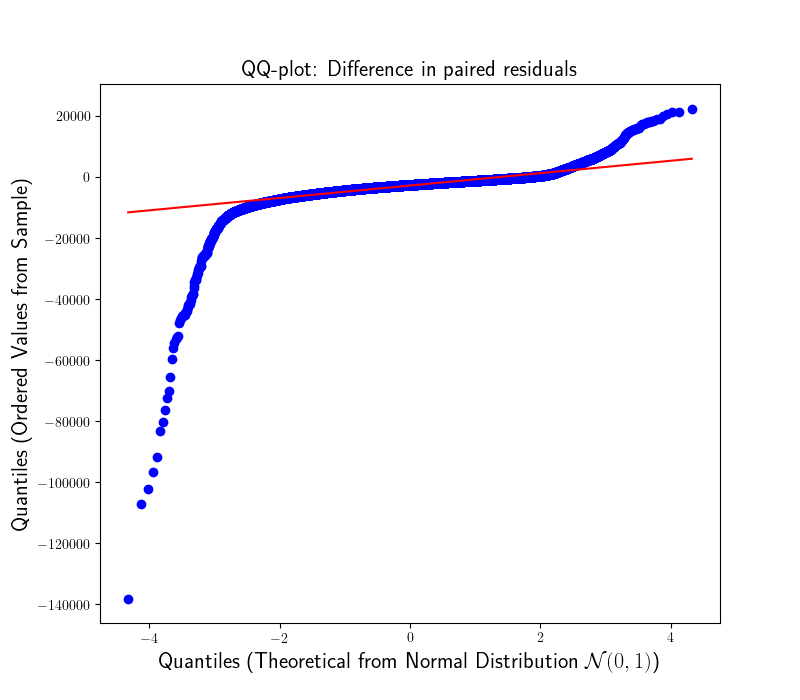

paired_qq_001_cell805_01.png


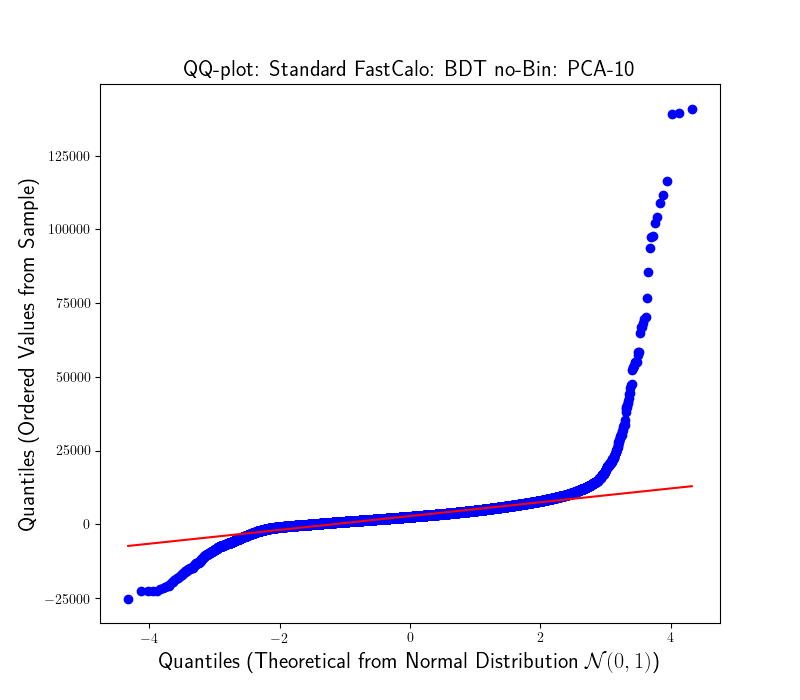

paired_qq_001_cell805_02.png


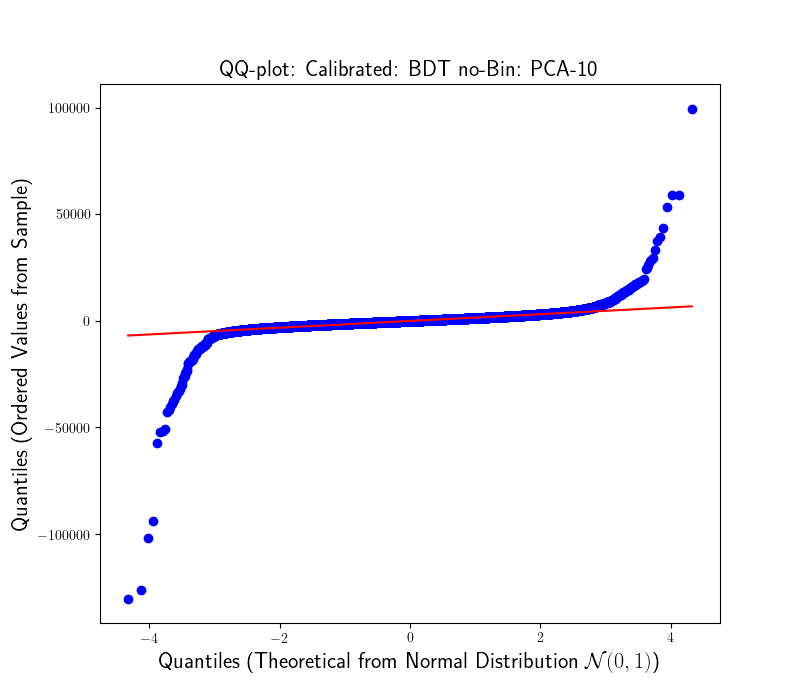

paired_qq_001_cell805_03.png


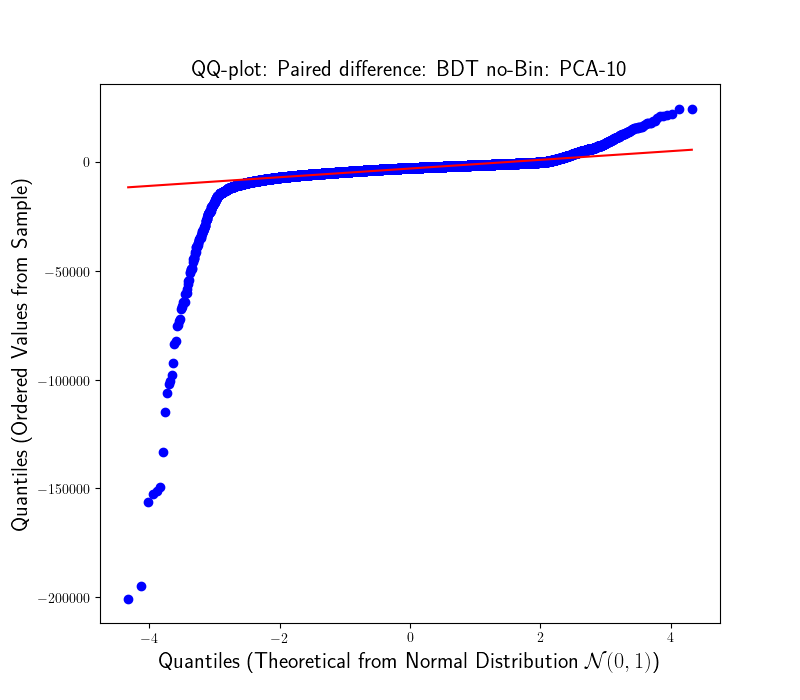

paired_qq_002_cell805_01.png


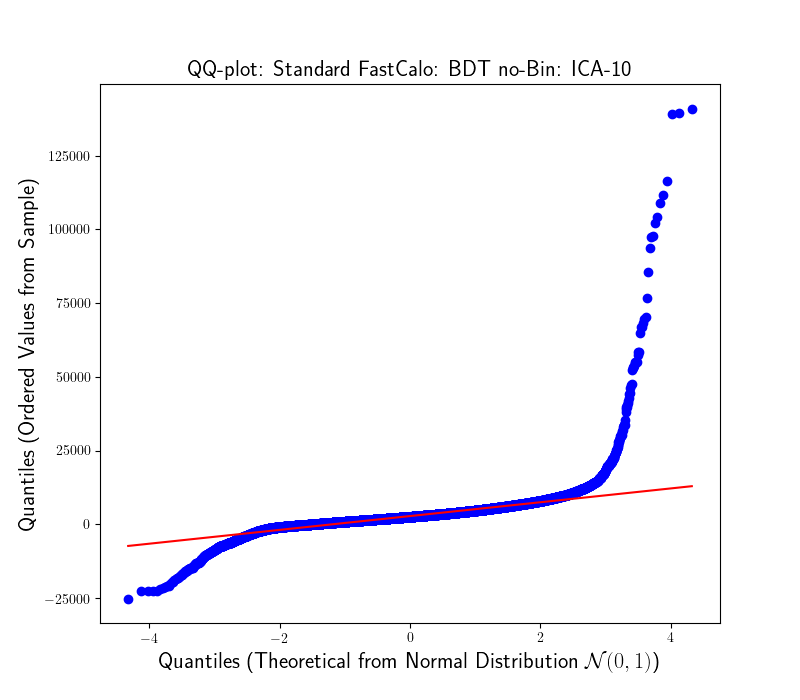

paired_qq_002_cell805_02.png


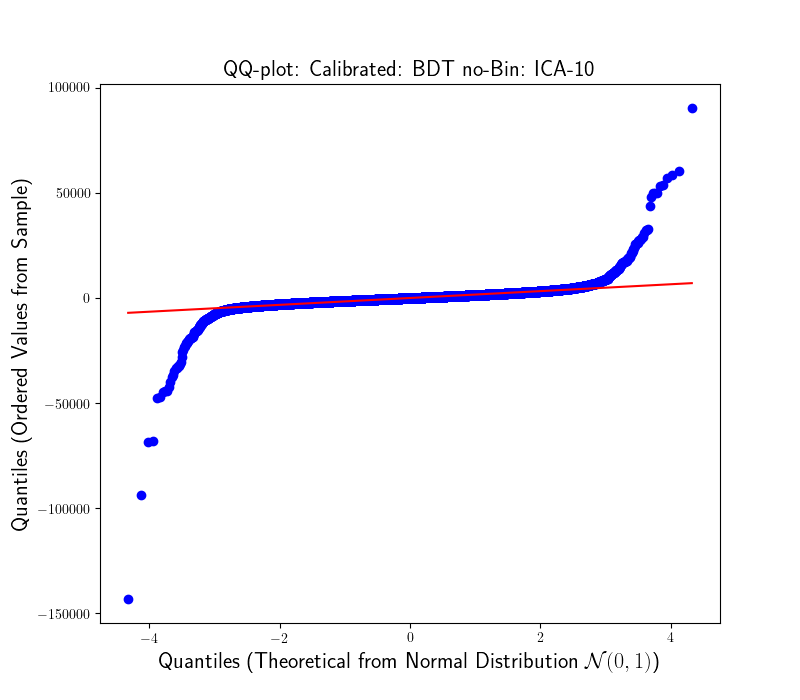

paired_qq_002_cell805_03.png


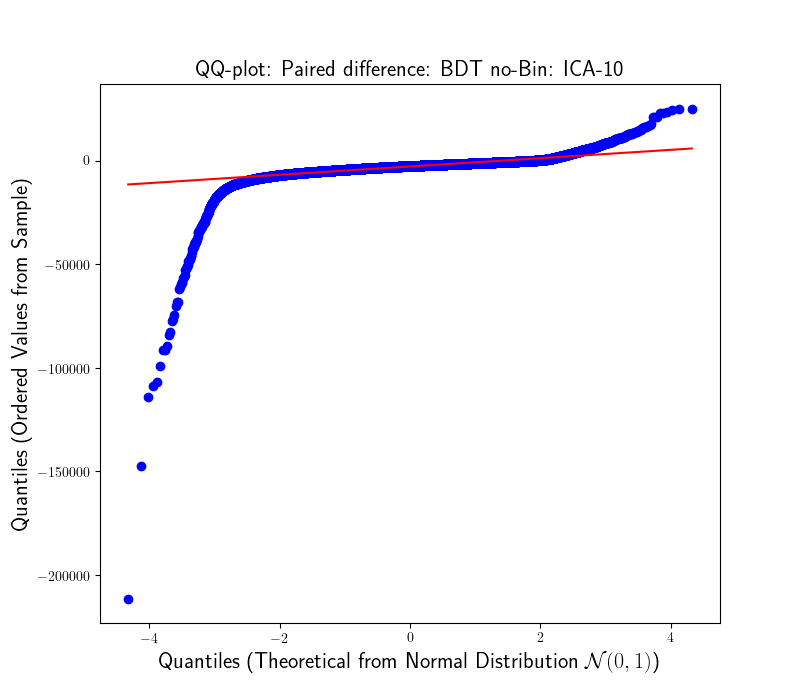

resolution_with_uncertainty_cell816_01.png


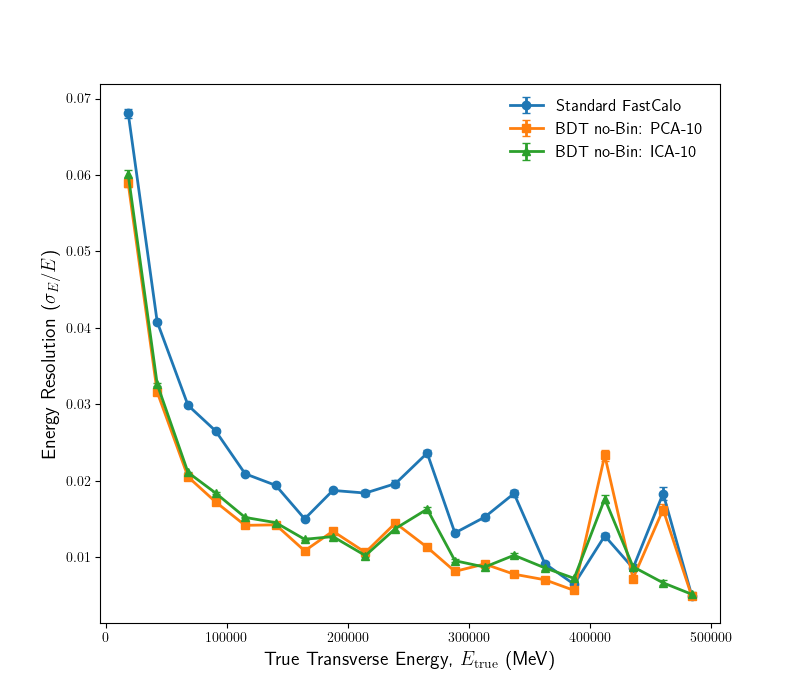

Displayed image files: 125


In [6]:
# Display every available data-generated panel by its article figure number.
# Original figure size, fonts, legends and color schemes come from source code.
from IPython.display import display, Image, Markdown
from pathlib import Path
FIGURE_ROWS=PAPER_REPORT['coverage']
seen=set()
for _,figure in FIGURE_ROWS.iterrows():
    display(Markdown(f"### Figure {int(figure['figure'])} — {figure['description']}"))
    if figure['status'] != 'generated':
        print('Status:', figure['status'])
        print('Unresolved inputs:', figure['missing_source_groups'])
    if figure['files']:
        for file in figure['files'].split(' | '):
            path=PLOT_OUTPUT/file
            if path.is_file():
                display(Image(filename=str(path)))
                seen.add(path.resolve())
# All other experimental configurations are still accessible; no models are
# silently dropped simply because they are not featured in the paper.
MORE_FIGURES=[p for p in PAPER_REPORT['files'] if p.resolve() not in seen]
if MORE_FIGURES:
    display(Markdown('### Additional archived configurations'))
    for path in MORE_FIGURES:
        print(path.name)
        display(Image(filename=str(path)))
print('Displayed image files:',len(PAPER_REPORT['files']))


## 6. Figure coverage and reproducibility checks


In [7]:
# A paper result figure is complete only when all its required source groups exist.
display(PAPER_REPORT['coverage'])
remaining=PAPER_REPORT['coverage'].query("status != 'generated'")
if len(remaining):
    display(Markdown(f"**{len(remaining)} paper figures have missing or partial inputs.**"))
    display(remaining[['figure','description','status','missing_source_groups','error']])
else:
    print('Every indexed paper result figure was produced from archived predictions and/or source events.')
print('Coverage index:', PLOT_OUTPUT/'paper_figure_coverage.csv')
print('Generated PNGs:',len(PAPER_REPORT['files']))
if not PAPER_REPORT['files']:
    raise FileNotFoundError('No figures generated. Inspect the saved result pickle directory and Lorenzetti dataset path.')


,paper,figure,description,status,files,missing_source_groups,error
0,tns,4,Energy distributions and true/fast scatter,generated,source_diagnostics\original_true_fast_histogra...,,
1,tns,5,Standardized error and distribution goodness-o...,generated,source_diagnostics\original_standardized_error...,,
2,tns,6,True calibration factor vs eta and ET,generated,source_diagnostics\original_true_alpha_eta_01....,,
3,tns,7,100 ring distributions,generated,source_diagnostics\original_100_ring_boxplot_0...,,
4,tns,8,"CORR, MI, PCA and ICA feature map",generated,source_diagnostics\original_feature_relevance_...,,
5,tns,9,Calibrated energy residual distributions,generated,trained_model_figures\original_hist_boxplot_co...,,
6,tns,10,Top-ten accuracy/cost/complexity trade-off,generated,trained_model_figures\paper_stage1_iqr_rmse_01...,,
7,tns,11,IQR of calibration factor in eta and ET,generated,trained_model_figures\original_segmented_01.pn...,,
8,tns,12,MAE and RMSE of calibration factor in eta and ET,generated,trained_model_figures\original_segmented_03.pn...,,
9,tns,13,Calibration factor regional boxplots,generated,trained_model_figures\original_segmented_boxpl...,,


Every indexed paper result figure was produced from archived predictions and/or source events.
Coverage index: C:\Users\paulo\Documents\PAULO-PYTHON-PROGRAMS\DOUTORADO\GBDTE\Lorenzetti-Shower-Simulation\results\replayed\tns\paper_figures\paper_figure_coverage.csv
Generated PNGs: 125
